# 02. Training & comparison
All input combinations of the multi-input CNN (image / landmark / Z-features) and ImageNet-pretrained baselines, evaluated on the same test set (n = 4,742).

In [1]:

#이미지 - 랜드마크 - z_value - 유클리드 거리:
#이미지 랜마//유클리드//제트
from google.colab import drive
drive.mount('/content/drive')
!pip install imblearn
# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, TensorBoard
# 감정 레이블 정의
import numpy as np
import random
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score, roc_curve, auc
import pandas as pd


Mounted at /content/drive


## Settings
### Seed

In [2]:
# 시드 설정
import tensorflow as tf
import numpy as np
import random

seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

### Epochs

In [3]:
epochs = 100

### Batch size (32 / 64 / 128 compared; 32 best)

In [4]:
batch_size =32
# batch_size =16

### Early-stopping patience

In [5]:
patience_es = 10

### LR scheduler (factor, patience)

In [6]:
factor_lr = 0.5
patience_lr = 5

### Learning rate (combined model)

In [7]:
learning_rate_combined = 0.0001

## Image only

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Model: "functional_10"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_16            │ (None, 64, 64, 1)      │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_88 (Conv2D)        │ (None, 64, 64, 64)     │            640 │ input_layer_16[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_112   │ (None, 64, 64, 64)     │            256 │ conv2d_88[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼─

 Total params: 7,096,071 (27.07 MB)


 Trainable params: 7,089,031 (27.04 MB)


...

Epoch 1/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 84s 28ms/step - accuracy: 0.1830 - loss: 0.6308 - val_accuracy: 0.4084 - val_loss: 0.3211 - learning_rate: 5.0000e-04
Epoch 2/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 50s 21ms/step - accuracy: 0.3943 - loss: 0.4333 - val_accuracy: 0.5367 - val_loss: 0.2269 - learning_rate: 5.0000e-04
Epoch 3/200
...
Epoch 8/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 49s 21ms/step - accuracy: 0.6665 - loss: 0.1477 - val_accuracy: 0.6387 - val_loss: 0.1664 - learning_rate: 5.0000e-04
Epoch 9/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 49s 21ms/step - accuracy: 0.6846 - loss: 0.1395 - val_accuracy: 0.6752 - val_loss: 0.1485 - learning_rate: 5.0000e-04
Epoch 10/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 49s 21ms/step - accuracy: 0.6935 - loss: 0.1336 - val_accuracy: 0.6736 - val_loss: 0.1470 - learning_rate: 5.0000e-04
Epoch 11/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 49s 21ms/step - accuracy: 0.7048 - loss: 0.1280 - val_accuracy: 0.6791 - val_loss: 0.1442 - learning_rate: 5.0000e-04
Epoch 12/200
221

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_462
Received: inputs=('Tensor(shape=(32, 64, 64, 1))',)
  warnings.warn(msg)


148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_462
Received: inputs=('Tensor(shape=(None, 64, 64, 1))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step
Accuracy for happy: 0.96
Accuracy for sad: 0.79
Accuracy for anger: 0.68
Accuracy for surprise: 0.76
Accuracy for disgust: 0.32
Accuracy for neutral: 0.93
Accuracy for fear: 0.37
Precision: 0.68
Recall: 0.69
F1 Score: 0.67
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Image Only ROC AUC Score: 0.92


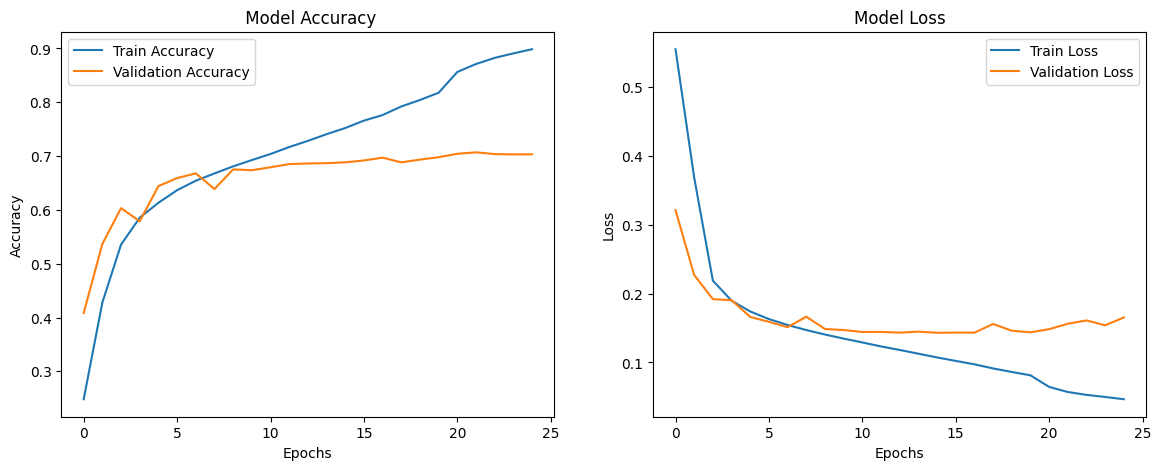

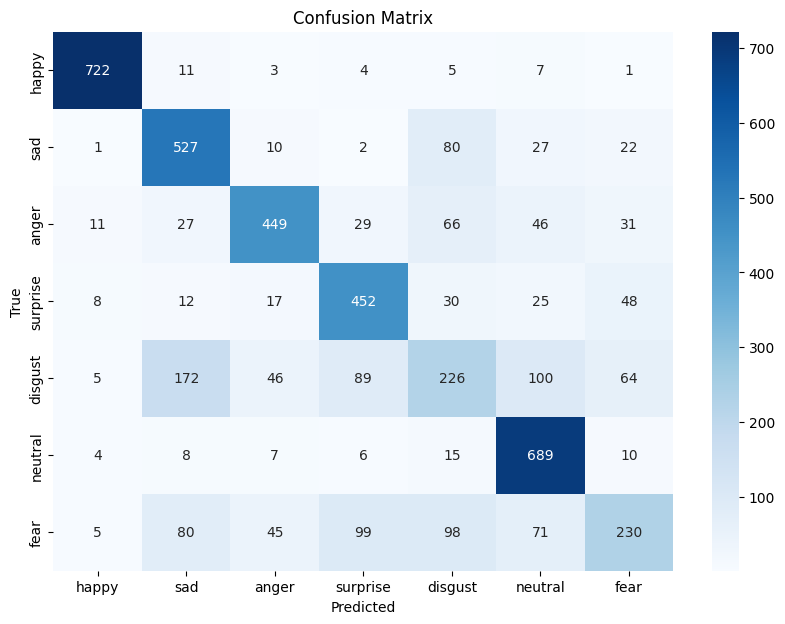

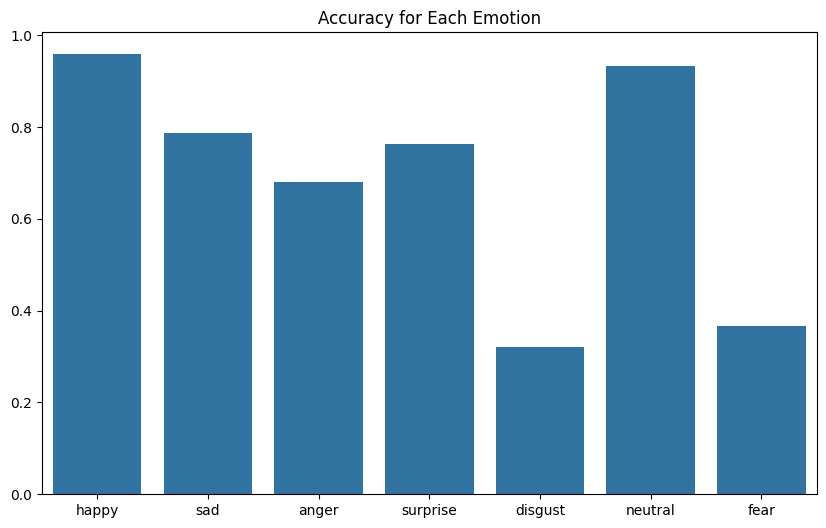

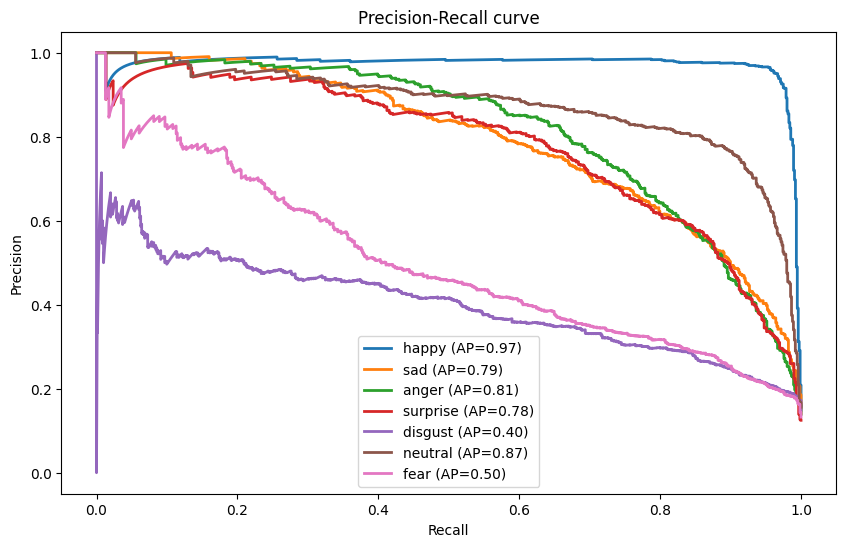

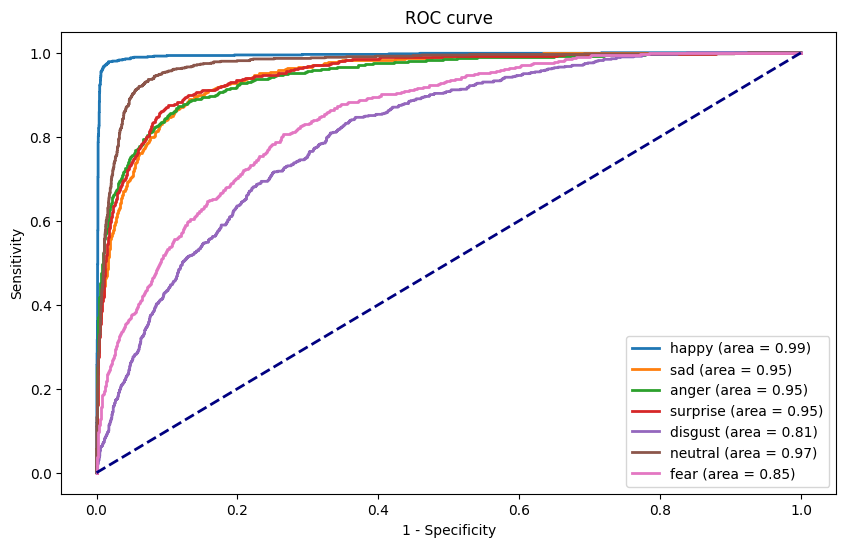

In [ ]:
#이미지 - 랜드마크 - z_value - 유클리드 거리:
#이미지 랜마//유클리드//제트
from google.colab import drive
drive.mount('/content/drive')


# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, TensorBoard
from tensorflow.keras.layers import Add


# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Dense, Dropout, BatchNormalization,
                                     Conv2D, MaxPooling2D, Flatten, Activation, Concatenate)
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import itertools
from tensorflow.keras.regularizers import l2
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, TensorBoard
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score, roc_curve, auc
import pandas as pd

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}
model_name = 'Image Only'
learning_rate_combined = 5e-4
epochs = 200
factor_lr = 0.5
patience_lr = 5
patience_es = 10

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.cast(image, tf.float32) / 255.0  # ✅ 정규화 추가
    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    return image, label


# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"

train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)


# 모델 정의
image_shape = (64, 64, 1)  # 이미지 데이터의 형태

model_image_input = Input(shape=image_shape)  # 이미지 입력

# 입력 레이어
# 랜드마크와 유클리드 거리 서브넷

# 이미지 서브넷
# 🟢 이미지 서브넷 (Residual 블록 최적화)
x_image = Conv2D(64, (3,3), padding='same', kernel_initializer='he_normal')(model_image_input)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

x_image = Conv2D(128, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

# 🔥 256 필터 3단계 Residual 블록 적용
for _ in range(3):
    shortcut = x_image  # 기존 연결 유지
    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)
    x_image = Activation('relu')(x_image)

    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)

    # 📌 Projection Shortcut (1x1 Conv)
    shortcut = Conv2D(256, (1,1), padding='same', kernel_initializer='he_normal')(shortcut)
    shortcut = BatchNormalization()(shortcut)

    # 🔥 Add() 연결
    x_image = Add()([x_image, shortcut])
    x_image = Activation('relu')(x_image)
    x_image = Dropout(0.3)(x_image)

x_image = MaxPooling2D((2,2))(x_image)

# 🔥 512 필터 CNN 추가
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.5)(x_image)

x_image = Flatten()(x_image)

# 출력 레이어
model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.001))(x_image)

# 모델 정의
model_combined = Model(inputs= model_image_input, outputs=model_output)


# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)

import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []


y_test = []

for image, label in test_dataset:
    test_images.append(image)
    y_test.extend(label.numpy())

y_test_pred = model_combined.predict([np.vstack(test_images)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)


## Landmark only

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Model: "functional_3"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)           │ (None, 303)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 101)                 │          30,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_27               │ (None, 101)                 │             404 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_20 (Activation)           │ (None, 101)                 │               0 │
├────────────────────

 Total params: 40,331 (157.54 KB)


 Trainable params: 39,937 (156.00 KB)


 Non-trainable params: 394 (1.54 KB)


Epoch 1/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - accuracy: 0.3363 - loss: 0.6198 - val_accuracy: 0.2186 - val_loss: 0.5855 - learning_rate: 5.0000e-04
Epoch 2/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.4361 - loss: 0.3153 - val_accuracy: 0.3271 - val_loss: 0.3694 - learning_rate: 5.0000e-04
Epoch 3/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.4534 - loss: 0.2617 - val_accuracy: 0.3374 - val_loss: 0.3358 - learning_rate: 5.0000e-04
Epoch 4/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.4549 - loss: 0.2528 - val_accuracy: 0.2059 - val_loss: 0.4722 - learning_rate: 5.0000e-04
Epoch 5/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.4577 - loss: 0.2488 - val_accuracy: 0.2853 - val_loss: 0.3842 - learning_rate: 5.0000e-04
Epoch 6/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.4598 - loss: 0.2475 - val_accuracy: 0.2529 - val_loss: 0.4283 - learning_rate: 5.0000e-04
Epoch 7/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 8s

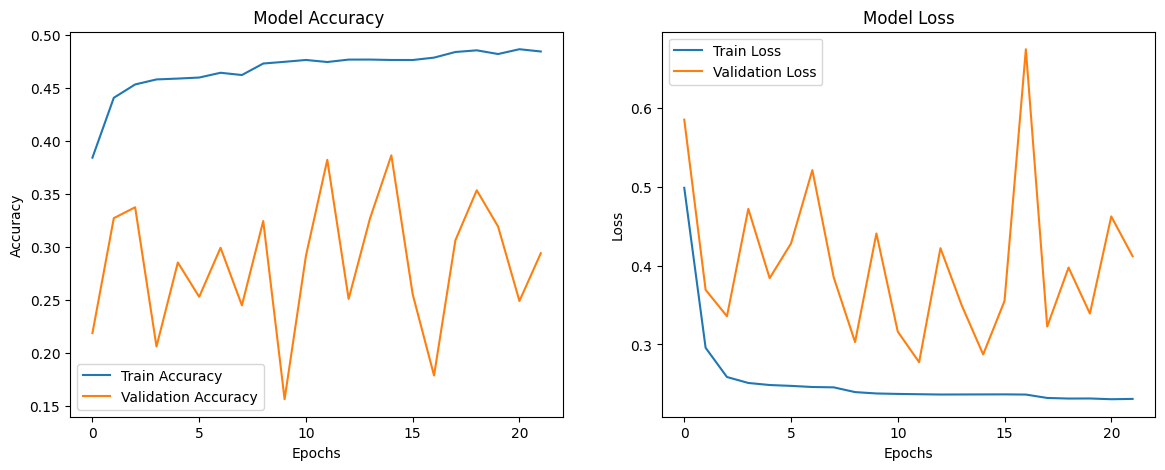

149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4588 - loss: 0.2327
Test Loss: 0.2787686288356781
Test Accuracy: 0.37283846735954285


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_109
Received: inputs=('Tensor(shape=(32, 303))',)
  warnings.warn(msg)


143/149 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_109
Received: inputs=('Tensor(shape=(None, 303))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


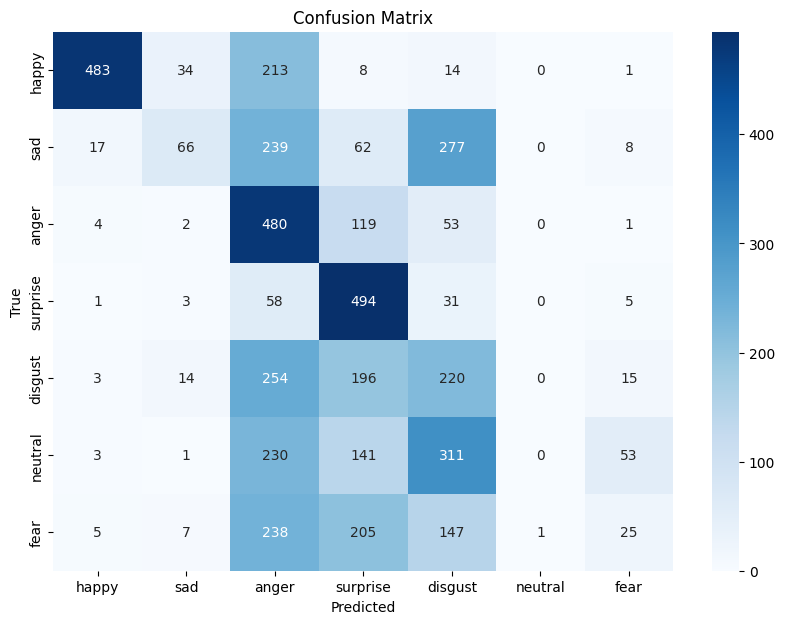

Accuracy for happy: 0.64
Accuracy for sad: 0.10
Accuracy for anger: 0.73
Accuracy for surprise: 0.83
Accuracy for disgust: 0.31
Accuracy for neutral: 0.00
Accuracy for fear: 0.04


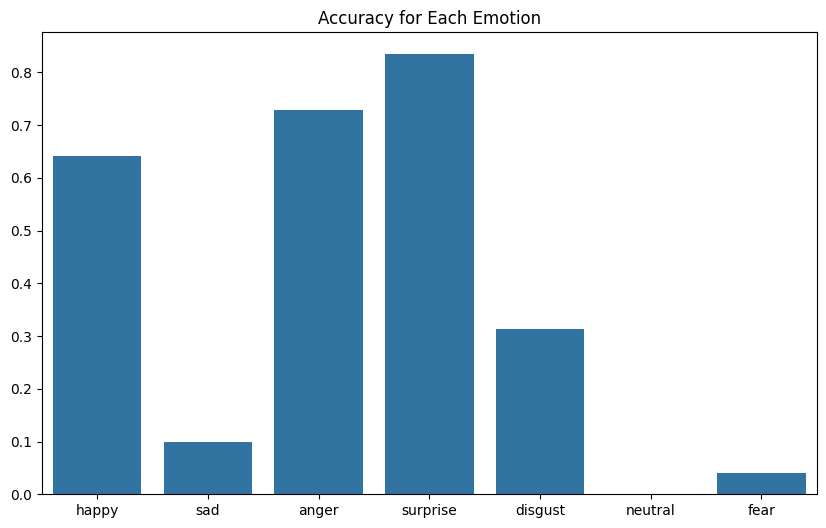

Precision: 0.37
Recall: 0.38
F1 Score: 0.31
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Landmark Only ROC AUC Score: 0.80


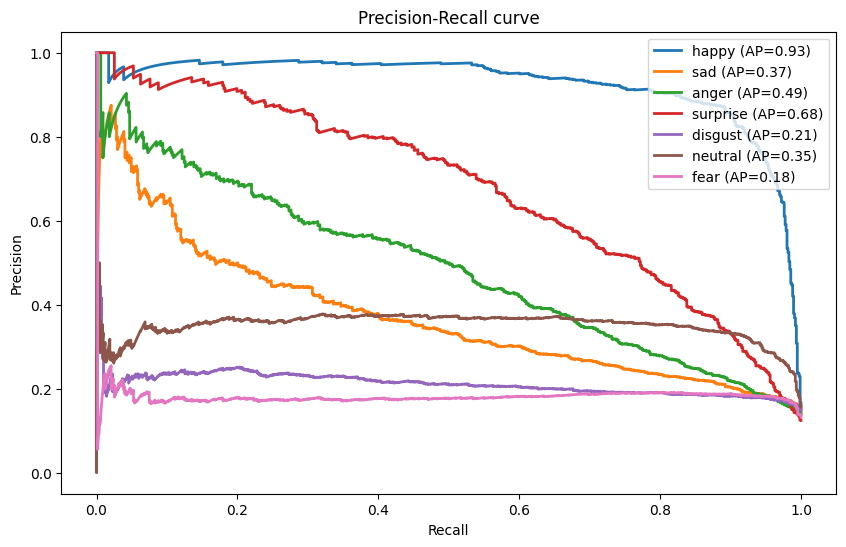

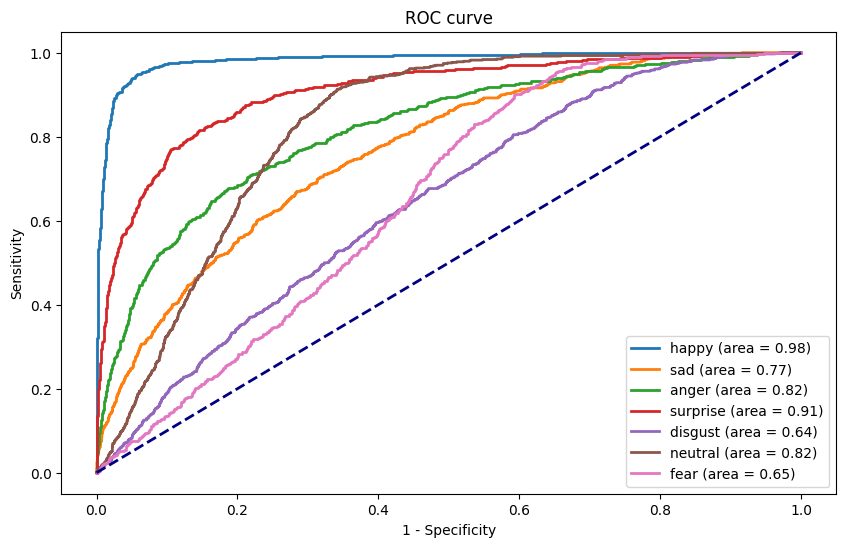

In [ ]:
#이미지 - 랜드마크 - z_value - 유클리드 거리:
#이미지 랜마//유클리드//제트
from google.colab import drive
drive.mount('/content/drive')

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ModelCheckpoint, TensorBoard

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}
model_name = 'Landmark Only'
# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks



def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

learning_rate_combined = 5e-4
epochs = 200
factor_lr = 0.5
patience_lr = 5
patience_es = 10


# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))


    return  selected_landmarks, label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset



train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)



# 모델 정의
input_dim = 303  # 랜드마크 데이터의 차원


model_landmark_input = Input(shape=(input_dim,))  # 랜드마크 입력



# 랜드마크 서브넷
# 랜드마크 서브넷
# 랜드마크 서브넷
x_landmark = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_landmark_input)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(64, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(32, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)


num_classes = 7  # 분류할 클래스 수
x_landmark = Dense(num_classes, activation='softmax', kernel_initializer='he_normal')(x_landmark)

# 모델 정의
model_combined = Model(inputs=model_landmark_input, outputs=x_landmark)

# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)


# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)

import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, auc, precision_recall_curve, average_precision_score

# Assuming you have already defined variables like drive_path, model_name, history, test_dataset, emotion_labels, etc.

accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)
plt.show()

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_landmarks = []
y_test = []

for landmark, label in test_dataset:
    test_landmarks.append(landmark)
    y_test.extend(label.numpy())

y_test_pred = model_combined.predict([np.vstack(test_landmarks)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)
plt.show()

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)
plt.show()

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_landmarks)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)
plt.show()

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)
plt.show()

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)



## Z-features only

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Model: "functional_4"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)           │ (None, 56)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 101)                 │           5,757 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_30               │ (None, 101)                 │             404 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_23 (Activation)           │ (None, 101)                 │               0 │
├────────────────────

 Total params: 6,875 (26.86 KB)


 Trainable params: 6,673 (26.07 KB)


...

2219/2219 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step - accuracy: 0.3127 - loss: 0.4162 - val_accuracy: 0.4613 - val_loss: 0.2760 - learning_rate: 5.0000e-04
Epoch 2/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.4078 - loss: 0.2913 - val_accuracy: 0.4649 - val_loss: 0.2636 - learning_rate: 5.0000e-04
Epoch 3/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.4183 - loss: 0.2763 - val_accuracy: 0.4568 - val_loss: 0.2632 - learning_rate: 5.0000e-04
...
Epoch 88/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.4623 - loss: 0.2401 - val_accuracy: 0.4906 - val_loss: 0.2296 - learning_rate: 1.0000e-06
Epoch 89/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.4629 - loss: 0.2409 - val_accuracy: 0.4904 - val_loss: 0.2302 - learning_rate: 1.0000e-06
Epoch 90/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step - accuracy: 0.4630 - loss: 0.2409 - val_accuracy: 0.4898 - val_loss: 0.2305 - learning_rate: 1.0000e-06
Epoch 91/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 1

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_123
Received: inputs=('Tensor(shape=(32, 56))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_123
Received: inputs=('Tensor(shape=(None, 56))',)
  warnings.warn(msg)


Accuracy for happy: 0.91
Accuracy for sad: 0.35
Accuracy for anger: 0.49
Accuracy for surprise: 0.69
Accuracy for disgust: 0.14
Accuracy for neutral: 0.70
Accuracy for fear: 0.17
Precision: 0.47
Recall: 0.49
F1 Score: 0.47
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
ZValue Only ROC AUC Score: 0.82


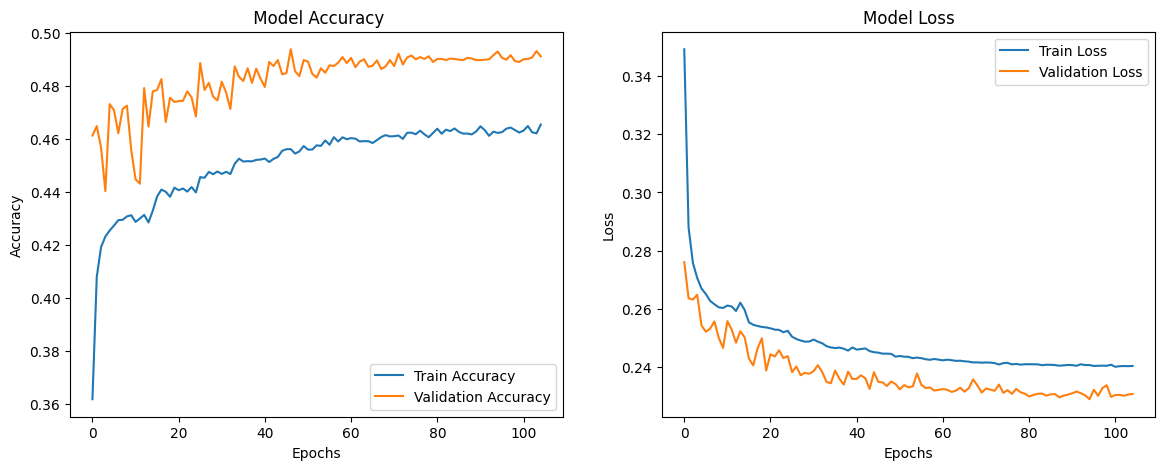

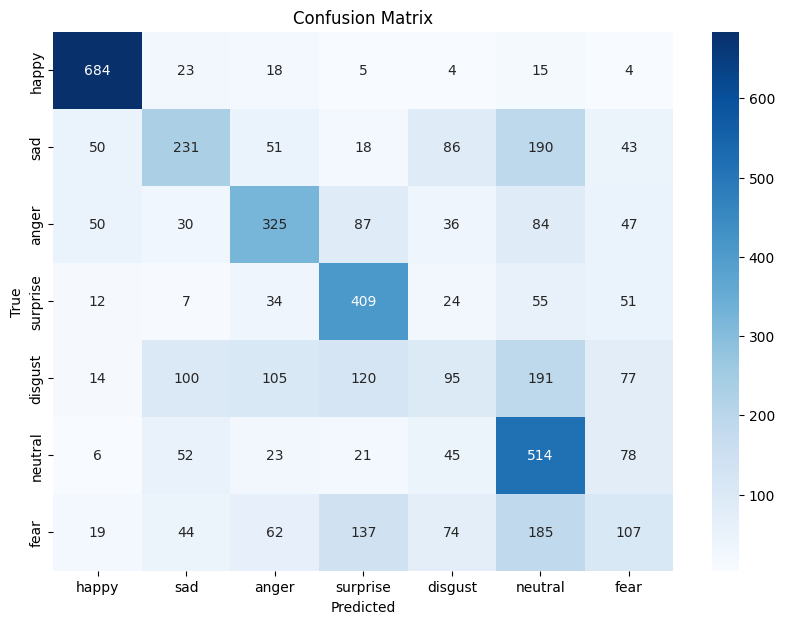

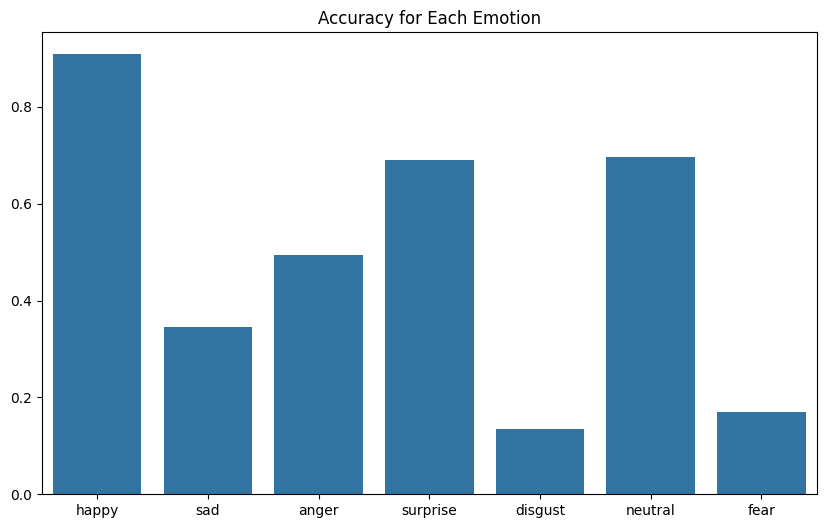

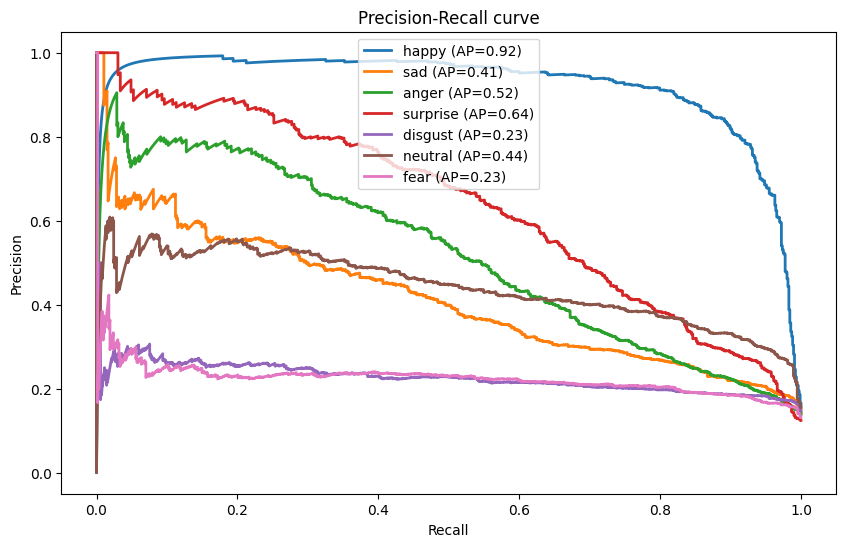

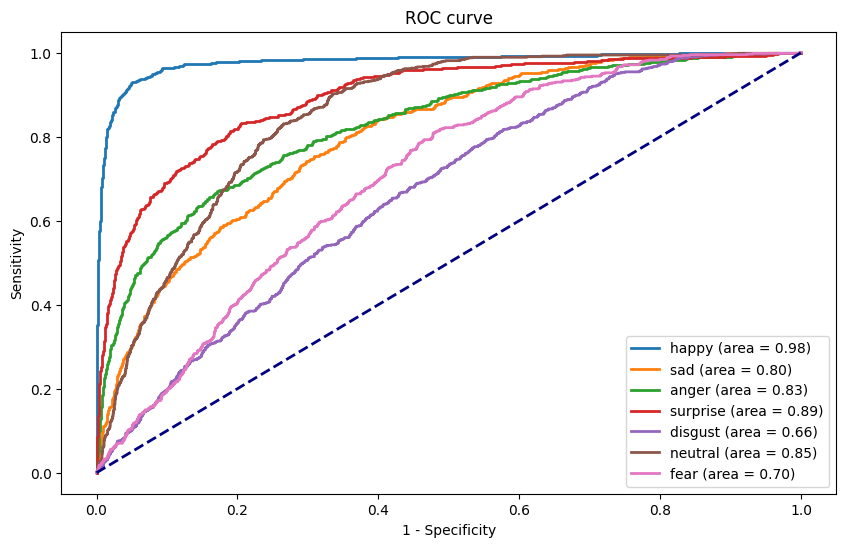

In [ ]:
#오후 3시 8분 수정코드 !! 입력 따로 받기 해놓음

from google.colab import drive
drive.mount('/content/drive')

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}
model_name = 'ZValue Only'

# Define landmark indices
# Define a function to extract selected landmarks
learning_rate_combined = 5e-4
epochs = 200
factor_lr = 0.5
patience_lr = 5
patience_es = 10

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return z_product_combinations, label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)

# 모델 정의
# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

# 1-D CNN 모델 구성
model_z_input = Input(shape=(z_comb_dim,))  # 1차원 데이터 입력 (1차원 배열 형태)

# 완전 연결 레이어
x_z = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_z_input)
x_z = BatchNormalization()(x_z)
x_z = Activation('elu')(x_z)
x_z = Dropout(0.2)(x_z)


model_output = Dense(len(emotion_labels), activation='softmax')(x_z)

# 모델 정의
model_combined = Model(inputs=model_z_input, outputs=model_output)

# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)


# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)


import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_z_values = []

y_test = []

for  z_value, label in test_dataset:
    y_test.extend(label.numpy())
    test_z_values.append(z_value)

y_test_pred = model_combined.predict([np.vstack(test_z_values)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_z_values)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)

## Image + Landmark

Model: "functional_11"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_18            │ (None, 64, 64, 1)      │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_101 (Conv2D)       │ (None, 64, 64, 64)     │            640 │ input_layer_18[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_125   │ (None, 64, 64, 64)     │            256 │ conv2d_101[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼─

 Total params: 8,133,035 (31.03 MB)


 Trainable params: 8,125,345 (31.00 MB)


 Non-trainable params: 7,690 (30.04 KB)


Epoch 1/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 93s 29ms/step - accuracy: 0.2689 - loss: 1.3827 - val_accuracy: 0.1950 - val_loss: 0.5640 - learning_rate: 5.0000e-04
Epoch 2/200
   1/2218 ━━━━━━━━━━━━━━━━━━━━ 54s 24ms/step - accuracy: 0.3125 - loss: 0.4253

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2218/2218 ━━━━━━━━━━━━━━━━━━━━ 1s 638us/step - accuracy: 0.3125 - loss: 0.4253 - val_accuracy: 0.1955 - val_loss: 0.5857 - learning_rate: 5.0000e-04
Epoch 3/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 51s 22ms/step - accuracy: 0.4422 - loss: 0.3404 - val_accuracy: 0.4003 - val_loss: 0.3445 - learning_rate: 5.0000e-04
Epoch 4/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 1s 658us/step - accuracy: 0.5000 - loss: 0.2756 - val_accuracy: 0.4196 - val_loss: 0.3336 - learning_rate: 5.0000e-04
...
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 51s 22ms/step - accuracy: 0.8102 - loss: 0.1050 - val_accuracy: 0.7084 - val_loss: 0.1676 - learning_rate: 1.2500e-04
Epoch 40/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 1s 652us/step - accuracy: 0.7812 - loss: 0.1179 - val_accuracy: 0.7083 - val_loss: 0.1673 - learning_rate: 1.2500e-04
Epoch 41/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 51s 21ms/step - accuracy: 0.8206 - loss: 0.0978 - val_accuracy: 0.7118 - val_loss: 0.1679 - learning_rate: 1.2500e-04
Epoch 42/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 1s 636us

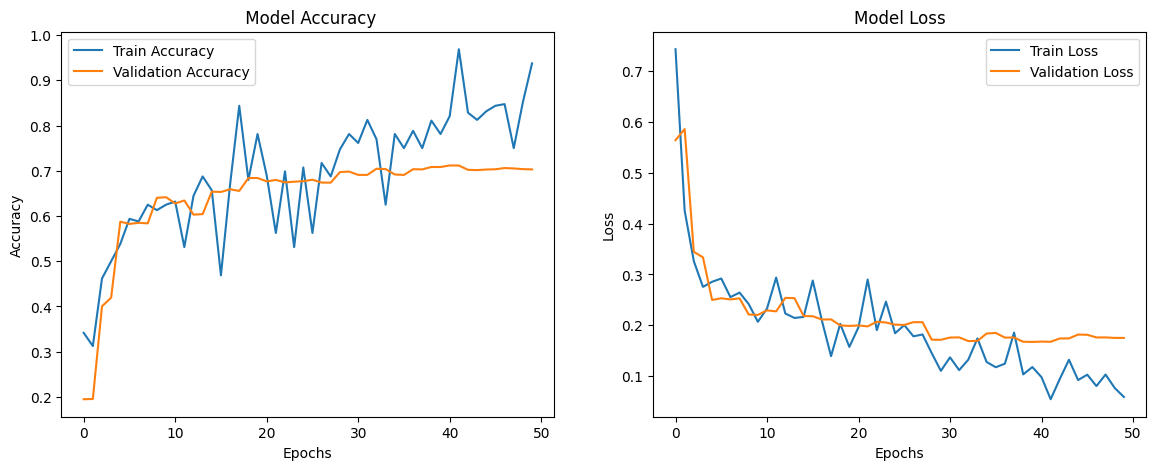

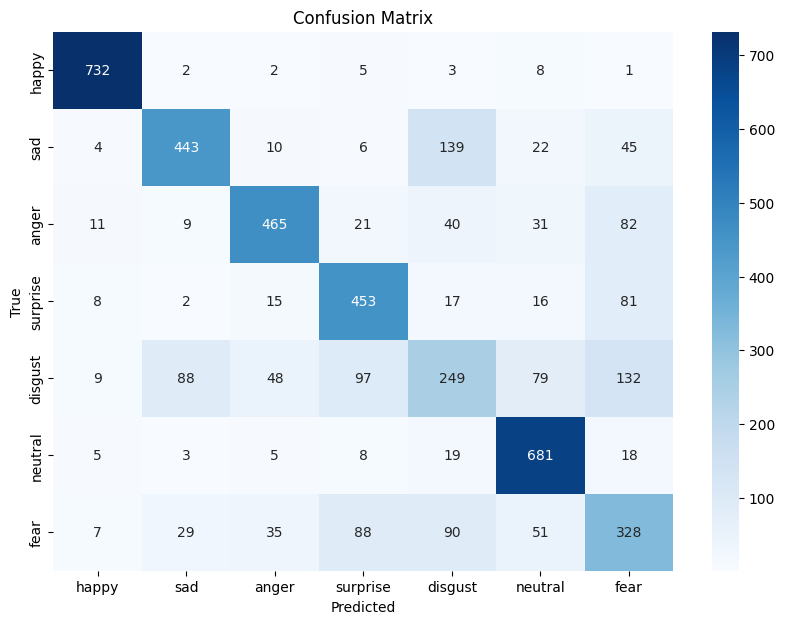

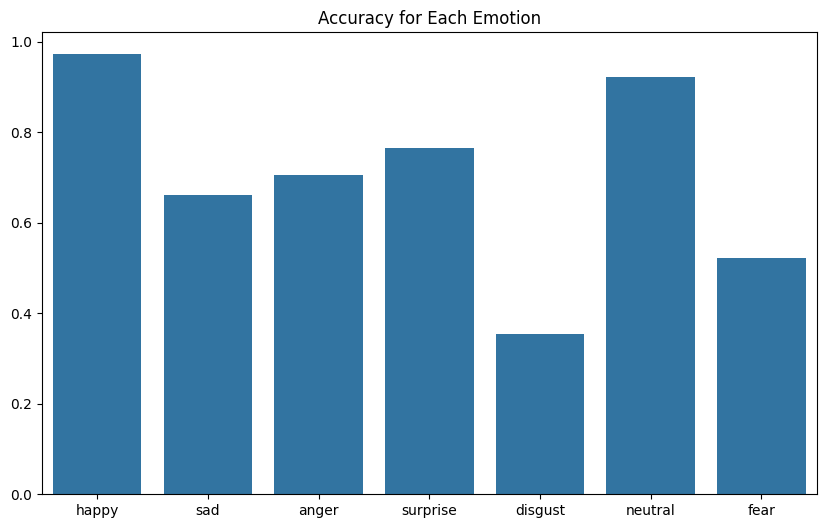

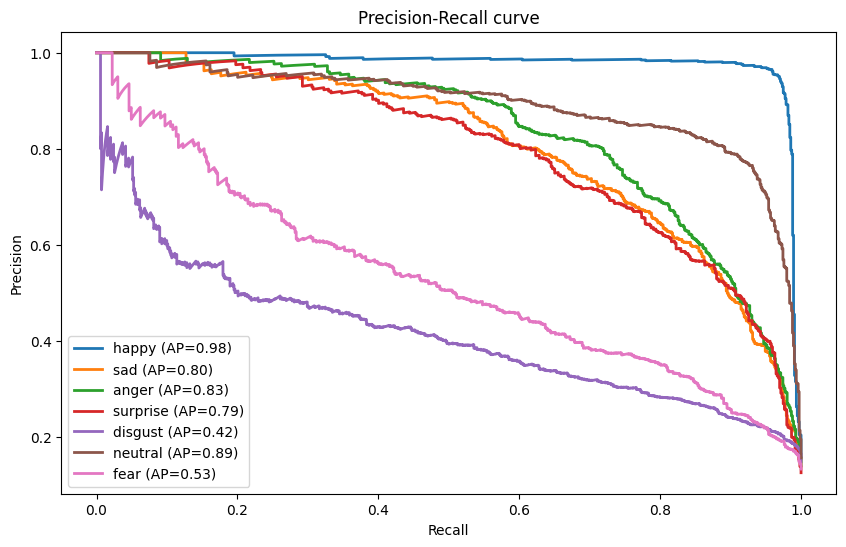

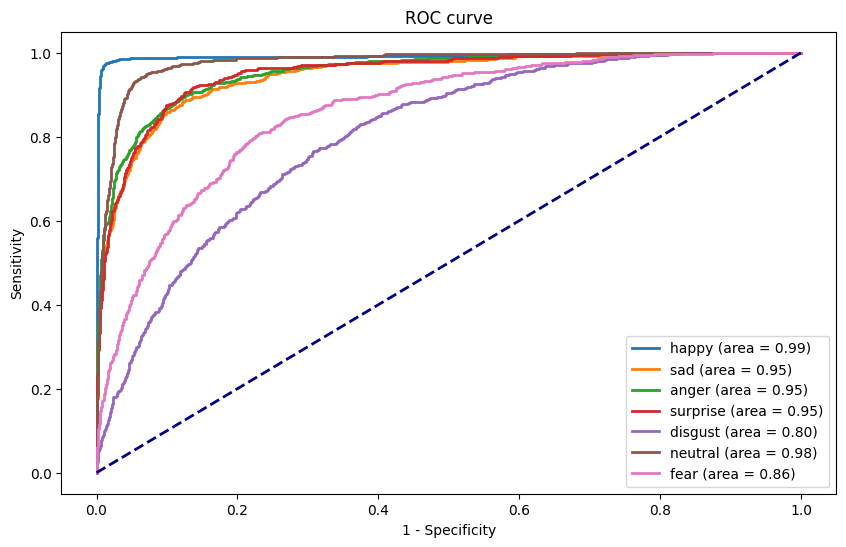

In [ ]:
#오후 3시 8분 수정코드 !! 입력 따로 받기 해놓음


# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

model_name = 'Image & Landmark'
learning_rate_combined = 5e-4
epochs = 200
factor_lr = 0.5
patience_lr = 5
patience_es = 10

# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)

    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    return (image, selected_landmarks), label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)

# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

# 모델 정의
input_dim = 303  # 랜드마크 데이터의 차원
image_shape = (64, 64, 1)  # 이미지 데이터의 형태


# 입력 레이어
model_landmark_input = Input(shape=(input_dim,))  # 랜드마크 입력
model_image_input = Input(shape=image_shape)  # 이미지 입력



# 이미지 서브넷




# 🟢 이미지 서브넷 (Residual 블록 최적화)
x_image = Conv2D(64, (3,3), padding='same', kernel_initializer='he_normal')(model_image_input)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

x_image = Conv2D(128, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

# 🔥 256 필터 3단계 Residual 블록 적용
for _ in range(3):
    shortcut = x_image  # 기존 연결 유지
    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)
    x_image = Activation('relu')(x_image)

    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)

    # 📌 Projection Shortcut (1x1 Conv)
    shortcut = Conv2D(256, (1,1), padding='same', kernel_initializer='he_normal')(shortcut)
    shortcut = BatchNormalization()(shortcut)

    # 🔥 Add() 연결
    x_image = Add()([x_image, shortcut])
    x_image = Activation('relu')(x_image)
    x_image = Dropout(0.3)(x_image)

x_image = MaxPooling2D((2,2))(x_image)

# 🔥 512 필터 CNN 추가
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.5)(x_image)

x_image = Flatten()(x_image)

# 🔥 랜드마크 서브넷 최적화
x_landmark = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_landmark_input)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(64, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(32, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

# 🔥 이미지 & 랜드마크 합치기
combined = Concatenate()([x_image, x_landmark])


combined = Dense(128, kernel_regularizer=l2(0.01))(combined)
combined = BatchNormalization()(combined)
combined = Activation('elu')(combined)
combined = Dropout(0.6)(combined)
# 출력 레이어
model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(combined)

# 모델 정의
model_combined = Model(inputs=[model_image_input, model_landmark_input], outputs=model_output)

# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

train_samples = 71002

# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    steps_per_epoch=train_samples // batch_size,
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)

import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []
test_landmarks = []
test_z_values = []

y_test = []

for (image, landmark), label in test_dataset:
    test_images.append(image)
    test_landmarks.append(landmark)
    y_test.extend(label.numpy())

y_test_pred = model_combined.predict([np.vstack(test_images), np.vstack(test_landmarks)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images), np.vstack(test_landmarks)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)


## Image + Z

Model: "functional_12"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_20            │ (None, 64, 64, 1)      │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_114 (Conv2D)       │ (None, 64, 64, 64)     │            640 │ input_layer_20[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_142   │ (None, 64, 64, 64)     │            256 │ conv2d_114[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼─

 Total params: 8,107,928 (30.93 MB)


 Trainable params: 8,100,430 (30.90 MB)


 Non-trainable params: 7,498 (29.29 KB)


Epoch 1/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 92s 28ms/step - accuracy: 0.2693 - loss: 1.3888 - val_accuracy: 0.5004 - val_loss: 0.3395 - learning_rate: 5.0000e-04
Epoch 2/200
   1/2218 ━━━━━━━━━━━━━━━━━━━━ 51s 23ms/step - accuracy: 0.5625 - loss: 0.3446

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2218/2218 ━━━━━━━━━━━━━━━━━━━━ 2s 681us/step - accuracy: 0.5625 - loss: 0.3446 - val_accuracy: 0.5015 - val_loss: 0.3392 - learning_rate: 5.0000e-04
Epoch 3/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 57s 22ms/step - accuracy: 0.4911 - loss: 0.3284 - val_accuracy: 0.5544 - val_loss: 0.2997 - learning_rate: 5.0000e-04
Epoch 4/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 2s 670us/step - accuracy: 0.4688 - loss: 0.3037 - val_accuracy: 0.5475 - val_loss: 0.3020 - learning_rate: 5.0000e-04
...
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 1s 663us/step - accuracy: 0.8438 - loss: 0.1373 - val_accuracy: 0.7029 - val_loss: 0.1761 - learning_rate: 2.5000e-04
Epoch 39/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 55s 21ms/step - accuracy: 0.8227 - loss: 0.1013 - val_accuracy: 0.7035 - val_loss: 0.1703 - learning_rate: 1.2500e-04
Epoch 40/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 1s 656us/step - accuracy: 0.8438 - loss: 0.0813 - val_accuracy: 0.7045 - val_loss: 0.1703 - learning_rate: 1.2500e-04
Epoch 41/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 55s 21ms

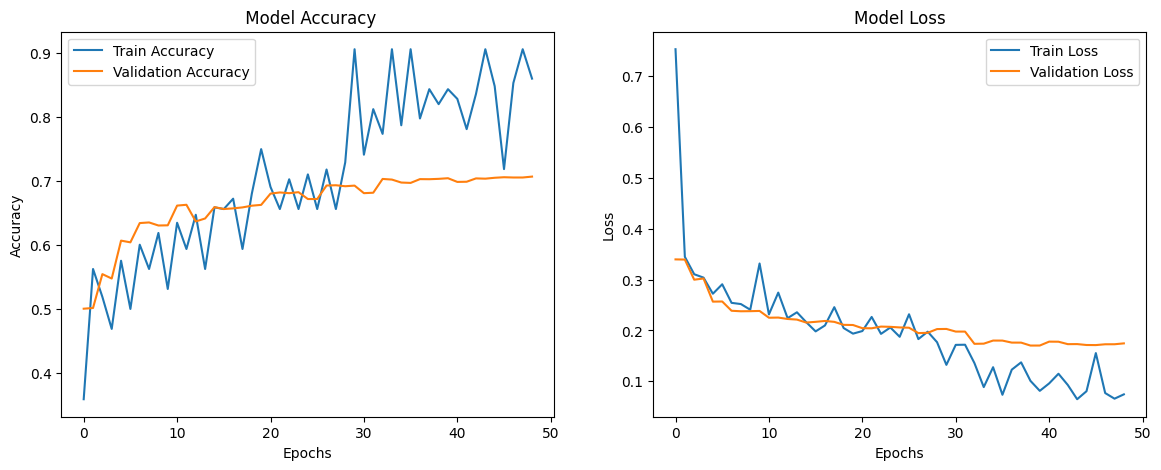

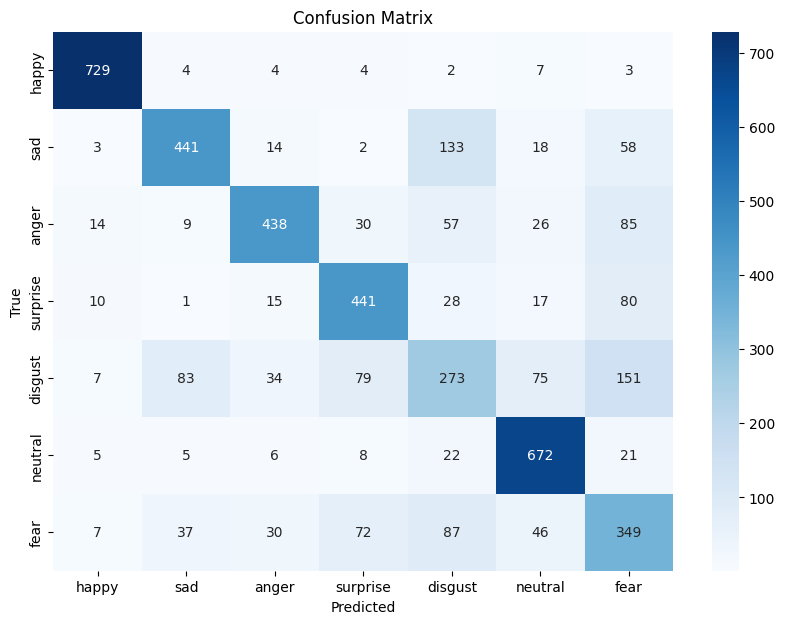

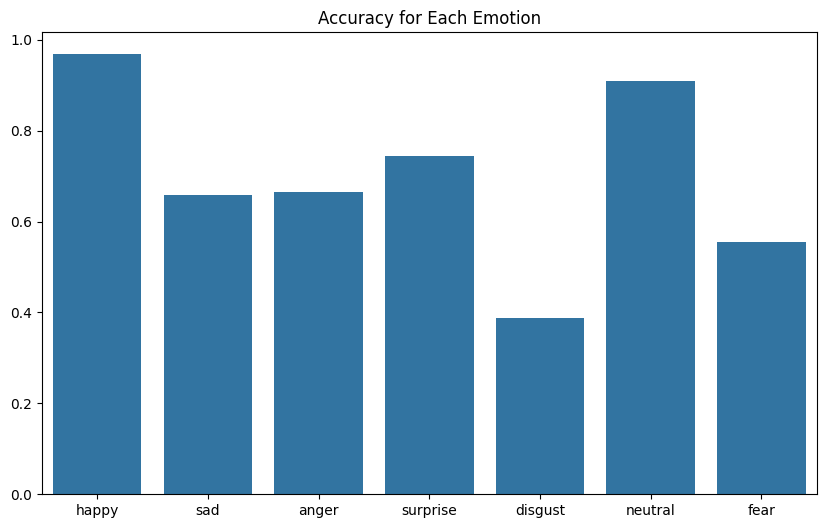

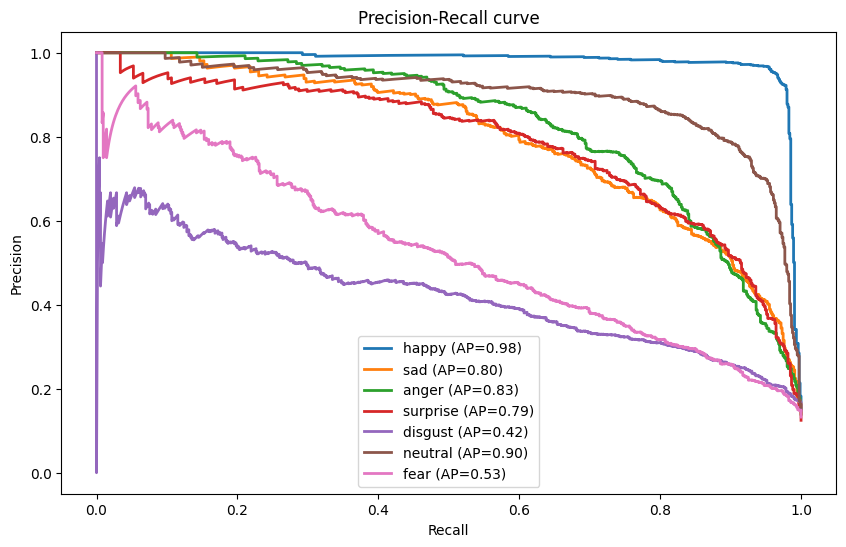

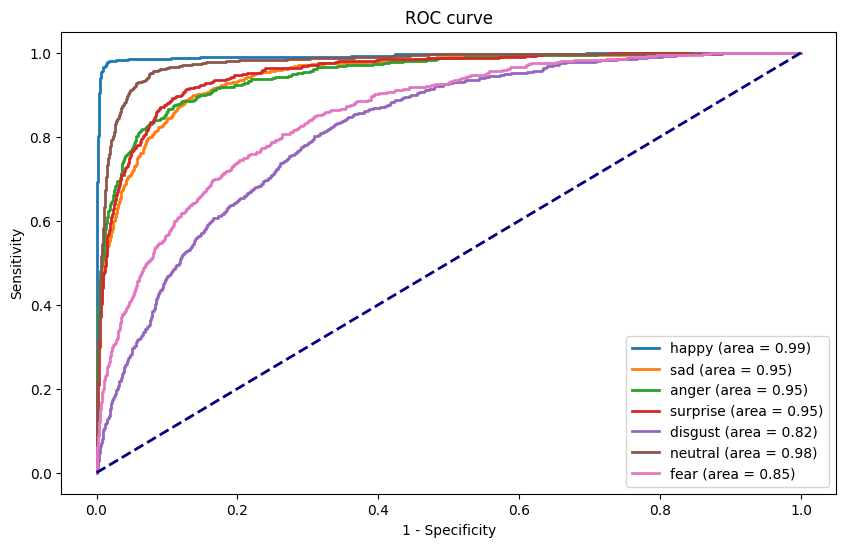

In [ ]:
#오후 3시 8분 수정코드 !! 입력 따로 받기 해놓음

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}
model_name = 'Image & ZValue'
learning_rate_combined = 5e-4
epochs = 200
factor_lr = 0.5
patience_lr = 5
patience_es = 10

# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)

    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return (image, z_product_combinations), label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"

train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)

# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

# 모델 정의
input_dim = 303  # 랜드마크 데이터의 차원
image_shape = (64, 64, 1)  # 이미지 데이터의 형태
z_comb_dim = len(list(itertools.combinations(range(8), 3)))  # z-값 조합의 차원

# 입력 레이어
model_landmark_input = Input(shape=(input_dim,))  # 랜드마크 입력
model_image_input = Input(shape=image_shape)  # 이미지 입력
model_z_input = Input(shape=(z_comb_dim,))  # z-값 조합 입력


# 이미지 서브넷
x_image = Conv2D(64, (3,3), padding='same', kernel_initializer='he_normal')(model_image_input)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

x_image = Conv2D(128, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

# 🔥 256 필터 3단계 Residual 블록 적용
for _ in range(3):
    shortcut = x_image  # 기존 연결 유지
    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)
    x_image = Activation('relu')(x_image)

    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)

    # 📌 Projection Shortcut (1x1 Conv)
    shortcut = Conv2D(256, (1,1), padding='same', kernel_initializer='he_normal')(shortcut)
    shortcut = BatchNormalization()(shortcut)

    # 🔥 Add() 연결
    x_image = Add()([x_image, shortcut])
    x_image = Activation('relu')(x_image)
    x_image = Dropout(0.3)(x_image)

x_image = MaxPooling2D((2,2))(x_image)

# 🔥 512 필터 CNN 추가
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.5)(x_image)

x_image = Flatten()(x_image)



x_z = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_z_input)
x_z = BatchNormalization()(x_z)
x_z = Activation('elu')(x_z)
x_z = Dropout(0.2)(x_z)



# 이미지 서브넷, 랜드마크 서브넷과 z_value 서브넷 합치기
combined = Concatenate()([x_image, x_z])

combined = Dense(128, kernel_regularizer=l2(0.01))(combined)
combined = BatchNormalization()(combined)
combined = Activation('elu')(combined)
combined = Dropout(0.6)(combined)
# 출력 레이어
model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(combined)

# 모델 정의
model_combined = Model(inputs=[model_image_input, model_z_input], outputs=model_output)

# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

train_samples = 71002

# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    steps_per_epoch=train_samples // batch_size,
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)


import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []
test_landmarks = []
test_z_values = []

y_test = []

for (image, z_value), label in test_dataset:
    test_images.append(image)
    y_test.extend(label.numpy())
    test_z_values.append(z_value)

y_test_pred = model_combined.predict([np.vstack(test_images), np.vstack(test_z_values)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images), np.vstack(test_z_values)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)


## Landmark + Z

Model: "functional_13"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_22            │ (None, 303)            │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_45 (Dense)          │ (None, 101)            │         30,704 │ input_layer_22[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_157   │ (None, 101)            │            404 │ dense_45[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼─

 Total params: 64,828 (253.23 KB)


 Trainable params: 63,976 (249.91 KB)


 Non-trainable params: 852 (3.33 KB)


Epoch 1/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 28s 6ms/step - accuracy: 0.3336 - loss: 1.3806 - val_accuracy: 0.3195 - val_loss: 0.3746 - learning_rate: 5.0000e-04
Epoch 2/200
   1/2218 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.4688 - loss: 0.3443

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2218/2218 ━━━━━━━━━━━━━━━━━━━━ 1s 320us/step - accuracy: 0.4688 - loss: 0.3443 - val_accuracy: 0.3284 - val_loss: 0.3701 - learning_rate: 5.0000e-04
Epoch 3/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.4518 - loss: 0.3049 - val_accuracy: 0.3265 - val_loss: 0.3239 - learning_rate: 5.0000e-04
Epoch 4/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 1s 314us/step - accuracy: 0.5625 - loss: 0.2967 - val_accuracy: 0.3230 - val_loss: 0.3252 - learning_rate: 5.0000e-04
...
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 1s 324us/step - accuracy: 0.4375 - loss: 0.2741 - val_accuracy: 0.3023 - val_loss: 0.4016 - learning_rate: 2.5000e-04
Epoch 13/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/step - accuracy: 0.4719 - loss: 0.2510 - val_accuracy: 0.4206 - val_loss: 0.2556 - learning_rate: 2.5000e-04
Epoch 14/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 1s 329us/step - accuracy: 0.4688 - loss: 0.2462 - val_accuracy: 0.4151 - val_loss: 0.2566 - learning_rate: 2.5000e-04
Epoch 15/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 13s 3ms/st

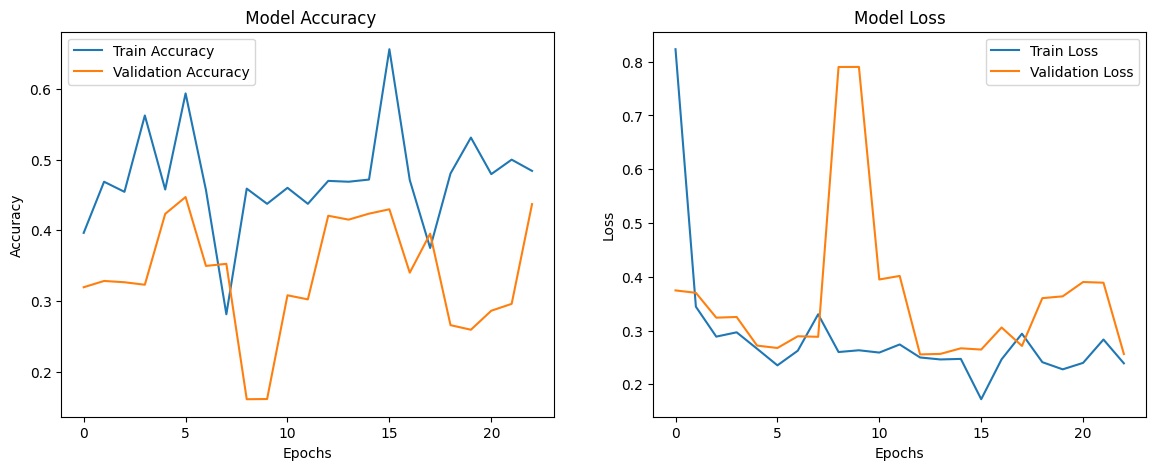

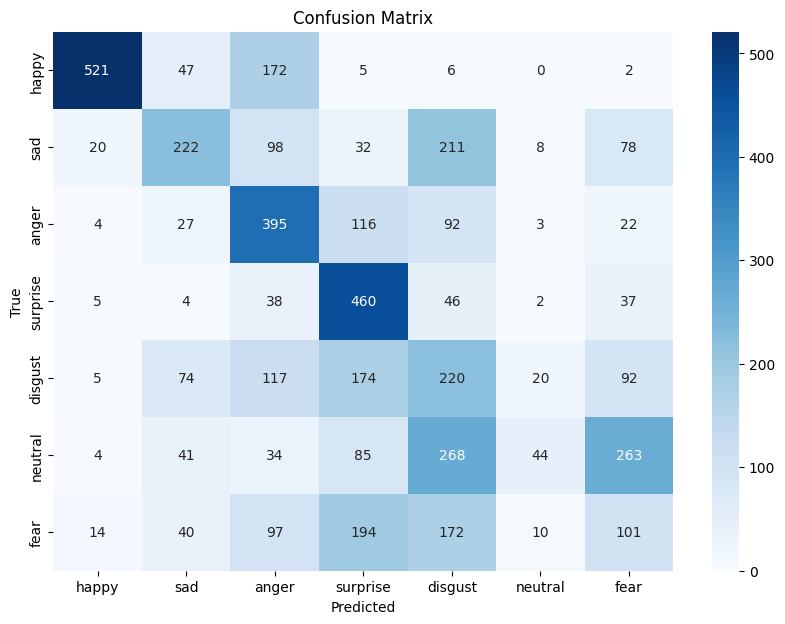

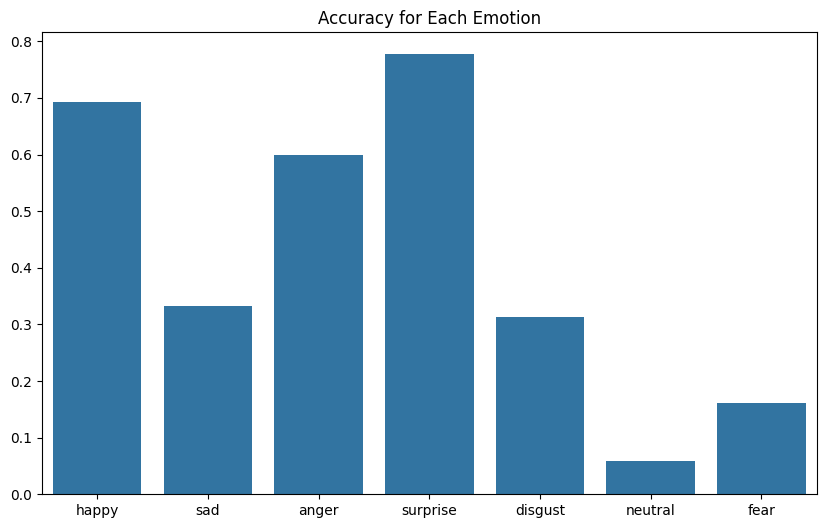

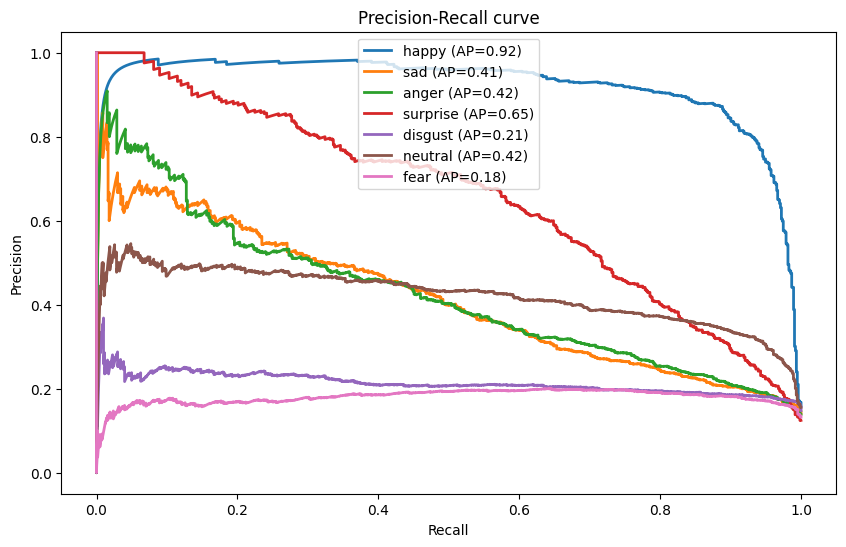

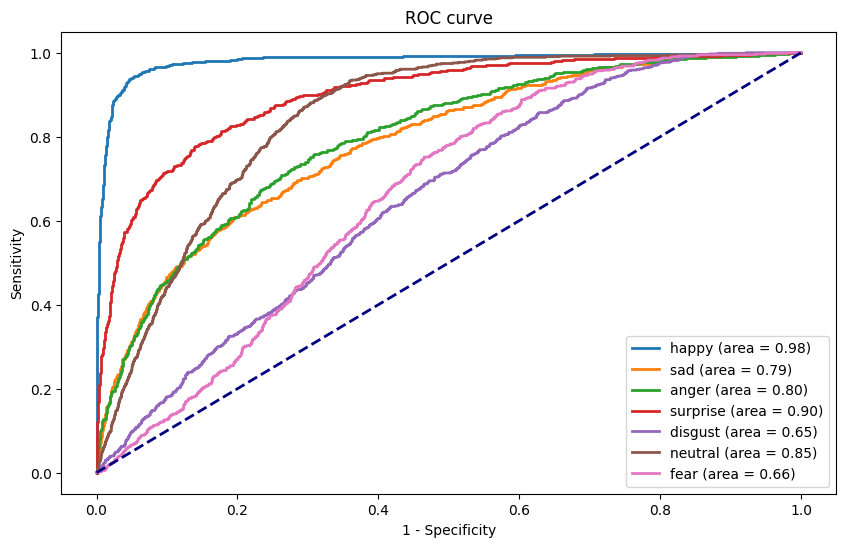

In [ ]:
#오후 3시 8분 수정코드 !! 입력 따로 받기 해놓음


# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

model_name = 'Landmark & ZValue'
learning_rate_combined = 5e-4
epochs = 200
factor_lr = 0.5
patience_lr = 5
patience_es = 10

# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)

    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return (selected_landmarks, z_product_combinations), label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)

# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

# 모델 정의
input_dim = 303  # 랜드마크 데이터의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))  # z-값 조합의 차원

# 입력 레이어
model_landmark_input = Input(shape=(input_dim,))  # 랜드마크 입력
model_z_input = Input(shape=(z_comb_dim,))  # z-값 조합 입력


# 이미지 서브넷


# 랜드마크 서브넷
x_landmark = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_landmark_input)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(64, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(32, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

# z-값 서브넷
x_z = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_z_input)
x_z = BatchNormalization()(x_z)
x_z = Activation('elu')(x_z)
x_z = Dropout(0.2)(x_z)

# 이미지 서브넷, 랜드마크 서브넷과 z_value 서브넷 합치기
combined = Concatenate()([x_landmark, x_z])

combined = Dense(128, kernel_regularizer=l2(0.01))(combined)
combined = BatchNormalization()(combined)
combined = Activation('elu')(combined)
combined = Dropout(0.6)(combined)
# 출력 레이어
model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(combined)

# 모델 정의
model_combined = Model(inputs=[model_landmark_input, model_z_input], outputs=model_output)

# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)
train_samples = 71002

# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    steps_per_epoch=train_samples // batch_size,
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)
import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []
test_landmarks = []
test_z_values = []

y_test = []

for (landmark, z_value), label in test_dataset:
    test_landmarks.append(landmark)
    y_test.extend(label.numpy())
    test_z_values.append(z_value)

y_test_pred = model_combined.predict([np.vstack(test_landmarks), np.vstack(test_z_values)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_landmarks), np.vstack(test_z_values)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)


## ⭐ Image + Landmark + Z (proposed)

Model: "functional"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 64, 64, 1)      │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 64, 64, 64)     │            640 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 64, 64, 64)     │            256 │ conv2d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation (Activation)   │ 

 Total params: 8,152,124 (31.10 MB)


 Trainable params: 8,144,232 (31.07 MB)


 Non-trainable params: 7,892 (30.83 KB)


Number of samples in the train dataset: 71002
Epoch 1/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 143s 34ms/step - accuracy: 0.3173 - loss: 1.1353 - val_accuracy: 0.2705 - val_loss: 0.4593 - learning_rate: 5.0000e-04
Epoch 2/200
   1/2218 ━━━━━━━━━━━━━━━━━━━━ 53s 24ms/step - accuracy: 0.4062 - loss: 0.3544

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2218/2218 ━━━━━━━━━━━━━━━━━━━━ 57s 26ms/step - accuracy: 0.4597 - loss: 0.3232 - val_accuracy: 0.3477 - val_loss: 0.3458 - learning_rate: 5.0000e-04
Epoch 3/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 56s 25ms/step - accuracy: 0.5117 - loss: 0.2807 - val_accuracy: 0.5797 - val_loss: 0.2527 - learning_rate: 5.0000e-04
Epoch 4/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 57s 26ms/step - accuracy: 0.5675 - loss: 0.2502 - val_accuracy: 0.6118 - val_loss: 0.2294 - learning_rate: 5.0000e-04
...
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 47s 21ms/step - accuracy: 0.8485 - loss: 0.0793 - val_accuracy: 0.7126 - val_loss: 0.1614 - learning_rate: 1.2500e-04
Epoch 33/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 47s 21ms/step - accuracy: 0.8578 - loss: 0.0730 - val_accuracy: 0.7145 - val_loss: 0.1608 - learning_rate: 1.2500e-04
Epoch 34/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 48s 21ms/step - accuracy: 0.8626 - loss: 0.0714 - val_accuracy: 0.7095 - val_loss: 0.1685 - learning_rate: 1.2500e-04
Epoch 35/200
2218/2218 ━━━━━━━━━━━━━━━━━━━━ 47s 21ms

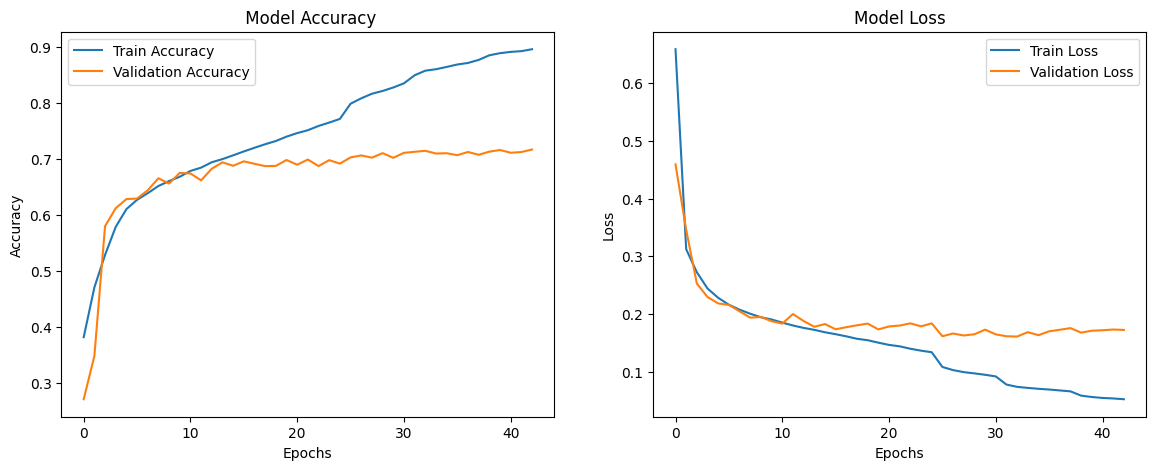

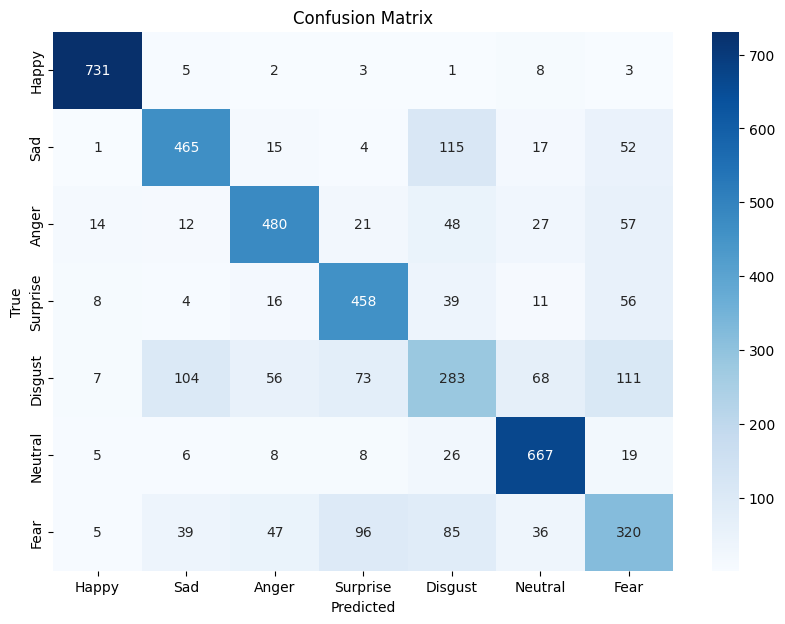

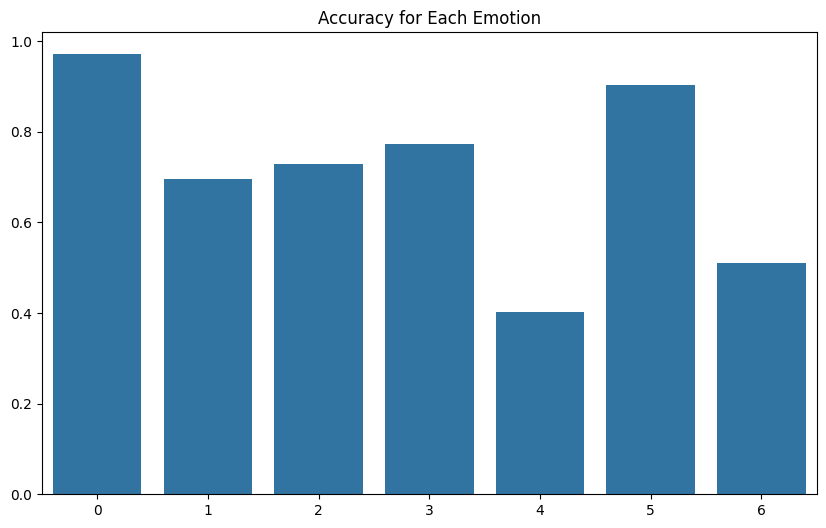

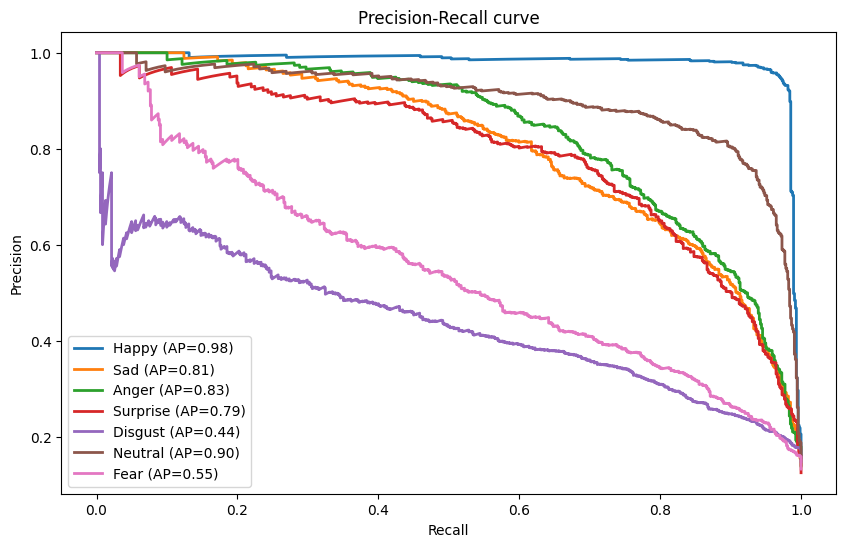

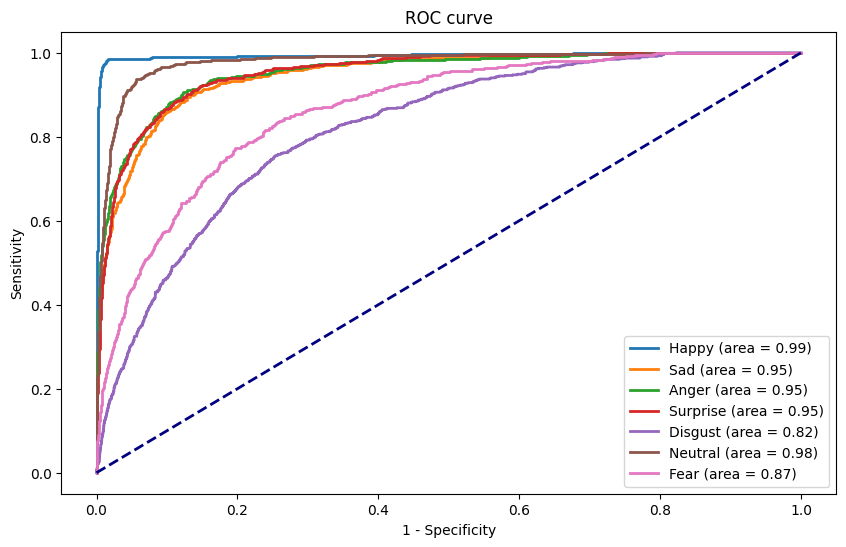

In [ ]:
#오후 3시 8분 수정코드 !! 입력 따로 받기 해놓음


# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Dense, Dropout, BatchNormalization,
                                     Conv2D, MaxPooling2D, Flatten, Activation, Concatenate)
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import itertools
from tensorflow.keras.regularizers import l2
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, TensorBoard
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score, roc_curve, auc
import pandas as pd

batch_size = 32

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

model_name = 'Image & Landmark & ZValue_64_64'

# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    # 이미지 디코딩 및 크기 조정 (64x64 유지, RGB 그대로 유지)
    image = tf.io.decode_jpeg(parsed_features["image"], channels=3)
    image = tf.image.resize(image, [64, 64])  # 🔹 64x64 크기로 변경
    image = tf.image.rgb_to_grayscale(image)  # 🔹 흑백 변환

    # 랜드마크 처리
    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    # 레이블 One-Hot 인코딩
    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    # Z-값 조합 계산
    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return (image, selected_landmarks, z_product_combinations), label

# 🟢 데이터 증강 함수 수정 (매개변수 구조 맞춤)
def augment(inputs, label):
    image, landmarks, z_values = inputs  # 튜플 언패킹
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    return (image, landmarks, z_values), label

# 🟢 데이터셋 로드 및 증강 적용
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)

    # 🔥 증강 적용 시 매개변수 개수 맞춤
    dataset = dataset.map(augment)

    if batch_size:
        dataset = dataset.batch(batch_size)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)  # 데이터 병렬 로드 최적화
    return dataset

train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"

# 🔹 수정된 데이터셋 로드 호출
train_dataset = load_and_prepare_dataset(train_tfrecord_file, batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file, batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file, batch_size)


# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

input_dim = 303  # 랜드마크 데이터의 차원
image_shape = (64, 64, 1)  # 이미지 데이터의 형태 (수정됨)
z_comb_dim = len(list(itertools.combinations(range(8), 3)))  # z-값 조합의 차원


from tensorflow.keras.layers import Input, Conv2D, Dense, BatchNormalization, Activation, Dropout, Flatten, MaxPooling2D, Add, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2

# 🟢 데이터셋 로드

# 입력 정의
model_image_input = Input(shape=(64, 64, 1))
model_landmark_input = Input(shape=(303,))
model_z_input = Input(shape=(56,))

# 🟢 이미지 서브넷 (Residual 블록 최적화)
x_image = Conv2D(64, (3,3), padding='same', kernel_initializer='he_normal')(model_image_input)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

x_image = Conv2D(128, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

# 🔥 256 필터 3단계 Residual 블록 적용
for _ in range(3):
    shortcut = x_image  # 기존 연결 유지
    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)
    x_image = Activation('relu')(x_image)

    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)

    # 📌 Projection Shortcut (1x1 Conv)
    shortcut = Conv2D(256, (1,1), padding='same', kernel_initializer='he_normal')(shortcut)
    shortcut = BatchNormalization()(shortcut)

    # 🔥 Add() 연결
    x_image = Add()([x_image, shortcut])
    x_image = Activation('relu')(x_image)
    x_image = Dropout(0.3)(x_image)

x_image = MaxPooling2D((2,2))(x_image)

# 🔥 512 필터 CNN 추가
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.5)(x_image)

x_image = Flatten()(x_image)

# 🔥 랜드마크 서브넷 최적화
x_landmark = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_landmark_input)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(64, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(32, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

# 🔥 이미지 & 랜드마크 합치기
combined_image_landmark = Concatenate()([x_image, x_landmark])

# 🔥 z-값 서브넷 최적화
x_z = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_z_input)
x_z = BatchNormalization()(x_z)
x_z = Activation('elu')(x_z)
x_z = Dropout(0.2)(x_z)

# 🔥 최종 합치기
combined = Concatenate()([combined_image_landmark, x_z])
combined = Dense(128, kernel_regularizer=l2(0.005), kernel_initializer='he_normal')(combined)
combined = BatchNormalization()(combined)
combined = Activation('elu')(combined)
combined = Dropout(0.5)(combined)

# 출력 레이어
emotion_labels = 7
model_output = Dense(emotion_labels, activation='softmax', kernel_regularizer=l2(0.005))(combined)

# 🔥 모델 정의
model_combined = Model(inputs=[model_image_input, model_landmark_input, model_z_input], outputs=model_output)


# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
learning_rate_combined = 5e-4
epochs = 200
factor_lr = 0.5
patience_lr = 5
patience_es = 10

# 모델 컴파일
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

sprint(f"Number of samples in the train dataset: {train_samples}")
train_dataset = train_dataset.repeat()  # 반복하도록 설정

# 모델 훈련
history = model_combined.fit(
    train_dataset,
    steps_per_epoch=train_samples // batch_size,
    validation_data=val_dataset,
    callbacks=[early_stopping, reduce_lr],
    epochs=epochs
)


import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/02_04_new'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []
test_landmarks = []
test_z_values = []

y_test = []

for (image, landmark, z_value), label in test_dataset:
    test_images.append(image)
    test_landmarks.append(landmark)
    y_test.extend(label.numpy())
    test_z_values.append(z_value)

y_test_pred = model_combined.predict([np.vstack(test_images), np.vstack(test_landmarks), np.vstack(test_z_values)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)


# 감정 레이블을 딕셔너리로 정의
emotion_labels = {
    0: 'Happy',
    1: 'Sad',
    2: 'Anger',
    3: 'Surprise',
    4: 'Disgust',
    5: 'Neutral',
    6: 'Fear'
}

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.values()), yticklabels=list(emotion_labels.values()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion  # 감정 인덱스를 직접 사용
    # 해당 감정에 대한 True Positive 샘플의 수를 계산
    true_positive = np.sum((y_test == emotion_index) & (y_test_pred == emotion_index))
    total = np.sum(y_test == emotion_index)  # 해당 감정의 전체 샘플 수
    # 감정별 정확도를 계산
    emotion_accuracy = true_positive / total if total > 0 else 0  # 0으로 나누는 것을 방지
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion_labels[emotion]}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)


# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
y_test_prob = model_combined.predict([np.vstack(test_images), np.vstack(test_landmarks), np.vstack(test_z_values)])

roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion_labels[emotion]} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion_labels[emotion]} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion_labels[emotion], 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion_labels[emotion],
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)

# Save PR and ROC curve data
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

# Summary output
with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion_labels[emotion]}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

# Save model
model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)

## Input-order variant: Image + Z + Landmark

Model: "functional_15"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_30            │ (None, 64, 64, 1)      │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_140 (Conv2D)       │ (None, 64, 64, 64)     │            640 │ input_layer_30[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_180   │ (None, 64, 64, 64)     │            256 │ conv2d_140[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼─

 Total params: 7,176,563 (27.38 MB)


 Trainable params: 7,152,277 (27.28 MB)


 Non-trainable params: 24,286 (94.87 KB)


Epoch 1/200
   2217/Unknown 100s 28ms/step - accuracy: 0.2664 - loss: 0.9720

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2219/2219 ━━━━━━━━━━━━━━━━━━━━ 104s 30ms/step - accuracy: 0.2665 - loss: 0.9716 - val_accuracy: 0.3236 - val_loss: 0.4607 - learning_rate: 5.0000e-04
Epoch 2/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 57s 22ms/step - accuracy: 0.3906 - loss: 0.4090 - val_accuracy: 0.4934 - val_loss: 0.3146 - learning_rate: 5.0000e-04
Epoch 3/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 57s 22ms/step - accuracy: 0.4328 - loss: 0.3608 - val_accuracy: 0.5080 - val_loss: 0.2918 - learning_rate: 5.0000e-04
...
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 56s 22ms/step - accuracy: 0.7556 - loss: 0.1202 - val_accuracy: 0.6676 - val_loss: 0.1883 - learning_rate: 5.0000e-04
Epoch 23/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 56s 22ms/step - accuracy: 0.7821 - loss: 0.1026 - val_accuracy: 0.6960 - val_loss: 0.1584 - learning_rate: 2.5000e-04
Epoch 24/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 56s 22ms/step - accuracy: 0.8067 - loss: 0.0900 - val_accuracy: 0.6850 - val_loss: 0.1785 - learning_rate: 2.5000e-04
Epoch 25/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 57s 22m

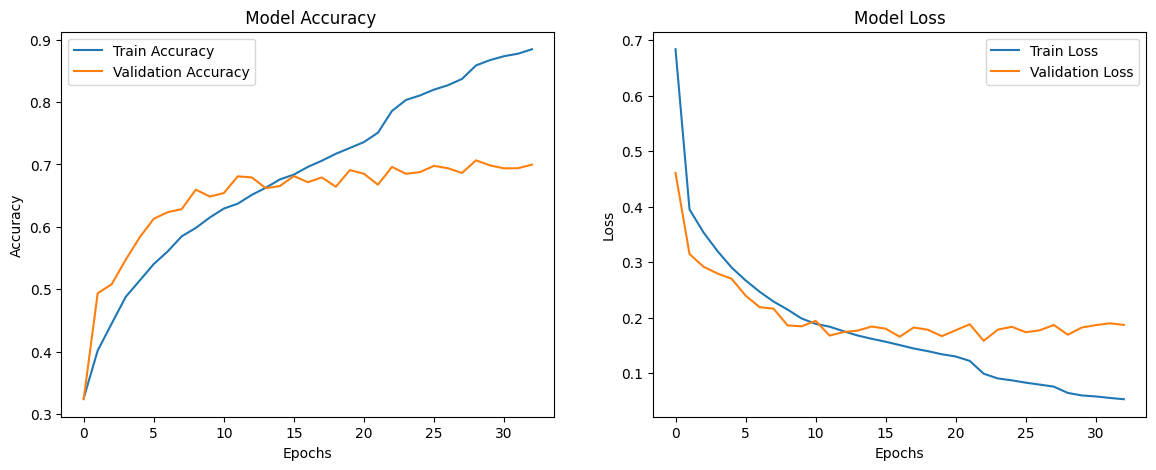

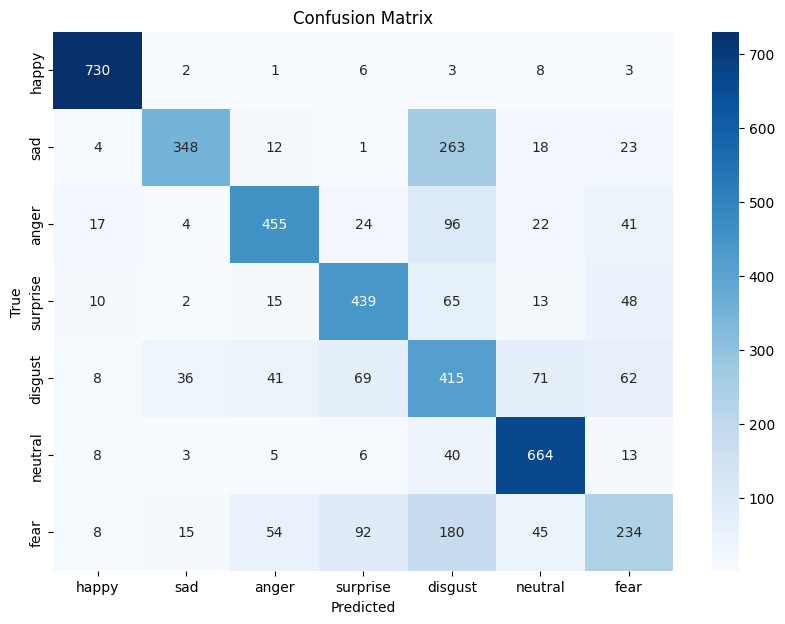

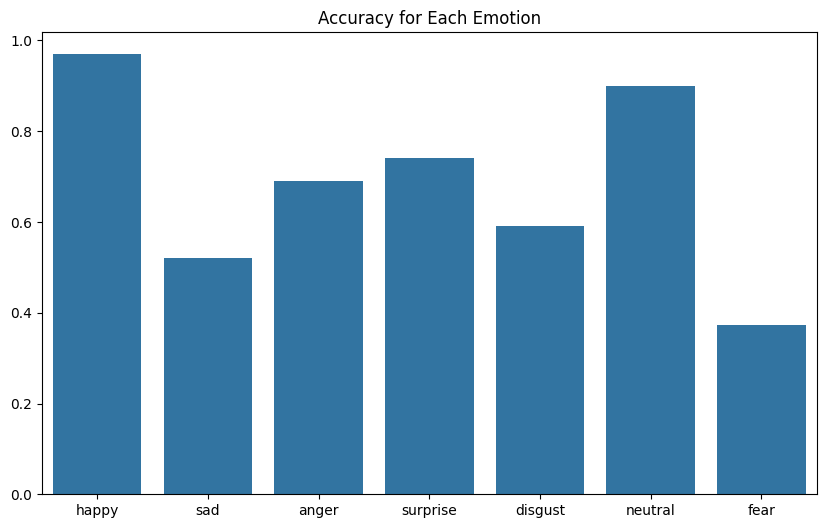

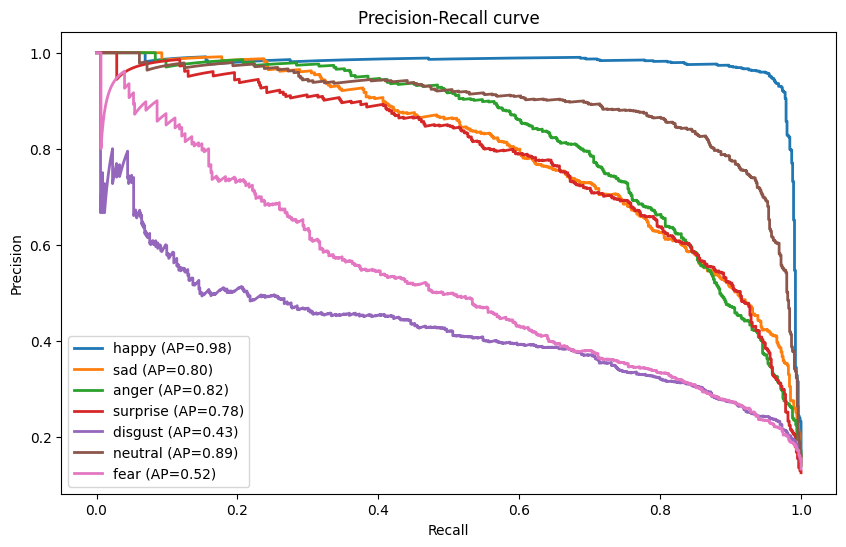

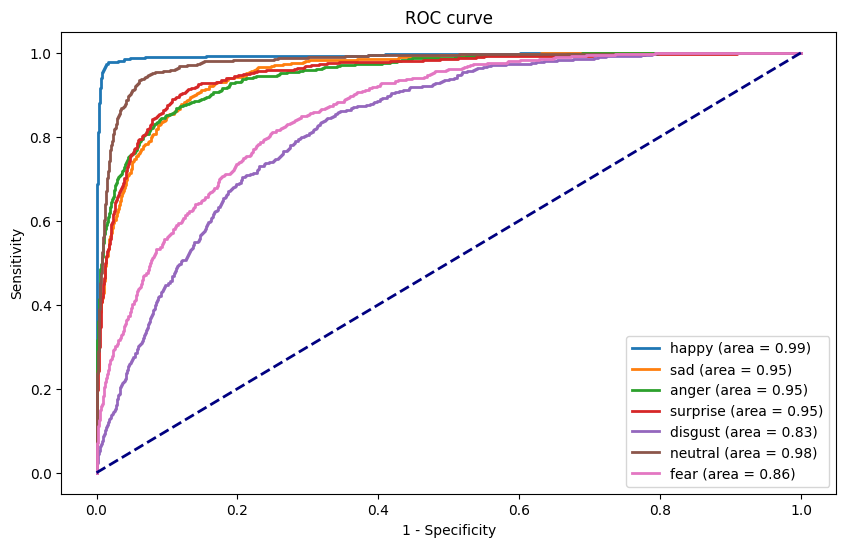

In [ ]:
#오후 3시 8분 수정코드 !! 입력 따로 받기 해놓음

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

model_name = 'Image & ZValue & Landmark'
learning_rate_combined = 5e-4
epochs = 200
factor_lr = 0.5
patience_lr = 5
patience_es = 10

# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)

    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return (image, selected_landmarks, z_product_combinations), label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)

# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

# 모델 정의
input_dim = 303  # 랜드마크 데이터의 차원
image_shape = (64, 64, 1)  # 이미지 데이터의 형태
z_comb_dim = len(list(itertools.combinations(range(8), 3)))  # z-값 조합의 차원

# 입력 레이어
model_landmark_input = Input(shape=(input_dim,))  # 랜드마크 입력
model_image_input = Input(shape=image_shape)  # 이미지 입력
model_z_input = Input(shape=(z_comb_dim,))  # z-값 조합 입력


# 이미지 서브넷
model_image_input = Input(shape=(64, 64, 1))
model_landmark_input = Input(shape=(303,))
model_z_input = Input(shape=(56,))

# 🟢 이미지 서브넷 (Residual 블록 최적화)
x_image = Conv2D(64, (3,3), padding='same', kernel_initializer='he_normal')(model_image_input)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

x_image = Conv2D(128, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

# 🔥 256 필터 3단계 Residual 블록 적용
for _ in range(3):
    shortcut = x_image  # 기존 연결 유지
    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)
    x_image = Activation('relu')(x_image)

    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)

    # 📌 Projection Shortcut (1x1 Conv)
    shortcut = Conv2D(256, (1,1), padding='same', kernel_initializer='he_normal')(shortcut)
    shortcut = BatchNormalization()(shortcut)

    # 🔥 Add() 연결
    x_image = Add()([x_image, shortcut])
    x_image = Activation('relu')(x_image)
    x_image = Dropout(0.3)(x_image)

x_image = MaxPooling2D((2,2))(x_image)

# 🔥 512 필터 CNN 추가
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.5)(x_image)

x_image = Flatten()(x_image)

# z-값 서브넷
x_z = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_z_input)
x_z = BatchNormalization()(x_z)
x_z = Activation('elu')(x_z)
x_z = Dropout(0.2)(x_z)

# 이미지 서브넷과 랜드마크 서브넷 합치기
combined_image_z_value= Concatenate()([x_image, x_z])

# 랜드마크 서브넷
x_landmark = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_landmark_input)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(64, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(32, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)


# 이미지 서브넷, 랜드마크 서브넷과 z_value 서브넷 합치기
combined = Concatenate()([combined_image_z_value, x_landmark])
combined = BatchNormalization()(combined)
combined = Activation('elu')(combined)
combined = Dropout(0.6)(combined)
# 출력 레이어
model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(combined)

# 모델 정의
model_combined = Model(inputs=[model_image_input, model_landmark_input, model_z_input], outputs=model_output)


# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)


# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)

import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')


plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []
test_landmarks = []
test_z_values = []

y_test = []

for (image, landmark, z_value), label in test_dataset:
    test_images.append(image)
    test_landmarks.append(landmark)
    y_test.extend(label.numpy())
    test_z_values.append(z_value)

y_test_pred = model_combined.predict([np.vstack(test_images), np.vstack(test_landmarks), np.vstack(test_z_values)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images), np.vstack(test_landmarks), np.vstack(test_z_values)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)

## Input-order variant: Z + Landmark + Image

Model: "functional_16"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_34            │ (None, 64, 64, 1)      │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_153 (Conv2D)       │ (None, 64, 64, 64)     │            640 │ input_layer_34[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_202   │ (None, 64, 64, 64)     │            256 │ conv2d_153[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼─

 Total params: 7,176,563 (27.38 MB)


 Trainable params: 7,152,277 (27.28 MB)


 Non-trainable params: 24,286 (94.87 KB)


Epoch 1/200
   2217/Unknown 102s 29ms/step - accuracy: 0.2685 - loss: 0.9684

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/epoch_iterator.py:151: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


2219/2219 ━━━━━━━━━━━━━━━━━━━━ 107s 31ms/step - accuracy: 0.2686 - loss: 0.9680 - val_accuracy: 0.4153 - val_loss: 0.3743 - learning_rate: 5.0000e-04
Epoch 2/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 58s 23ms/step - accuracy: 0.3903 - loss: 0.4087 - val_accuracy: 0.5170 - val_loss: 0.2870 - learning_rate: 5.0000e-04
Epoch 3/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 57s 22ms/step - accuracy: 0.4231 - loss: 0.3684 - val_accuracy: 0.5666 - val_loss: 0.2780 - learning_rate: 5.0000e-04
...
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 57s 22ms/step - accuracy: 0.7812 - loss: 0.1067 - val_accuracy: 0.6842 - val_loss: 0.1856 - learning_rate: 2.5000e-04
Epoch 24/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 57s 22ms/step - accuracy: 0.7995 - loss: 0.0946 - val_accuracy: 0.6943 - val_loss: 0.1735 - learning_rate: 2.5000e-04
Epoch 25/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 57s 22ms/step - accuracy: 0.8108 - loss: 0.0899 - val_accuracy: 0.6883 - val_loss: 0.1797 - learning_rate: 2.5000e-04
Epoch 26/200
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 57s 22m

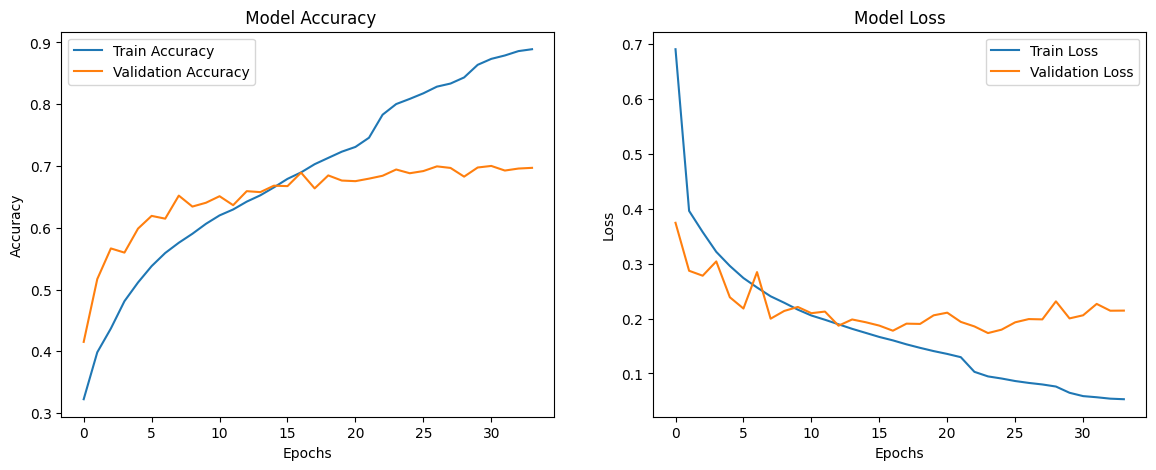

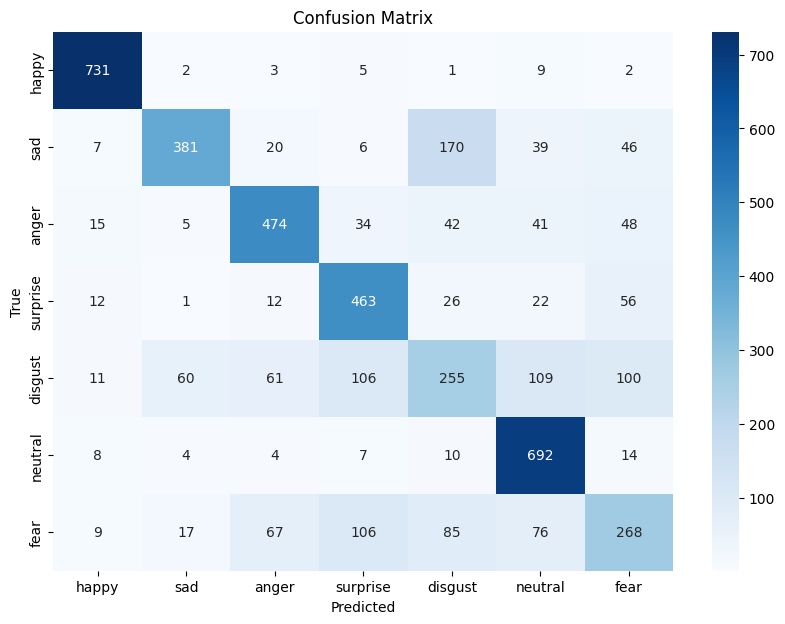

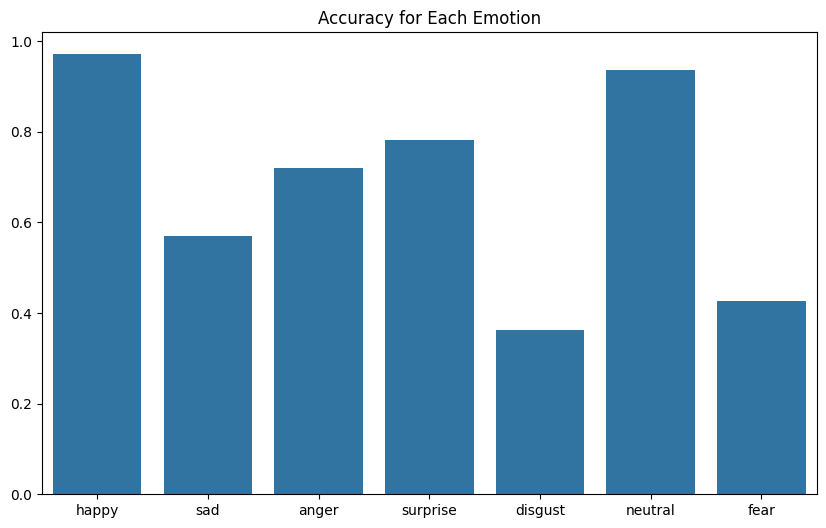

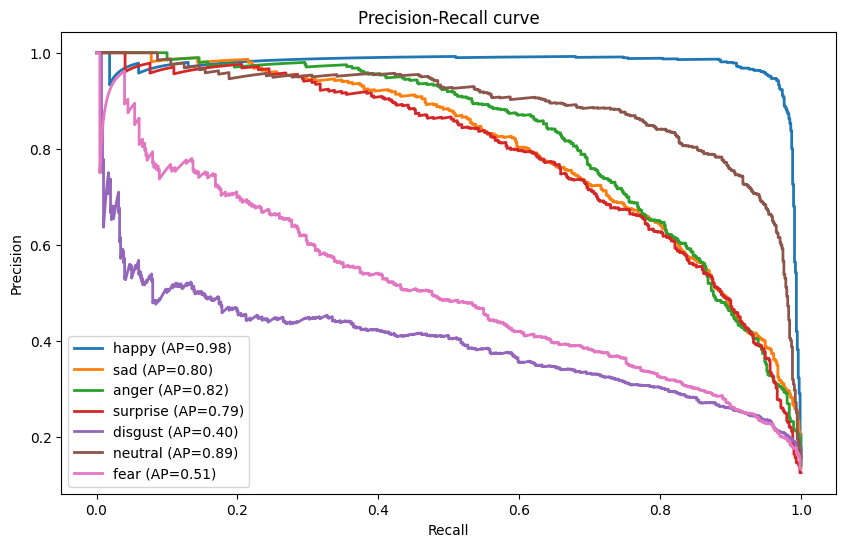

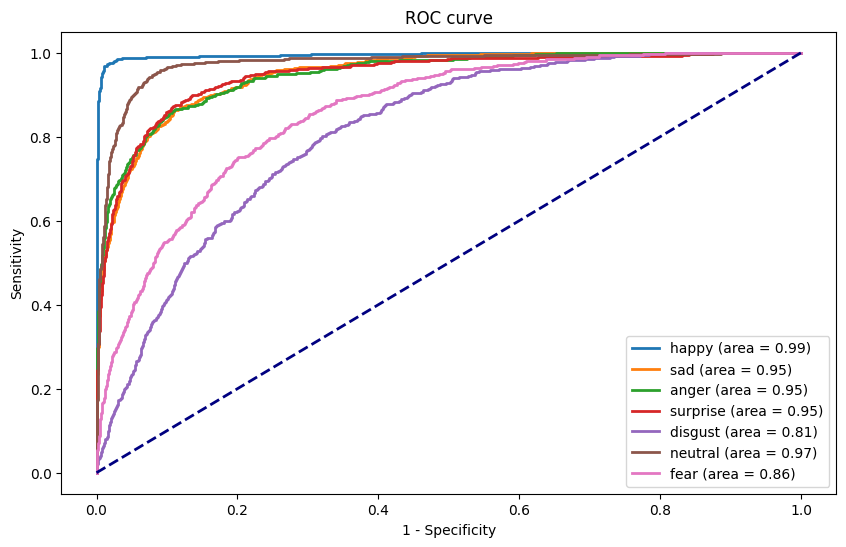

In [ ]:
#오후 3시 8분 수정코드 !! 입력 따로 받기 해놓음

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

model_name = 'ZValue & Landmark & Image'
learning_rate_combined = 5e-4
epochs = 200
factor_lr = 0.5
patience_lr = 5
patience_es = 10

# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)

    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return (image, selected_landmarks, z_product_combinations), label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)

# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

# 모델 정의
input_dim = 303  # 랜드마크 데이터의 차원
image_shape = (64, 64, 1)  # 이미지 데이터의 형태
z_comb_dim = len(list(itertools.combinations(range(8), 3)))  # z-값 조합의 차원

# 입력 레이어
model_landmark_input = Input(shape=(input_dim,))  # 랜드마크 입력
model_image_input = Input(shape=image_shape)  # 이미지 입력
model_z_input = Input(shape=(z_comb_dim,))  # z-값 조합 입력

# z-값 서브넷
x_z = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_z_input)
x_z = BatchNormalization()(x_z)
x_z = Activation('elu')(x_z)
x_z = Dropout(0.2)(x_z)

# 랜드마크 서브넷
x_landmark = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_landmark_input)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(64, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

x_landmark = Dense(32, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.3)(x_landmark)

# 이미지 서브넷과 랜드마크 서브넷 합치기
combined_landmark_z_value= Concatenate()([x_z, x_landmark])

# 이미지 서브넷
# 🟢 이미지 서브넷 (Residual 블록 최적화)
x_image = Conv2D(64, (3,3), padding='same', kernel_initializer='he_normal')(model_image_input)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

x_image = Conv2D(128, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.2)(x_image)

# 🔥 256 필터 3단계 Residual 블록 적용
for _ in range(3):
    shortcut = x_image  # 기존 연결 유지
    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)
    x_image = Activation('relu')(x_image)

    x_image = Conv2D(256, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
    x_image = BatchNormalization()(x_image)

    # 📌 Projection Shortcut (1x1 Conv)
    shortcut = Conv2D(256, (1,1), padding='same', kernel_initializer='he_normal')(shortcut)
    shortcut = BatchNormalization()(shortcut)

    # 🔥 Add() 연결
    x_image = Add()([x_image, shortcut])
    x_image = Activation('relu')(x_image)
    x_image = Dropout(0.3)(x_image)

x_image = MaxPooling2D((2,2))(x_image)

# 🔥 512 필터 CNN 추가
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = Conv2D(512, (3,3), padding='same', kernel_initializer='he_normal')(x_image)
x_image = BatchNormalization()(x_image)
x_image = Activation('relu')(x_image)
x_image = MaxPooling2D((2,2))(x_image)
x_image = Dropout(0.5)(x_image)

x_image = Flatten()(x_image)


# 이미지 서브넷, 랜드마크 서브넷과 z_value 서브넷 합치기
combined = Concatenate()([combined_landmark_z_value, x_image])
combined = BatchNormalization()(combined)
combined = Activation('elu')(combined)
combined = Dropout(0.6)(combined)
# 출력 레이어
model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(combined)

# 모델 정의
model_combined = Model(inputs=[model_image_input, model_landmark_input, model_z_input], outputs=model_output)


# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)


# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)

import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []
test_landmarks = []
test_z_values = []

y_test = []

for (image, landmark, z_value), label in test_dataset:
    test_images.append(image)
    test_landmarks.append(landmark)
    y_test.extend(label.numpy())
    test_z_values.append(z_value)

y_test_pred = model_combined.predict([np.vstack(test_images), np.vstack(test_landmarks), np.vstack(test_z_values)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images), np.vstack(test_landmarks), np.vstack(test_z_values)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)

## Variant: 1-D model

Model: "model_6"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_17 (InputLayer)       [(None, 303)]                0         []                            
...
2217/2217 [==============================] - 21s 7ms/step - loss: 0.2037 - accuracy: 0.5551 - val_loss: 0.2398 - val_accuracy: 0.4796 - lr: 5.0000e-05
Epoch 20/200
2217/2217 [==============================] - 21s 7ms/step - loss: 0.2012 - accuracy: 0.5615 - val_loss: 0.2101 - val_accuracy: 0.5416 - lr: 5.0000e-05
Epoch 21/200
2217/2217 [==============================] - 21s 7ms/step - loss: 0.2000 - accuracy: 0.5619 - val_loss: 0.2284 - val_accuracy: 0.5084 - lr: 5.0000e-05
Epoch 22/200
2217/2217 [==============================] - 21s 7ms/step - loss: 0.1987 - accuracy: 0.5640 - val_loss: 0.2114 - val_accuracy: 0.5412 - lr: 5.0000e-05
Epoch 23/200
2217/2217 [===============

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


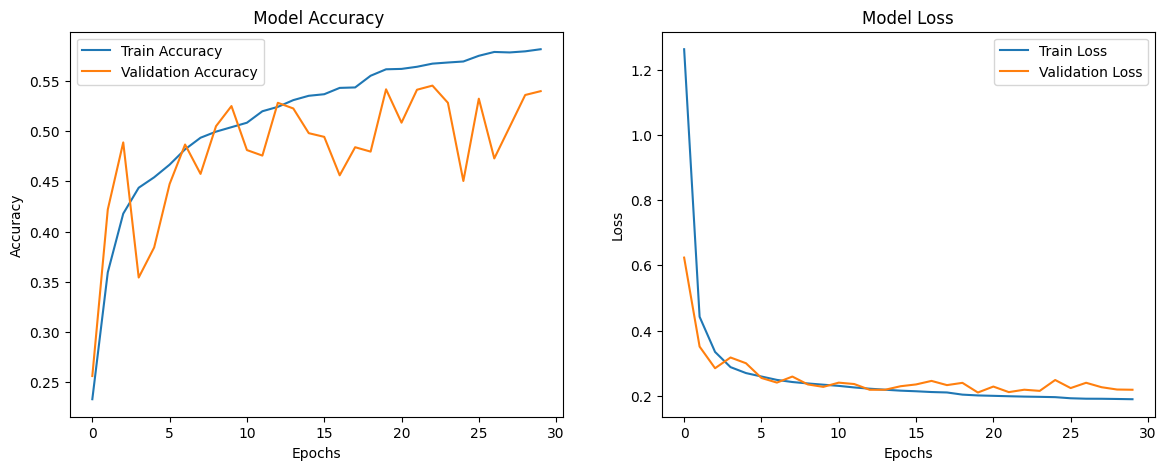

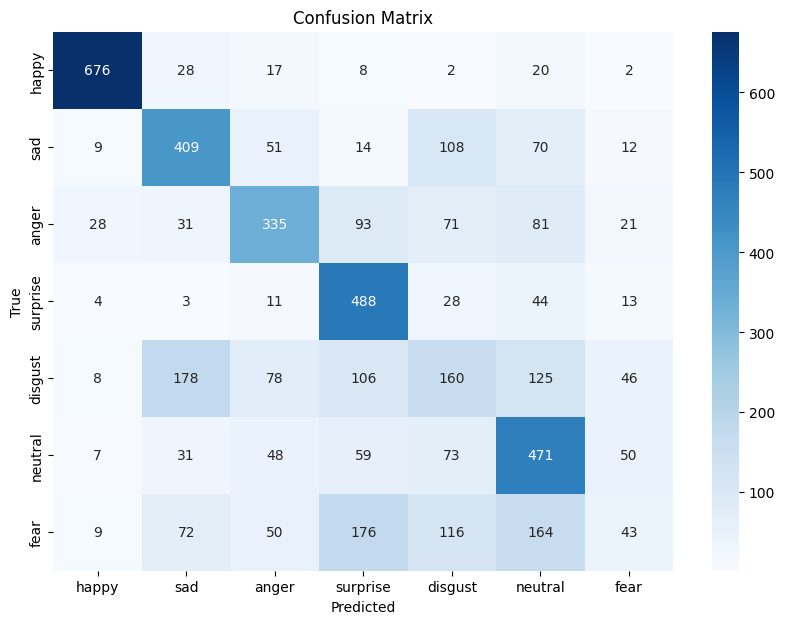

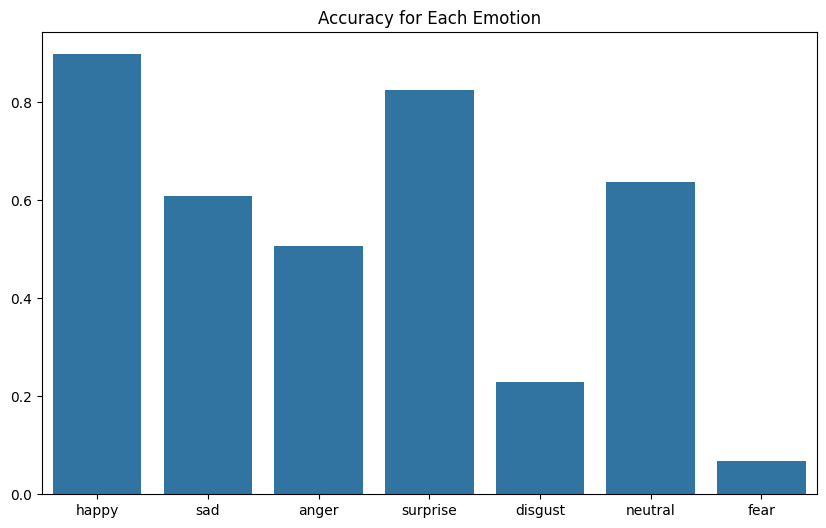

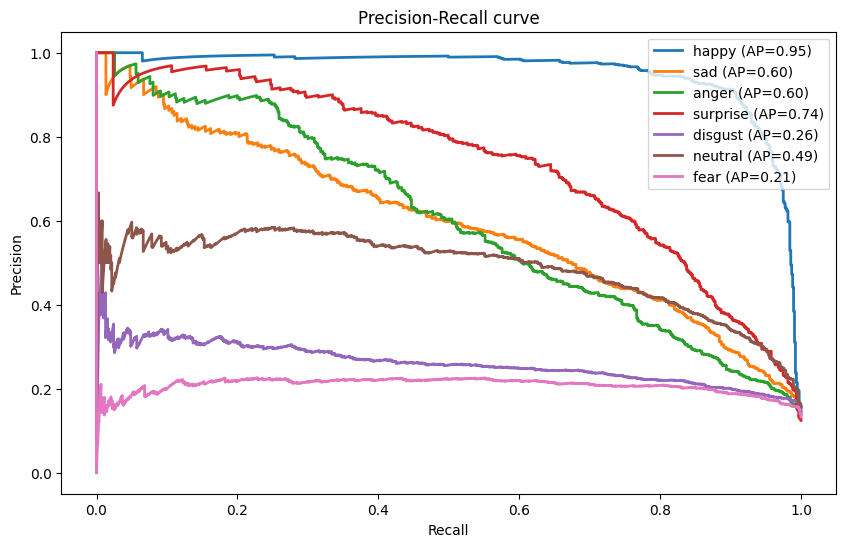

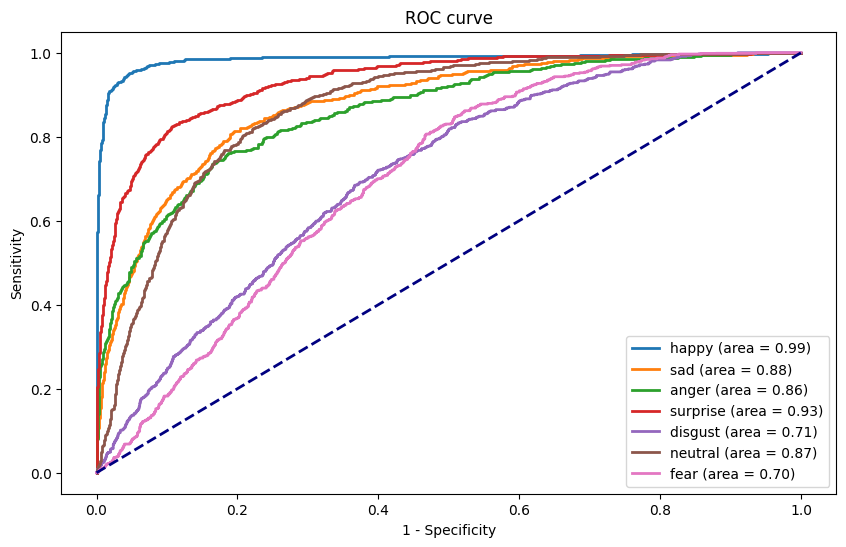

In [ ]:
'''# dropout조정하고 dense를 줄임
#과적합다시줄여야할듯

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, roc_curve, precision_recall_curve, auc

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}
model_name = '1-d'
# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [48, 48])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)

    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return (image, selected_landmarks, z_product_combinations), label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_tfrecord_file = "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_YES_Z_train.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)

# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

# 모델 정의
input_dim = 303  # 랜드마크 데이터의 차원
image_shape = (48, 48, 1)  # 이미지 데이터의 형태
z_comb_dim = len(list(itertools.combinations(range(8), 3)))  # z-값 조합의 차원

# 입력 레이어
model_landmark_input = Input(shape=(input_dim,))  # 랜드마크 입력
model_image_input = Input(shape=image_shape)  # 이미지 입력
model_z_input = Input(shape=(z_comb_dim,))  # z-값 조합 입력


# 이미지 서브넷 간소화
x_image = Conv2D(16, kernel_size=(3, 3), activation='relu', kernel_regularizer=l2(0.01))(model_image_input)  # 필터 수 감소 및 l2 정규화 계수 감소
x_image = MaxPooling2D(pool_size=(2, 2))(x_image)
x_image = Flatten()(x_image)
x_image = Dense(16, activation='relu')(x_image)  # 차원 축소를 위한 추가 레이어

# 랜드마크 서브넷 간소화
x_landmark = Dense(50, kernel_regularizer=l2(0.01))(model_landmark_input)  # 뉴런 수 감소 및 l2 정규화 계수 감소
x_landmark = BatchNormalization()(x_landmark)
x_landmark = Activation('elu')(x_landmark)
x_landmark = Dropout(0.7)(x_landmark)  # 드롭아웃 비율 조정
x_landmark = Dense(16, activation='relu')(x_landmark)  # 차원 축소를 위한 추가 레이어

# 이미지 서브넷과 랜드마크 서브넷 합치기
combined_image_landmark = Concatenate()([x_image, x_landmark])

# z-값 서브넷 간소화
x_z = Dense(50, kernel_regularizer=l2(0.01))(model_z_input)  # 뉴런 수 감소
x_z = BatchNormalization()(x_z)
x_z = Activation('elu')(x_z)
x_z = Dropout(0.7)(x_z)
x_z = Dense(16, activation='relu')(x_z)  # 차원 축소를 위한 추가 레이어

# 이미지 서브넷, 랜드마크 서브넷과 z_value 서브넷 합치기
combined = Concatenate()([combined_image_landmark, x_z])

combined = Dense(128, kernel_regularizer=l2(0.01))(combined)
combined = BatchNormalization()(combined)
combined = Activation('elu')(combined)
combined = Dropout(0.65)(combined)

# 출력 레이어
model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(combined)

# 모델 정의
model_combined = Model(inputs=[model_image_input, model_landmark_input, model_z_input], outputs=model_output)

# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)


# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)

import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []
test_landmarks = []
test_z_values = []

y_test = []

for (image, landmark, z_value), label in test_dataset:
    test_images.append(image)
    test_landmarks.append(landmark)
    y_test.extend(label.numpy())
    test_z_values.append(z_value)

y_test_pred = model_combined.predict([np.vstack(test_images), np.vstack(test_landmarks), np.vstack(test_z_values)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images), np.vstack(test_landmarks), np.vstack(test_z_values)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)'''


## Variant: weighted-average ensemble

Model: "model_8"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_17 (InputLayer)       [(None, 48, 48, 1)]          0         []                            
...
2217/2217 [==============================] - 27s 10ms/step - loss: 3.9258 - accuracy: 0.7313 - val_loss: 5.2021 - val_accuracy: 0.6454 - lr: 3.1250e-06
Epoch 69/200
2217/2217 [==============================] - 26s 10ms/step - loss: 3.9355 - accuracy: 0.7316 - val_loss: 5.1730 - val_accuracy: 0.6440 - lr: 3.1250e-06
Epoch 70/200
2217/2217 [==============================] - 27s 10ms/step - loss: 3.9109 - accuracy: 0.7331 - val_loss: 5.1921 - val_accuracy: 0.6446 - lr: 3.1250e-06
Epoch 71/200
2217/2217 [==============================] - 27s 10ms/step - loss: 3.9147 - accuracy: 0.7304 - val_loss: 5.2084 - val_accuracy: 0.6429 - lr: 3.1250e-06
Epoch 72/200
2217/2217 [===========

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


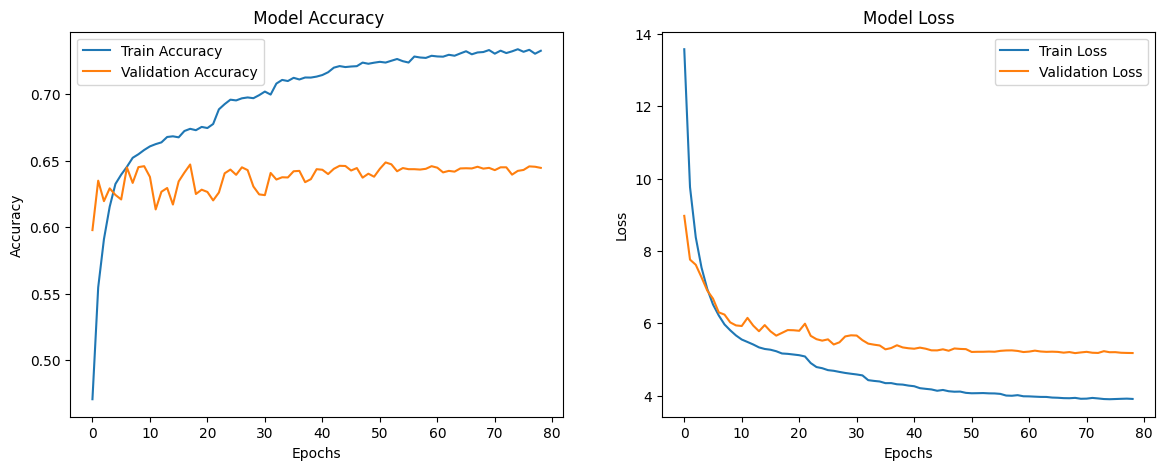

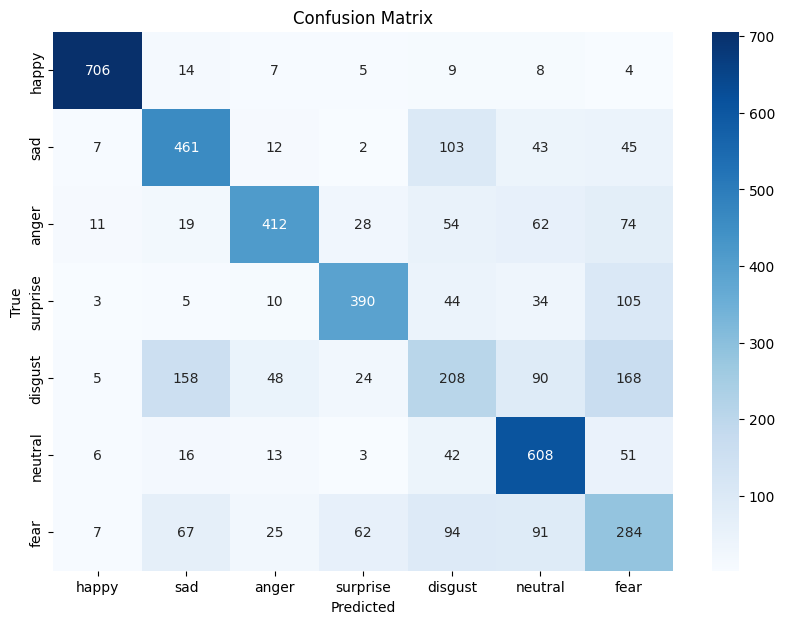

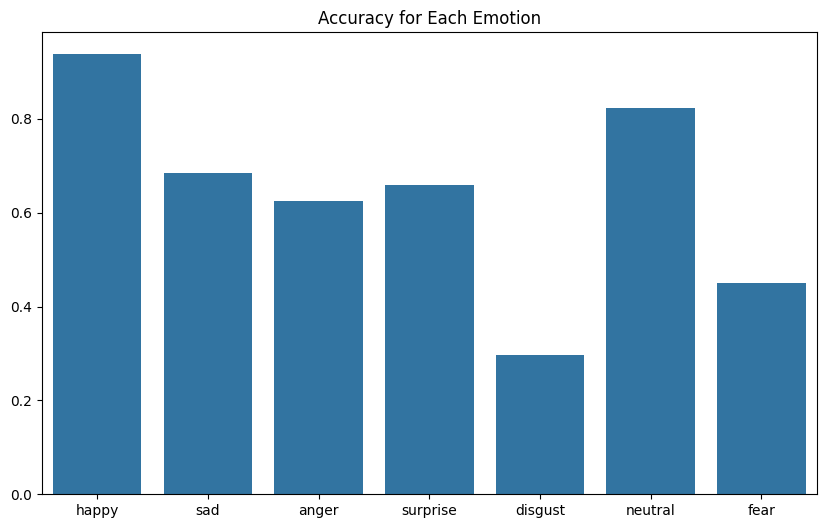

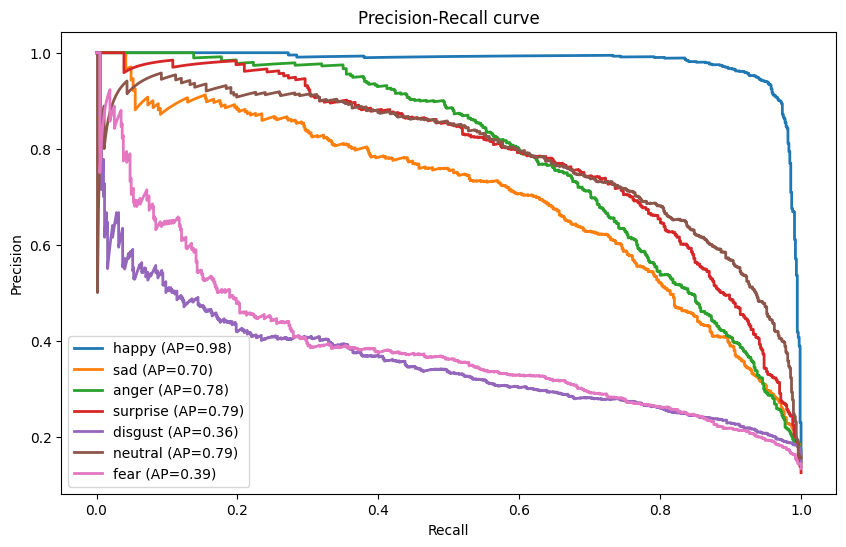

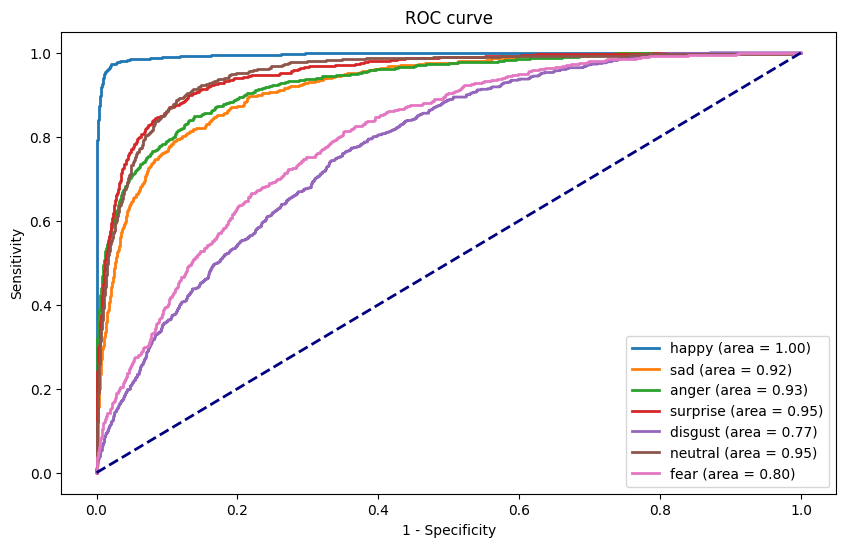

In [ ]:
'''# 평가지표는 추가했으나 다시 돌려야 함

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score, roc_curve, auc
import pandas as pd
from keras.callbacks import ReduceLROnPlateau

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}
model_name = 'weighted'
# Define landmark indices
landmark_indices = [70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 64, 4, 294, 168, 6, 197, 195, 5, 1]
# Define a function to extract selected landmarks
def extract_selected_landmarks(landmarks):
    selected_landmarks = tf.gather(landmarks, indices=landmark_indices, axis=0)
    return tf.reshape(selected_landmarks, [len(landmark_indices) * 3])

def calculate_z_value_combinations(z_values):
    z_combinations = list(itertools.combinations(range(8), 3))
    z_product_combinations = []

    for indices in z_combinations:
        selected_values = tf.gather(z_values, indices)
        product = tf.reduce_prod(selected_values)
        z_product_combinations.append(product)

    return tf.stack(z_product_combinations)

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # 기본값 수정
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [48, 48])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)

    landmarks = tf.sparse.to_dense(parsed_features["landmarks"])
    landmarks = tf.reshape(landmarks, [-1, 3])
    selected_landmarks = extract_selected_landmarks(landmarks)
    selected_landmarks.set_shape([303])

    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    z_values = parsed_features["z_values"]
    z_product_combinations = calculate_z_value_combinations(z_values)

    return (image, selected_landmarks, z_product_combinations), label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_tfrecord_file = "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_YES_Z_train.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)

def extract_image(inputs, label):
    return inputs[0], label

def extract_landmark(inputs, label):
    return inputs[1], label

def extract_z_value(inputs, label):
    return inputs[2], label

# 이미지 데이터셋
train_image_dataset = train_dataset.map(extract_image)
val_image_dataset = val_dataset.map(extract_image)
test_image_dataset = test_dataset.map(extract_image)

# 랜드마크 데이터셋
train_landmark_dataset = train_dataset.map(extract_landmark)
val_landmark_dataset = val_dataset.map(extract_landmark)
test_landmark_dataset = test_dataset.map(extract_landmark)

# z_value 데이터셋
train_z_dataset = train_dataset.map(extract_z_value)
val_z_dataset = val_dataset.map(extract_z_value)
test_z_dataset = test_dataset.map(extract_z_value)


# z-값 조합의 차원
z_comb_dim = len(list(itertools.combinations(range(8), 3)))

# 모델 정의
input_dim = 303  # 랜드마크 데이터의 차원
image_shape = (48, 48, 1)  # 이미지 데이터의 형태
z_comb_dim = len(list(itertools.combinations(range(8), 3)))  # z-값 조합의 차원

# 입력 레이어
model_landmark_input = Input(shape=(input_dim,))  # 랜드마크 입력
model_image_input = Input(shape=image_shape)  # 이미지 입력
model_z_input = Input(shape=(z_comb_dim,))  # z-값 조합 입력


def build_emotion_classifier():
    input_dim = 303  # 랜드마크 데이터의 차원
    image_shape = (48, 48, 1)  # 이미지 데이터의 형태
    z_comb_dim = len(list(itertools.combinations(range(8), 3)))

    # 입력 레이어
    model_landmark_input = Input(shape=(input_dim,))  # 랜드마크 입력
    model_image_input = Input(shape=image_shape)  # 이미지 입력
    model_z_input = Input(shape=(z_comb_dim,))  # z-값 조합 입력

    # 이미지 서브넷
    x_image = Conv2D(32, kernel_size=(3,3), strides=(1,1), padding='same', input_shape=(48,48,1))(model_image_input)
    x_image = BatchNormalization(axis=3)(x_image)
    x_image = Activation('relu')(x_image)
    x_image = Dropout(0.3)(x_image)  # new dropout layer
    x_image = MaxPooling2D((2,2))(x_image)
    x_image = Conv2D(64, kernel_size=(3,3), strides=(1,1), padding='same')(x_image)
    x_image = BatchNormalization(axis=3)(x_image)
    x_image = Activation('relu')(x_image)
    x_image = Dropout(0.3)(x_image)  # increased dropout rate
    x_image = MaxPooling2D((2,2))(x_image)
    x_image = Conv2D(128, kernel_size=(3,3), strides=(1,1), padding='same')(x_image)
    x_image = BatchNormalization(axis=3)(x_image)
    x_image = Activation('relu')(x_image)
    x_image = Dropout(0.3)(x_image)  # new dropout layer
    x_image = MaxPooling2D((2,2))(x_image)
    x_image = Flatten()(x_image)


    # 랜드마크 서브넷
    x_landmark = Dense(101, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(model_landmark_input)
    x_landmark = BatchNormalization()(x_landmark)
    x_landmark = Activation('elu')(x_landmark)
    x_landmark = Dropout(0.3)(x_landmark)  # Dropout rate 조정

    x_landmark = Dense(64, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
    x_landmark = BatchNormalization()(x_landmark)
    x_landmark = Activation('elu')(x_landmark)
    x_landmark = Dropout(0.3)(x_landmark)

    x_landmark = Dense(32, kernel_regularizer=l2(0.001), kernel_initializer='he_normal')(x_landmark)
    x_landmark = BatchNormalization()(x_landmark)
    x_landmark = Activation('elu')(x_landmark)
    x_landmark = Dropout(0.3)(x_landmark)

    # 이미지 서브넷과 랜드마크 서브넷 합치기
    combined_image_landmark = Concatenate()([x_image, x_landmark])

    # z-값 서브넷
    x_z = Dense(101, kernel_regularizer=l2(0.01))(model_z_input)
    x_z = BatchNormalization()(x_z)
    x_z = Activation('elu')(x_z)
    x_z = Dropout(0.5)(x_z)

    # 이미지 서브넷, 랜드마크 서브넷과 z_value 서브넷 합치기
    combined = Concatenate()([combined_image_landmark, x_z])

    combined = Dense(128, kernel_regularizer=l2(0.01))(combined)
    combined = BatchNormalization()(combined)
    combined = Activation('elu')(combined)
    combined = Dropout(0.6)(combined)
    # 출력 레이어
    model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(combined)

    # 모델 정의
    model_combined = Model(inputs=[model_image_input, model_landmark_input, model_z_input], outputs=model_output)

    # 모델 컴파일
    def focal_loss(gamma=2.0, alpha=0.25):
        def focal_loss_fixed(y_true, y_pred):
            # y_true: 실제 레이블, y_pred: 모델 예측
            pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
            pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
            return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

        return focal_loss_fixed

    model_combined.compile(
        optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
        loss=focal_loss(),
        metrics=['accuracy'])

    # 모델 요약
    model_combined.summary()

    # Early stopping callback


    # 이미지 서브넷 정의
    image_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(x_image)
    model_image = Model(inputs=model_image_input, outputs=image_output)

    # 랜드마크 서브넷 정의
    landmark_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(x_landmark)
    model_landmark = Model(inputs=model_landmark_input, outputs=landmark_output)

    # z-값 서브넷 정의
    z_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(x_z)
    model_z = Model(inputs=model_z_input, outputs=z_output)

    return model_combined, model_image, model_landmark, model_z

def freeze_weights(model):
    for layer in model.layers:
        layer.trainable = False

def unfreeze_weights(model):
    for layer in model.layers:
        layer.trainable = True

emotion_classifier, model_image, model_landmark, model_z = build_emotion_classifier()

# Early stopping callback


# Focal loss function
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1. - epsilon)
        pt = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        return -tf.reduce_sum(alpha * tf.pow(1. - pt, gamma) * tf.math.log(pt))
    return focal_loss_fixed

early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)


freeze_weights(model_landmark)
freeze_weights(model_z)
model_image.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),
    loss=focal_loss(),
    metrics=['accuracy'])
model_image.summary()  # Add this line to print the summary



model_image.fit(x=train_image_dataset, epochs=epochs, validation_data=val_image_dataset, callbacks=[early_stopping, reduce_lr])

# Compile and train the landmark subnetwork
unfreeze_weights(model_landmark)
freeze_weights(model_image)
freeze_weights(model_z)
model_landmark.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),
    loss=focal_loss(),
    metrics=['accuracy'])
model_landmark.summary()  # Add this line to print the summary

model_landmark.fit(x=train_landmark_dataset, epochs=epochs, validation_data=val_landmark_dataset, callbacks=[early_stopping, reduce_lr])

# Compile and train the z-value subnetwork
unfreeze_weights(model_z)
freeze_weights(model_image)
freeze_weights(model_landmark)
model_z.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),
    loss=focal_loss(),
    metrics=['accuracy'])
model_z.summary()  # Add this line to print the summary

model_z.fit(x=train_z_dataset, epochs=epochs, validation_data=val_z_dataset, callbacks=[early_stopping, reduce_lr])




# Unfreeze all weights for combined training
unfreeze_weights(model_image)
unfreeze_weights(model_landmark)
unfreeze_weights(model_z)

# Compile the combined model
emotion_classifier.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),
    loss=focal_loss(),
    metrics=['accuracy'])
emotion_classifier.summary()

# Train the combined model
history = emotion_classifier.fit(
    x=train_dataset,
    epochs=epochs,
    validation_data=val_dataset,
    callbacks=[early_stopping, reduce_lr]
)



import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')


plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = emotion_classifier.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []
test_landmarks = []
test_z_values = []

y_test = []

for (image, landmark, z_value), label in test_dataset:
    test_images.append(image)
    test_landmarks.append(landmark)
    y_test.extend(label.numpy())
    test_z_values.append(z_value)

y_test_pred = emotion_classifier.predict([np.vstack(test_images), np.vstack(test_landmarks), np.vstack(test_z_values)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = emotion_classifier.predict([np.vstack(test_images), np.vstack(test_landmarks), np.vstack(test_z_values)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

emotion_classifier.save(model_save_path_h5)
emotion_classifier.save(model_save_path_keras)'''


## Baseline: VGG16

Model: "functional_3"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)           │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lambda_3 (Lambda)                    │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 2, 2, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)    

 Total params: 14,846,279 (56.63 MB)


 Trainable params: 131,591 (514.03 KB)


 Non-trainable params: 14,714,688 (56.13 MB)


...

2219/2219 ━━━━━━━━━━━━━━━━━━━━ 26s 9ms/step - accuracy: 0.1779 - loss: 2.6210 - val_accuracy: 0.1752 - val_loss: 0.7873 - learning_rate: 1.0000e-04
Epoch 2/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.1958 - loss: 0.6990 - val_accuracy: 0.2562 - val_loss: 0.4922 - learning_rate: 1.0000e-04
Epoch 3/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.2644 - loss: 0.4546 - val_accuracy: 0.2971 - val_loss: 0.3694 - learning_rate: 1.0000e-04
...
Epoch 49/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.4260 - loss: 0.2666 - val_accuracy: 0.4015 - val_loss: 0.2784 - learning_rate: 2.5000e-05
Epoch 50/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.4234 - loss: 0.2656 - val_accuracy: 0.4041 - val_loss: 0.2789 - learning_rate: 2.5000e-05
Epoch 51/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.4263 - loss: 0.2648 - val_accuracy: 0.4102 - val_loss: 0.2792 - learning_rate: 1.2500e-05
Epoch 52/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 2

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_81
Received: inputs=('Tensor(shape=(32, 64, 64, 1))',)
  warnings.warn(msg)


145/149 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_81
Received: inputs=('Tensor(shape=(None, 64, 64, 1))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step
Accuracy for happy: 0.75
Accuracy for sad: 0.40
Accuracy for anger: 0.40
Accuracy for surprise: 0.58
Accuracy for disgust: 0.18
Accuracy for neutral: 0.54
Accuracy for fear: 0.08
Precision: 0.40
Recall: 0.42
F1 Score: 0.40
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
vggnet16 ROC AUC Score: 0.76


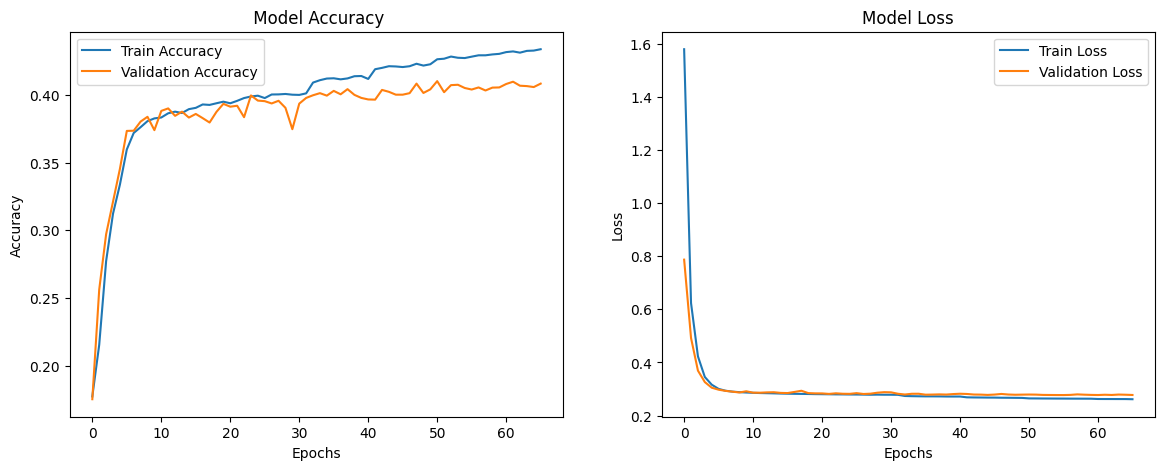

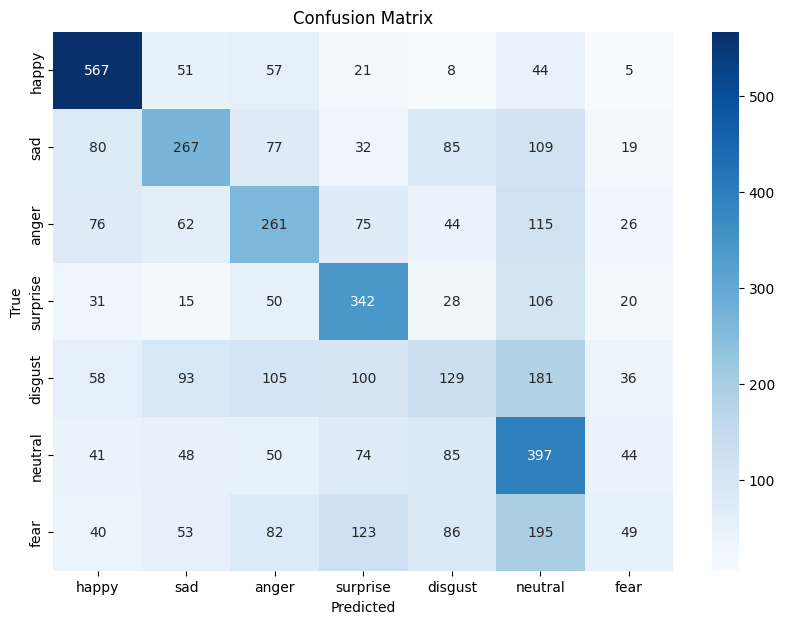

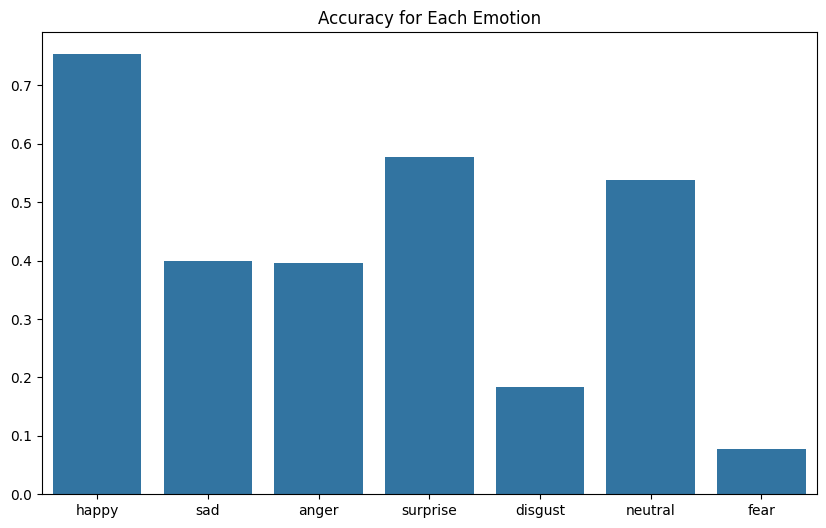

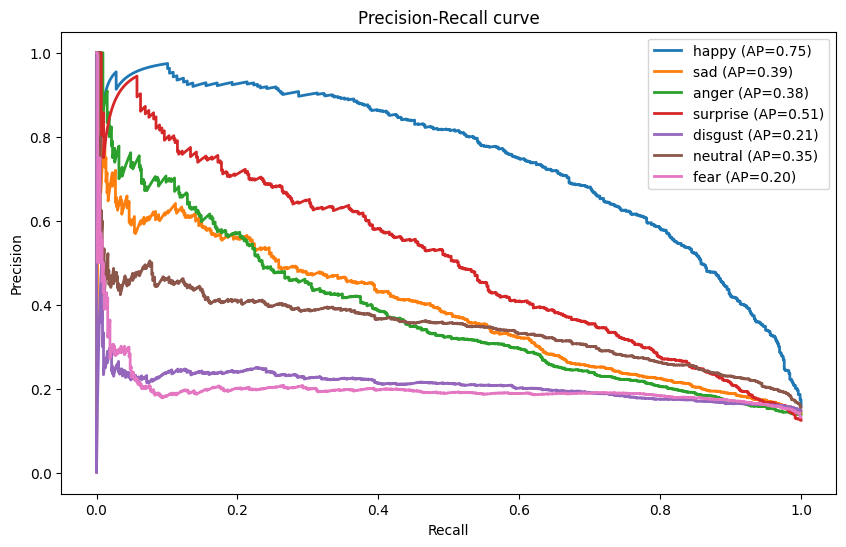

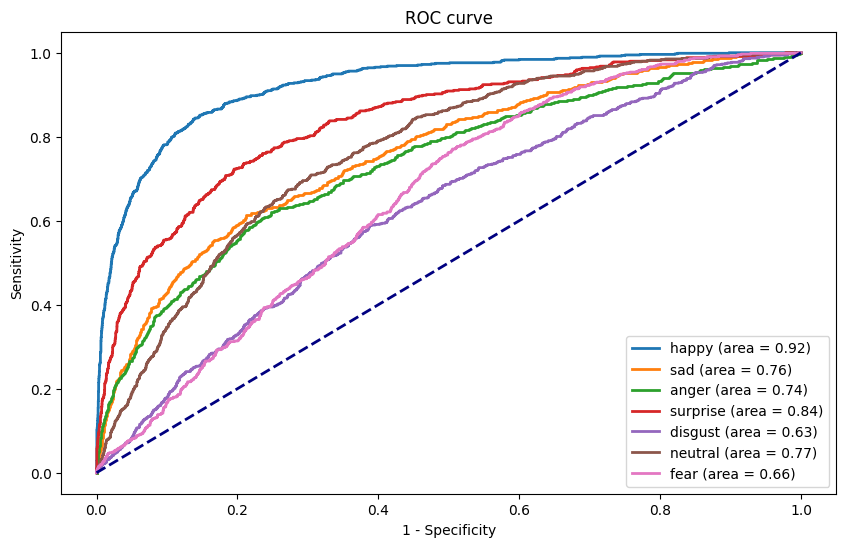

In [ ]:
# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Flatten, Conv2D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.layers import Lambda
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
#오후 3시 8분 수정코드 !! 입력 따로 받기 해놓음


# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Dense, Dropout, BatchNormalization,
                                     Conv2D, MaxPooling2D, Flatten, Activation, Concatenate)
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import itertools
from tensorflow.keras.regularizers import l2
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, TensorBoard
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score, roc_curve, auc
import pandas as pd
# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}
model_name = 'vggnet16'


# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)


    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    return image, label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"



train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)


# 모델 정의
image_shape = (64, 64, 1)  # 이미지 데이터의 형태

model_image_input = Input(shape=image_shape)  # 이미지 입력


# 입력 레이어
# 랜드마크와 유클리드 거리 서브넷

# 이미지 서브넷
import tensorflow as tf
from tensorflow.keras.layers import Input, Lambda, Flatten, Dense
from tensorflow.keras.regularizers import l2
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model

# Assuming emotion_labels is defined somewhere


# Concatenate grayscale image to RGB
x_image = Lambda(lambda x: tf.concat([x, x, x], axis=-1))(model_image_input)

# Load VGG16 model pre-trained on ImageNet, excluding top layers
vggnet_model = VGG16(weights='imagenet', include_top=False, input_shape=(64, 64, 3))

# Freeze VGG16 layers
for layer in vggnet_model.layers:
    layer.trainable = False

# Pass concatenated RGB image through VGG16
x_image = vggnet_model(x_image)

# Flatten output and add dense layers
x_image = Flatten()(x_image)
x_image = Dense(64, activation='relu', kernel_regularizer=l2(0.01))(x_image)

# Output layer for classification
model_output = Dense(len(emotion_labels), activation='softmax')(x_image)

# Combine inputs and outputs into a model
model_combined = Model(inputs=model_image_input, outputs=model_output)



# 모델 컴파일
# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)


import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')


plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []


y_test = []

for image, label in test_dataset:
    test_images.append(image)
    y_test.extend(label.numpy())

y_test_pred = model_combined.predict([np.vstack(test_images)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)

## Baseline: VGG19

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_4"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)           │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lambda_4 (Lambda)                    │ (None, 64, 64, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg19 (Functional)                   │ (None, 2, 2, 512)           │      20,024,384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)    

 Total params: 20,155,975 (76.89 MB)


 Trainable params: 131,591 (514.03 KB)


...

2219/2219 ━━━━━━━━━━━━━━━━━━━━ 30s 11ms/step - accuracy: 0.1611 - loss: 2.3959 - val_accuracy: 0.1599 - val_loss: 0.7802 - learning_rate: 1.0000e-04
Epoch 2/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.1687 - loss: 0.6953 - val_accuracy: 0.2040 - val_loss: 0.5017 - learning_rate: 1.0000e-04
Epoch 3/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 24s 9ms/step - accuracy: 0.2197 - loss: 0.4657 - val_accuracy: 0.2652 - val_loss: 0.3818 - learning_rate: 1.0000e-04
...
Epoch 24/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 24s 9ms/step - accuracy: 0.3985 - loss: 0.2796 - val_accuracy: 0.3977 - val_loss: 0.2863 - learning_rate: 5.0000e-05
Epoch 25/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 24s 9ms/step - accuracy: 0.4017 - loss: 0.2791 - val_accuracy: 0.3901 - val_loss: 0.2837 - learning_rate: 5.0000e-05
Epoch 26/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.3977 - loss: 0.2790 - val_accuracy: 0.4025 - val_loss: 0.2817 - learning_rate: 5.0000e-05
Epoch 27/100
2219/2219 ━━━━━━━━━━━━━━━━━━━

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_108
Received: inputs=('Tensor(shape=(32, 64, 64, 1))',)
  warnings.warn(msg)


148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_108
Received: inputs=('Tensor(shape=(None, 64, 64, 1))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step
Accuracy for happy: 0.74
Accuracy for sad: 0.37
Accuracy for anger: 0.39
Accuracy for surprise: 0.53
Accuracy for disgust: 0.19
Accuracy for neutral: 0.50
Accuracy for fear: 0.08
Precision: 0.38
Recall: 0.40
F1 Score: 0.38
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
vggnet19 ROC AUC Score: 0.76


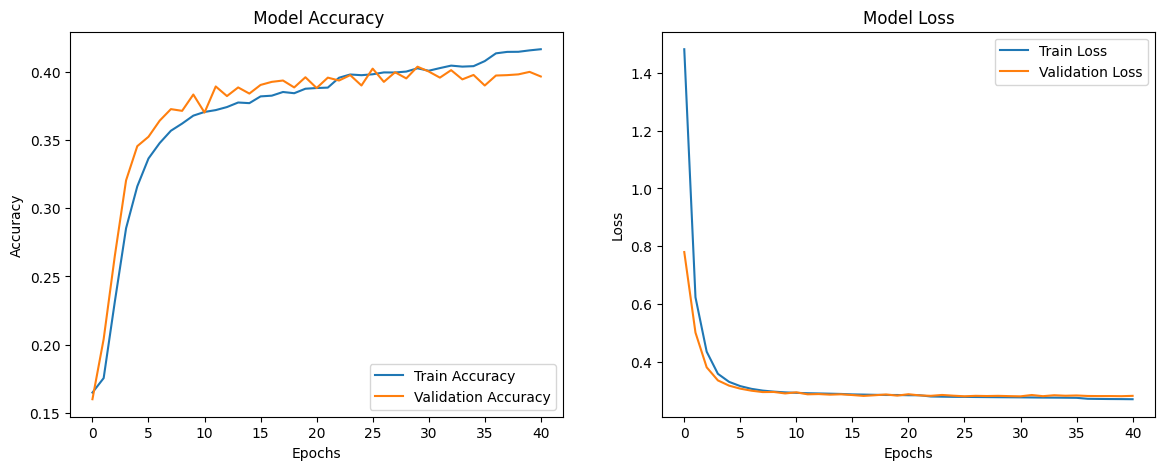

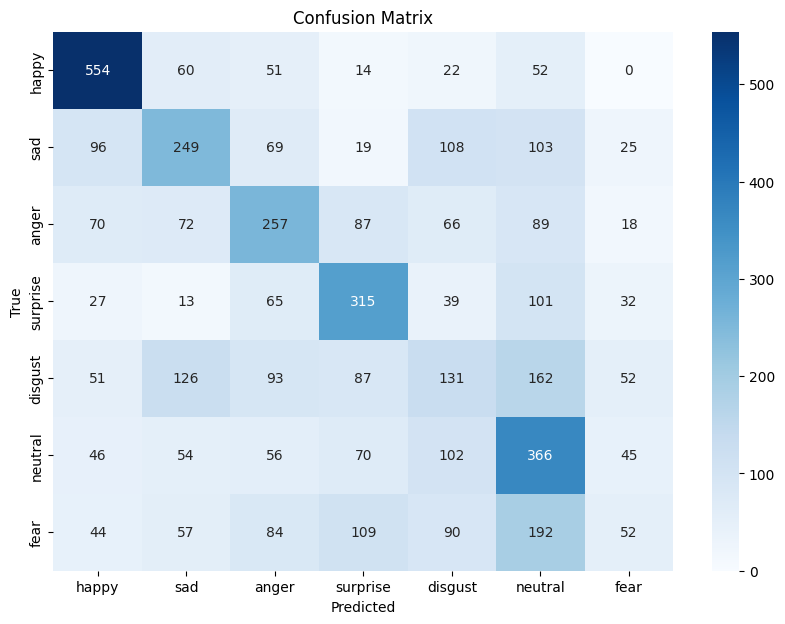

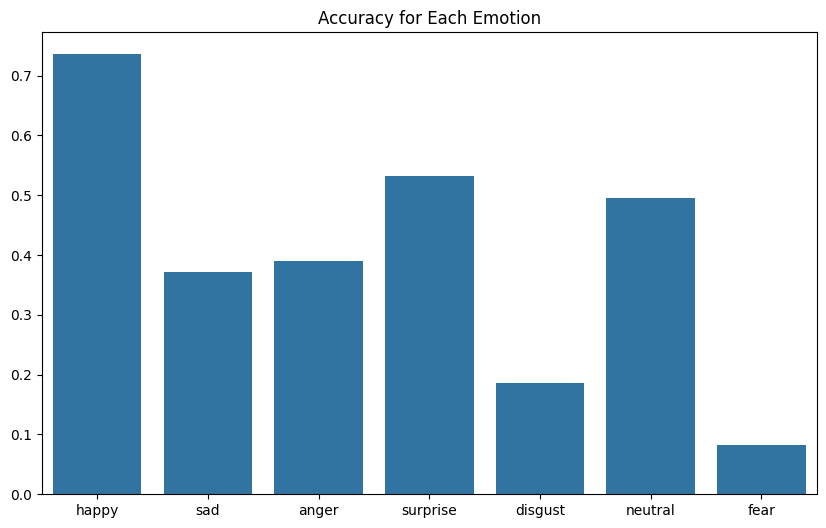

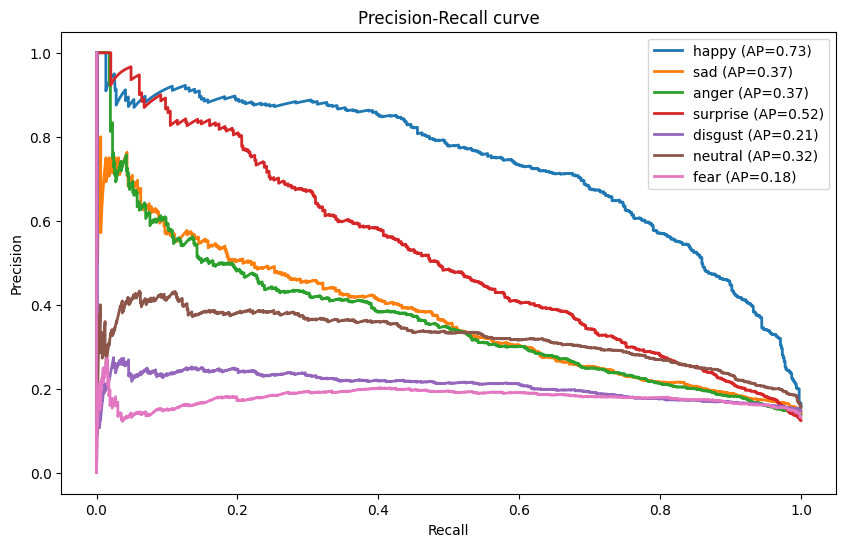

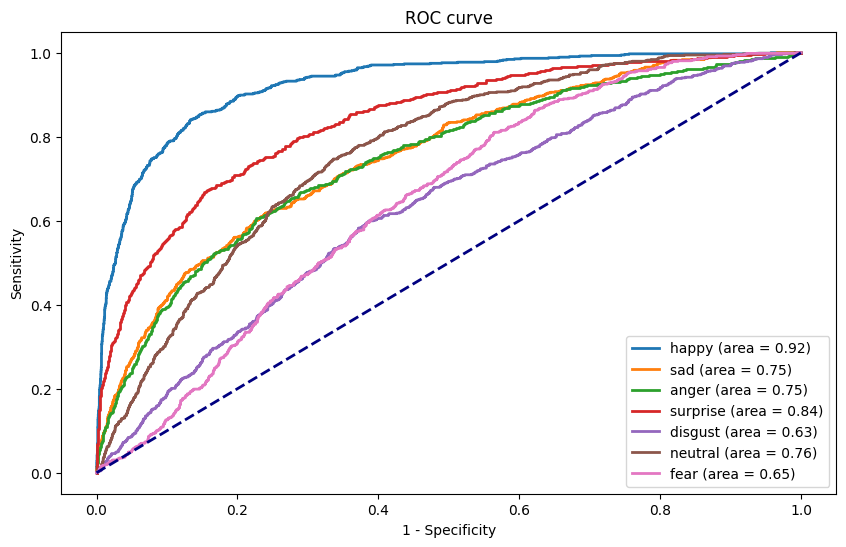

In [ ]:

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Flatten, Conv2D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.layers import Lambda

# Model name
model_name = 'vggnet19'

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}



# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)


    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    return image, label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"



train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)


# 모델 정의
image_shape = (64, 64, 1)  # 이미지 데이터의 형태

model_image_input = Input(shape=image_shape)  # 이미지 입력


# 입력 레이어
# 랜드마크와 유클리드 거리 서브넷

# 이미지 서브넷
x_image = Lambda(lambda x: tf.concat([x, x, x], axis=-1))(model_image_input)

# Load VGG16 model pre-trained on ImageNet, excluding top layers
vggnet_model = VGG19(weights='imagenet', include_top=False, input_shape=(64, 64, 3))

# Freeze VGG16 layers
for layer in vggnet_model.layers:
    layer.trainable = False

# Pass concatenated RGB image through VGG16
x_image = vggnet_model(x_image)

# Flatten output and add dense layers
x_image = Flatten()(x_image)
x_image = Dense(64, activation='relu', kernel_regularizer=l2(0.01))(x_image)

# Output layer for classification
model_output = Dense(len(emotion_labels), activation='softmax')(x_image)

# Combine inputs and outputs into a model
model_combined = Model(inputs=model_image_input, outputs=model_output)


# 모델 컴파일
# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)


import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')


plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []


y_test = []

for image, label in test_dataset:
    test_images.append(image)
    y_test.extend(label.numpy())

y_test_pred = model_combined.predict([np.vstack(test_images)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)


## Baseline: EfficientNetB7

258076736/258076736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_5"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)          │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 64, 64, 3)           │               6 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb7 (Functional)          │ (None, 2, 2, 2560)          │      64,097,687 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 10240)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)  

 Total params: 64,753,572 (247.02 MB)


 Trainable params: 64,442,845 (245.83 MB)


...

2219/2219 ━━━━━━━━━━━━━━━━━━━━ 581s 151ms/step - accuracy: 0.3102 - loss: 1.0440 - val_accuracy: 0.5801 - val_loss: 0.2558 - learning_rate: 1.0000e-04
Epoch 2/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 204s 91ms/step - accuracy: 0.6150 - loss: 0.2222 - val_accuracy: 0.6333 - val_loss: 0.1925 - learning_rate: 1.0000e-04
Epoch 3/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 204s 90ms/step - accuracy: 0.7006 - loss: 0.1556 - val_accuracy: 0.6445 - val_loss: 0.1812 - learning_rate: 1.0000e-04
Epoch 4/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 204s 91ms/step - accuracy: 0.7879 - loss: 0.1089 - val_accuracy: 0.6440 - val_loss: 0.1950 - learning_rate: 1.0000e-04
Epoch 5/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 203s 90ms/step - accuracy: 0.8610 - loss: 0.0737 - val_accuracy: 0.6333 - val_loss: 0.2190 - learning_rate: 1.0000e-04
Epoch 6/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 200s 89ms/step - accuracy: 0.9063 - loss: 0.0540 - val_accuracy: 0.6319 - val_loss: 0.2265 - learning_rate: 1.0000e-04
Epoch 7/100
2219/2219 ━━━━━━━━━━━━━━━━━

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_953
Received: inputs=('Tensor(shape=(32, 64, 64, 1))',)
  warnings.warn(msg)


148/149 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_953
Received: inputs=('Tensor(shape=(None, 64, 64, 1))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 33s 124ms/step
Accuracy for happy: 0.95
Accuracy for sad: 0.60
Accuracy for anger: 0.66
Accuracy for surprise: 0.65
Accuracy for disgust: 0.31
Accuracy for neutral: 0.85
Accuracy for fear: 0.47
Precision: 0.64
Recall: 0.64
F1 Score: 0.64
149/149 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step
effnetB7 ROC AUC Score: 0.90


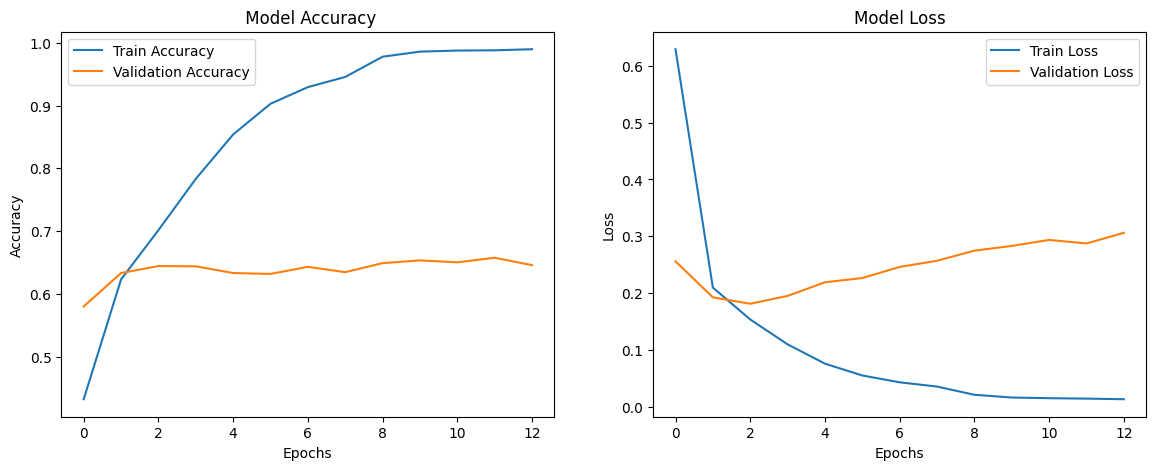

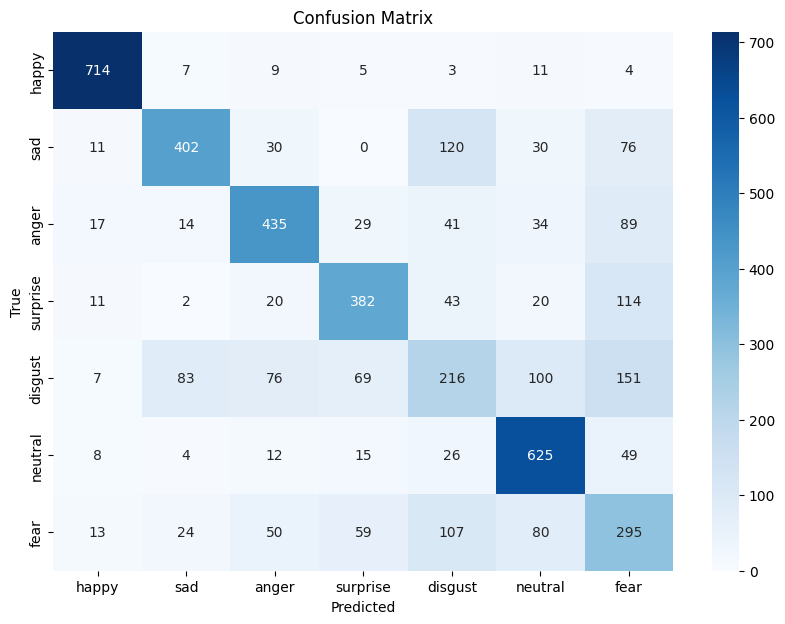

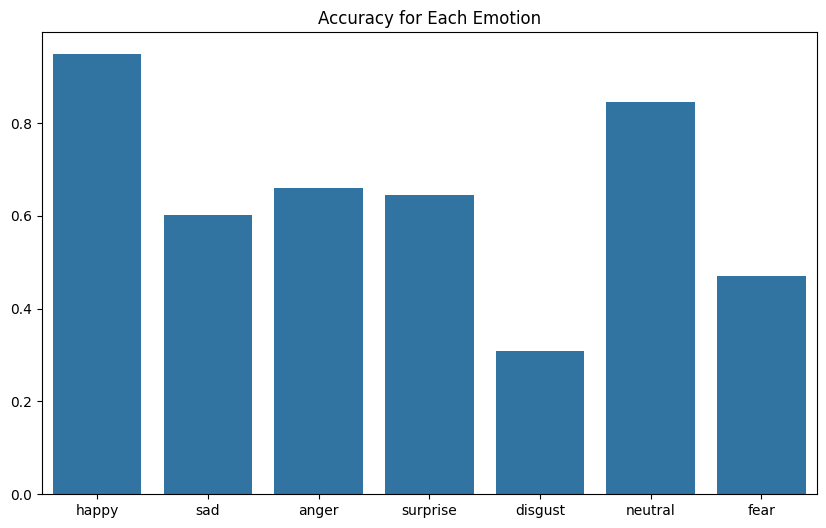

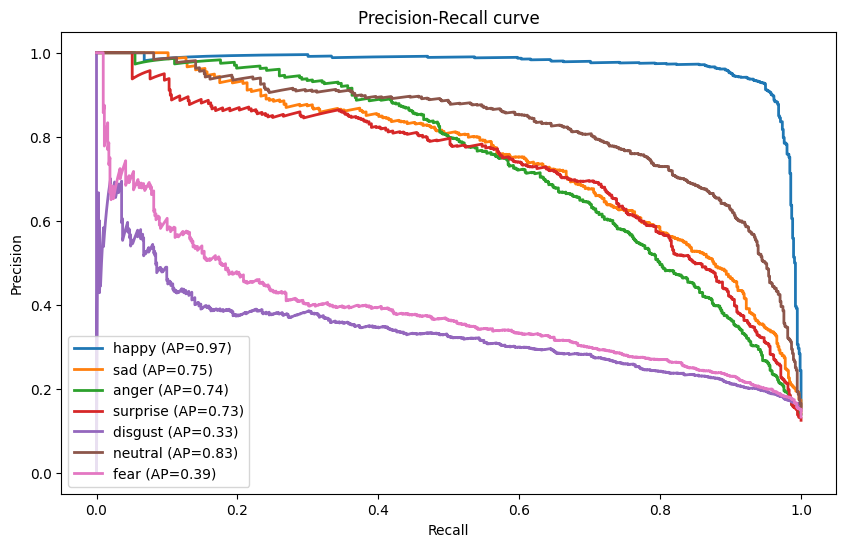

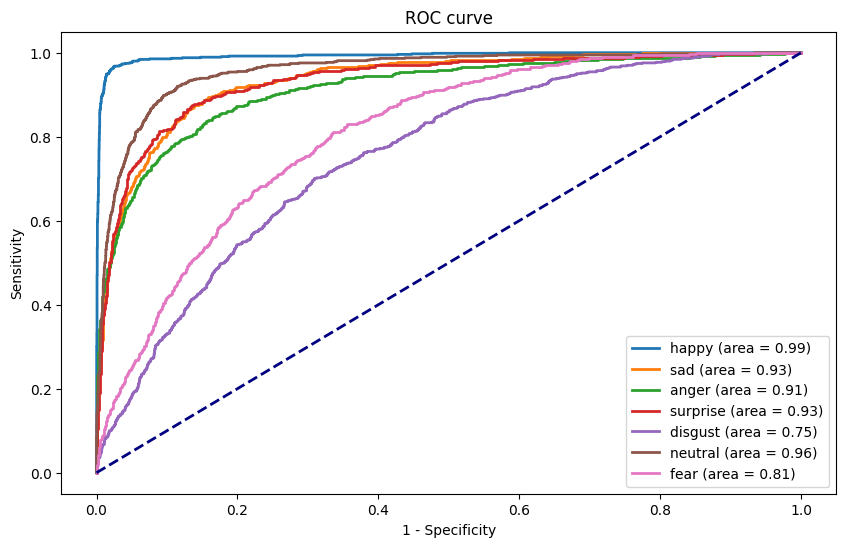

In [ ]:

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.applications import EfficientNetB7
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Flatten, Conv2D
from tensorflow.keras.regularizers import l2
from itertools import cycle
# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

model_name = 'effnetB7'

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)


    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    return image, label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)


# 모델 정의
image_shape = (64, 64, 1)  # 이미지 데이터의 형태



model_image_input = Input(shape=image_shape)  # 이미지 입력


# 입력 레이어
# 랜드마크와 유클리드 거리 서브넷

# 이미지 서브넷
effnet_model = EfficientNetB7(weights='imagenet', include_top=False, input_shape=(64, 64, 3))

# 이미지 입력
model_image_input = Input(shape=(64, 64, 1))

# 이미지 입력을 EfficientNetB0의 입력 형태에 맞게 조정
x_image = Conv2D(3, (1, 1), kernel_regularizer=l2(0.01))(model_image_input)  # 정규화 추가
x_image = effnet_model(x_image)

x_image = Flatten()(x_image)
x_image = Dropout(0.5)(x_image)  # 드롭아웃 추가
x_image = Dense(64, activation='relu', kernel_regularizer=l2(0.01))(x_image)  # 정규화 추가


# 출력 레이어
model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(x_image)

# 모델 정의
model_combined = Model(inputs= model_image_input, outputs=model_output)

# 모델 컴파일
# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)

import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []


y_test = []

for image, label in test_dataset:
    test_images.append(image)
    y_test.extend(label.numpy())

y_test_pred = model_combined.predict([np.vstack(test_images)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)


## Baseline: ResNet50

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_6"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)          │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 3)           │               6 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50 (Functional)                │ (None, 2, 2, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_6 (Flatten)                  │ (None, 8192)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)   

 Total params: 24,112,525 (91.98 MB)


 Trainable params: 24,059,405 (91.78 MB)


...

2219/2219 ━━━━━━━━━━━━━━━━━━━━ 154s 41ms/step - accuracy: 0.3941 - loss: 0.3819 - val_accuracy: 0.5878 - val_loss: 0.2183 - learning_rate: 1.0000e-04
Epoch 2/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 66s 28ms/step - accuracy: 0.6138 - loss: 0.1931 - val_accuracy: 0.6118 - val_loss: 0.1832 - learning_rate: 1.0000e-04
Epoch 3/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 65s 28ms/step - accuracy: 0.6392 - loss: 0.1661 - val_accuracy: 0.5047 - val_loss: 0.2251 - learning_rate: 1.0000e-04
Epoch 4/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 65s 28ms/step - accuracy: 0.6576 - loss: 0.1530 - val_accuracy: 0.6525 - val_loss: 0.1634 - learning_rate: 1.0000e-04
Epoch 5/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 66s 28ms/step - accuracy: 0.7554 - loss: 0.1073 - val_accuracy: 0.6578 - val_loss: 0.1670 - learning_rate: 1.0000e-04
Epoch 6/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 65s 28ms/step - accuracy: 0.8351 - loss: 0.0719 - val_accuracy: 0.6256 - val_loss: 0.2207 - learning_rate: 1.0000e-04
Epoch 7/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 65

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1136
Received: inputs=('Tensor(shape=(32, 64, 64, 1))',)
  warnings.warn(msg)


147/149 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1136
Received: inputs=('Tensor(shape=(None, 64, 64, 1))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step
Accuracy for happy: 0.95
Accuracy for sad: 0.61
Accuracy for anger: 0.73
Accuracy for surprise: 0.79
Accuracy for disgust: 0.35
Accuracy for neutral: 0.80
Accuracy for fear: 0.28
Precision: 0.63
Recall: 0.64
F1 Score: 0.63
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
resnet50 ROC AUC Score: 0.91


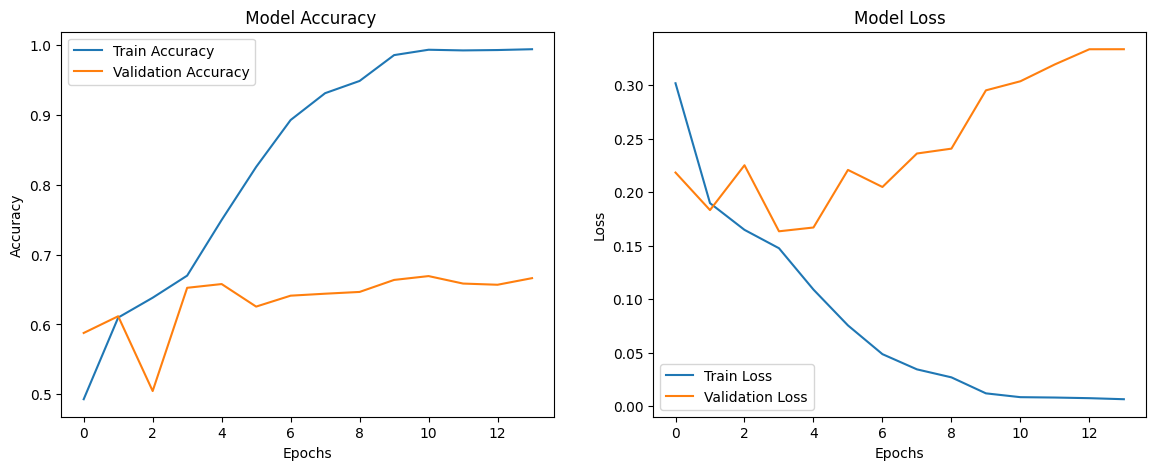

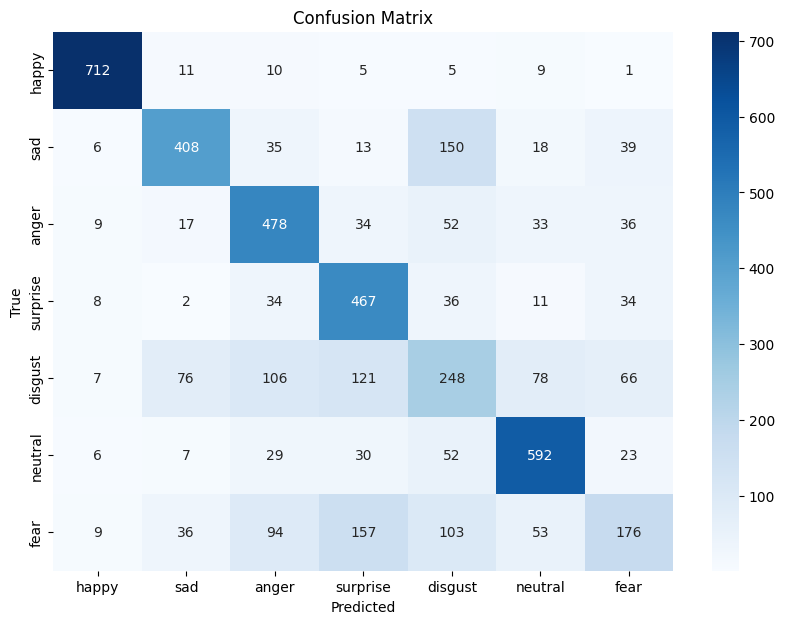

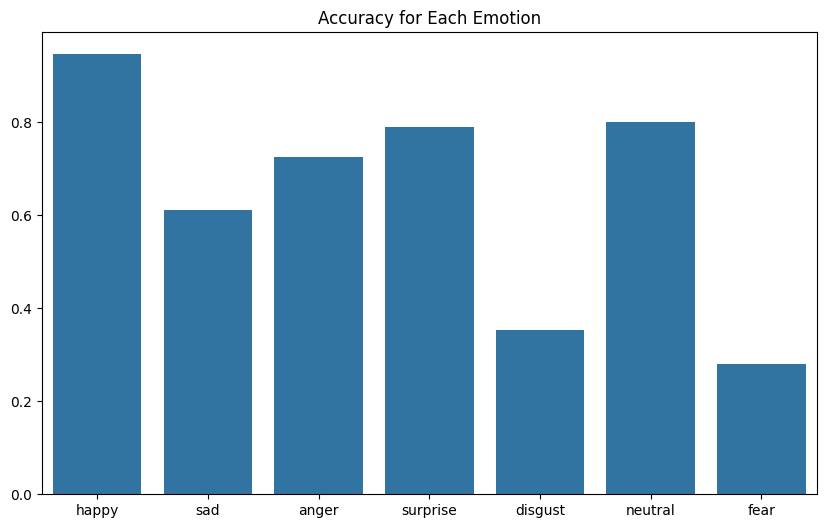

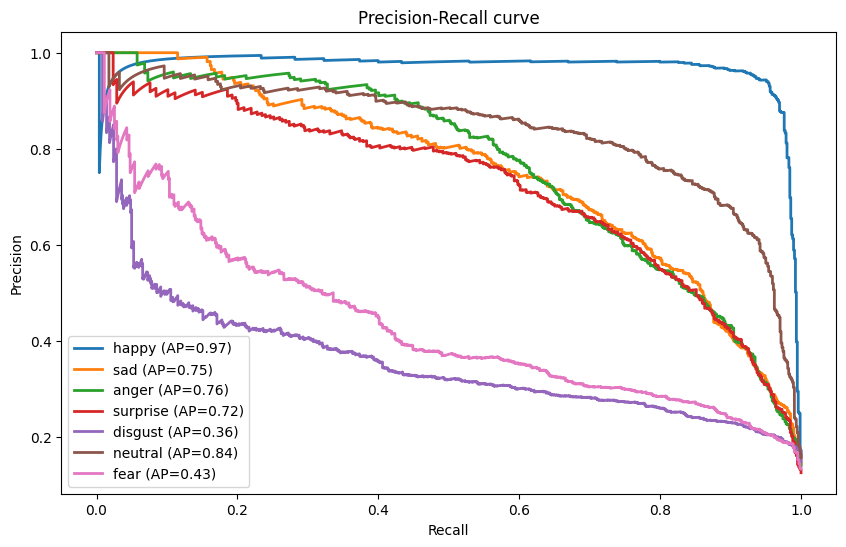

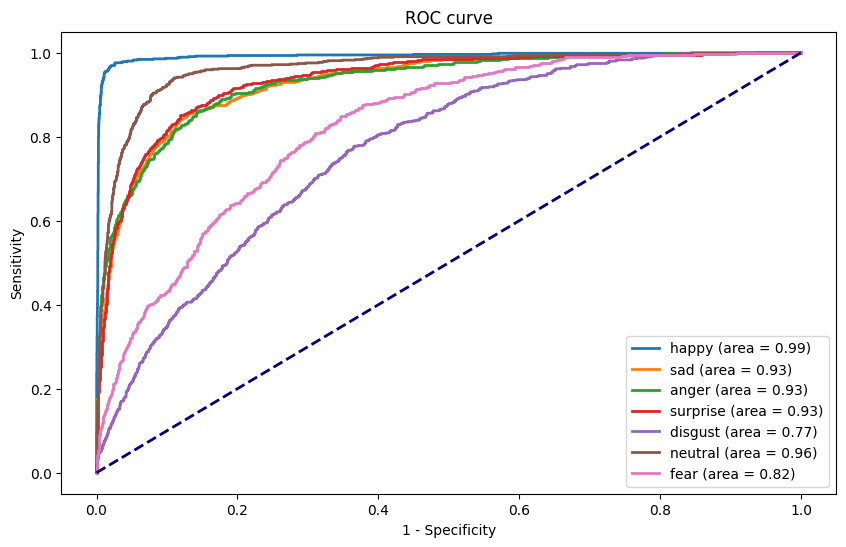

In [ ]:

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Flatten, Conv2D
from tensorflow.keras.regularizers import l2
# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

model_name = 'resnet50'


# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)


    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    return image, label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)


# 모델 정의
image_shape = (64, 64, 1)  # 이미지 데이터의 형태

model_image_input = Input(shape=image_shape)  # 이미지 입력


# 입력 레이어
# 랜드마크와 유클리드 거리 서브넷

# 이미지 서브넷
resnet_model = ResNet50(weights='imagenet', include_top=False, input_shape=(64, 64, 3))

model_image_input = Input(shape=(64, 64, 1))
x_image = Conv2D(3, (1, 1))(model_image_input)  # 1x1 convolution to change the number of channels
x_image = resnet_model(x_image)

x_image = Flatten()(x_image)
x_image = Dense(64, activation='relu')(x_image)

model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(x_image)

model_combined = Model(inputs=model_image_input, outputs=model_output)


# 모델 컴파일
# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)


import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')


plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []


y_test = []

for image, label in test_dataset:
    test_images.append(image)
    y_test.extend(label.numpy())

y_test_pred = model_combined.predict([np.vstack(test_images)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)


## Baseline: EfficientNetB0

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_7"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_18 (InputLayer)          │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 64, 64, 3)           │               6 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 2, 2, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_7 (Flatten)                  │ (None, 5120)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)

 Total params: 4,377,776 (16.70 MB)


 Trainable params: 4,335,753 (16.54 MB)


...

2219/2219 ━━━━━━━━━━━━━━━━━━━━ 174s 41ms/step - accuracy: 0.2508 - loss: 1.3685 - val_accuracy: 0.5022 - val_loss: 0.4132 - learning_rate: 1.0000e-04
Epoch 2/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 47s 20ms/step - accuracy: 0.5140 - loss: 0.3443 - val_accuracy: 0.5847 - val_loss: 0.2274 - learning_rate: 1.0000e-04
Epoch 3/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 48s 20ms/step - accuracy: 0.5959 - loss: 0.2100 - val_accuracy: 0.6185 - val_loss: 0.1938 - learning_rate: 1.0000e-04
Epoch 4/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 47s 20ms/step - accuracy: 0.6470 - loss: 0.1714 - val_accuracy: 0.6240 - val_loss: 0.1866 - learning_rate: 1.0000e-04
Epoch 5/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 47s 20ms/step - accuracy: 0.6961 - loss: 0.1438 - val_accuracy: 0.6305 - val_loss: 0.1850 - learning_rate: 1.0000e-04
Epoch 6/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 47s 20ms/step - accuracy: 0.7450 - loss: 0.1188 - val_accuracy: 0.6277 - val_loss: 0.1996 - learning_rate: 1.0000e-04
Epoch 7/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 47

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1381
Received: inputs=('Tensor(shape=(32, 64, 64, 1))',)
  warnings.warn(msg)


142/149 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1381
Received: inputs=('Tensor(shape=(None, 64, 64, 1))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 12s 44ms/step
Accuracy for happy: 0.95
Accuracy for sad: 0.55
Accuracy for anger: 0.70
Accuracy for surprise: 0.71
Accuracy for disgust: 0.27
Accuracy for neutral: 0.84
Accuracy for fear: 0.30
Precision: 0.60
Recall: 0.62
F1 Score: 0.60
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
effnetB0 ROC AUC Score: 0.89


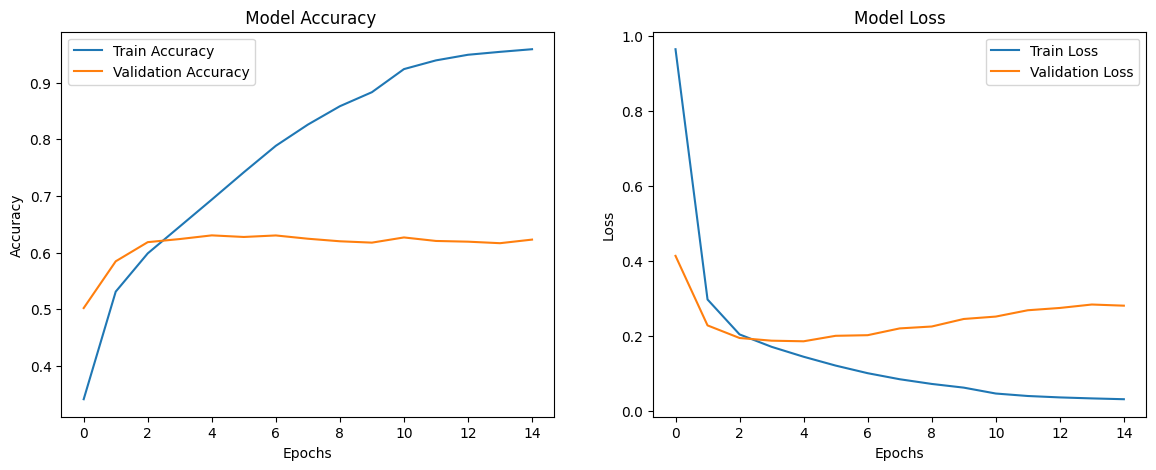

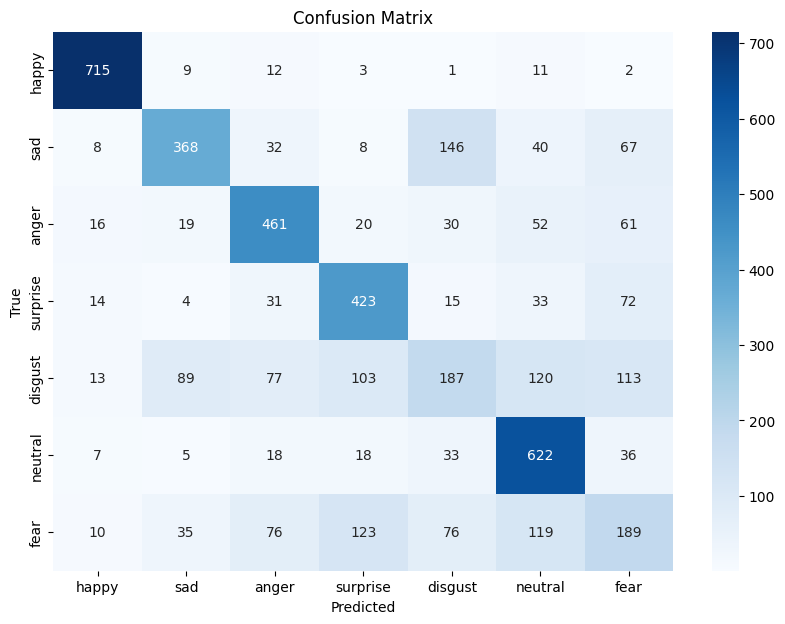

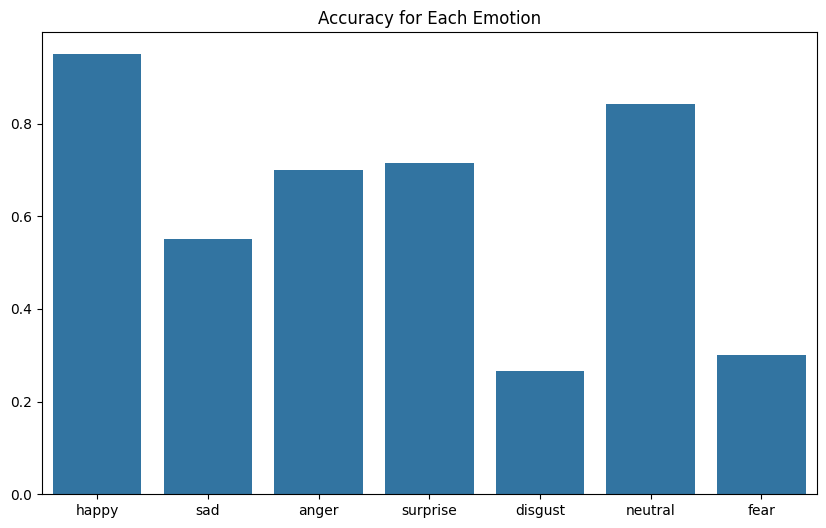

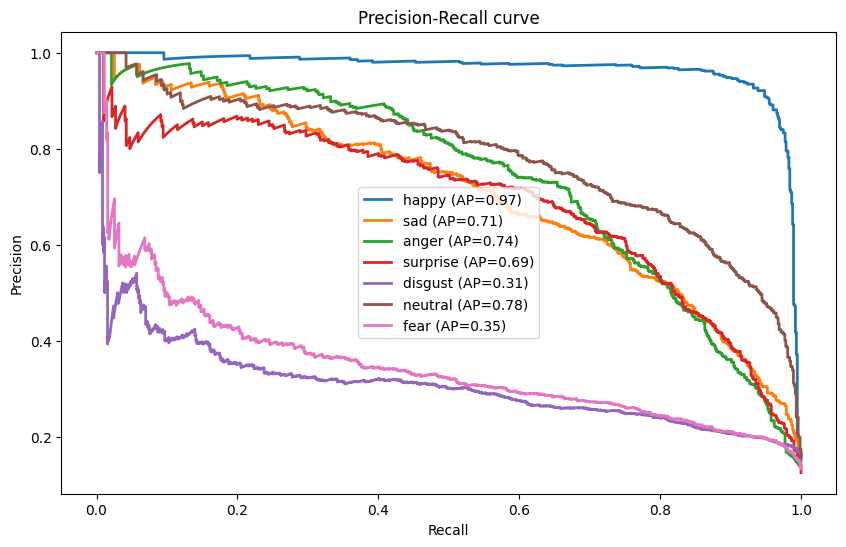

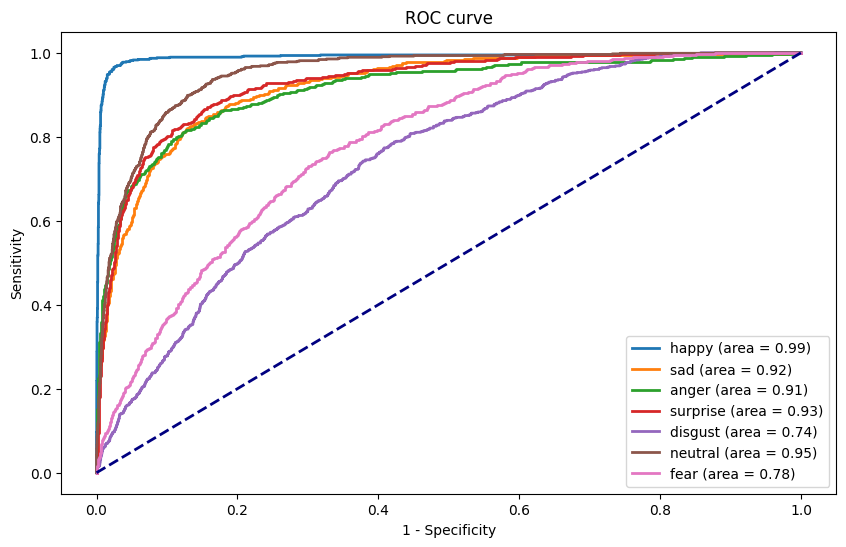

In [ ]:

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Flatten, Conv2D
from tensorflow.keras.regularizers import l2
from itertools import cycle
# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}
model_name = 'effnetB0'

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)


    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    return image, label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"



train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)


# 모델 정의
image_shape = (64, 64, 1)  # 이미지 데이터의 형태



model_image_input = Input(shape=image_shape)  # 이미지 입력


# 입력 레이어
# 랜드마크와 유클리드 거리 서브넷

# 이미지 서브넷
effnet_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(64, 64, 3))

# 이미지 입력
model_image_input = Input(shape=(64, 64, 1))

# 이미지 입력을 EfficientNetB0의 입력 형태에 맞게 조정
x_image = Conv2D(3, (1, 1), kernel_regularizer=l2(0.01))(model_image_input)  # 정규화 추가
x_image = effnet_model(x_image)

x_image = Flatten()(x_image)
x_image = Dropout(0.5)(x_image)  # 드롭아웃 추가
x_image = Dense(64, activation='relu', kernel_regularizer=l2(0.01))(x_image)  # 정규화 추가


# 출력 레이어
model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(x_image)

# 모델 정의
model_combined = Model(inputs= model_image_input, outputs=model_output)

# 모델 컴파일
# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)


import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')


plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []


y_test = []

for image, label in test_dataset:
    test_images.append(image)
    y_test.extend(label.numpy())

y_test_pred = model_combined.predict([np.vstack(test_images)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)


## Baseline: MobileNet

<ipython-input-15-92beb225ad91>:78: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet_model = MobileNet(weights='imagenet', include_top=False, input_shape=(64, 64, 3))


17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_8"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_21 (InputLayer)          │ (None, 64, 64, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 64, 64, 3)           │               6 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenet_1.00_224 (Functional)      │ (None, 2, 2, 1024)          │       3,228,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_8 (Flatten)                  │ (None, 4096)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization

 Total params: 3,507,917 (13.38 MB)


...

2219/2219 ━━━━━━━━━━━━━━━━━━━━ 67s 16ms/step - accuracy: 0.2354 - loss: 0.5927 - val_accuracy: 0.4515 - val_loss: 0.3159 - learning_rate: 1.0000e-04
Epoch 2/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 23s 9ms/step - accuracy: 0.4363 - loss: 0.3082 - val_accuracy: 0.5253 - val_loss: 0.2399 - learning_rate: 1.0000e-04
Epoch 3/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 23s 9ms/step - accuracy: 0.5234 - loss: 0.2352 - val_accuracy: 0.5716 - val_loss: 0.2043 - learning_rate: 1.0000e-04
Epoch 4/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 23s 9ms/step - accuracy: 0.5869 - loss: 0.1937 - val_accuracy: 0.5974 - val_loss: 0.1844 - learning_rate: 1.0000e-04
Epoch 5/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 23s 9ms/step - accuracy: 0.6248 - loss: 0.1673 - val_accuracy: 0.6114 - val_loss: 0.1805 - learning_rate: 1.0000e-04
Epoch 6/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 23s 9ms/step - accuracy: 0.6697 - loss: 0.1425 - val_accuracy: 0.6235 - val_loss: 0.1803 - learning_rate: 1.0000e-04
Epoch 7/100
2219/2219 ━━━━━━━━━━━━━━━━━━━━ 23s 9ms/

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1475
Received: inputs=('Tensor(shape=(32, 64, 64, 1))',)
  warnings.warn(msg)


146/149 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1475
Received: inputs=('Tensor(shape=(None, 64, 64, 1))',)
  warnings.warn(msg)


149/149 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step
Accuracy for happy: 0.94
Accuracy for sad: 0.67
Accuracy for anger: 0.69
Accuracy for surprise: 0.76
Accuracy for disgust: 0.24
Accuracy for neutral: 0.67
Accuracy for fear: 0.34
Precision: 0.60
Recall: 0.62
F1 Score: 0.60
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
monet ROC AUC Score: 0.89


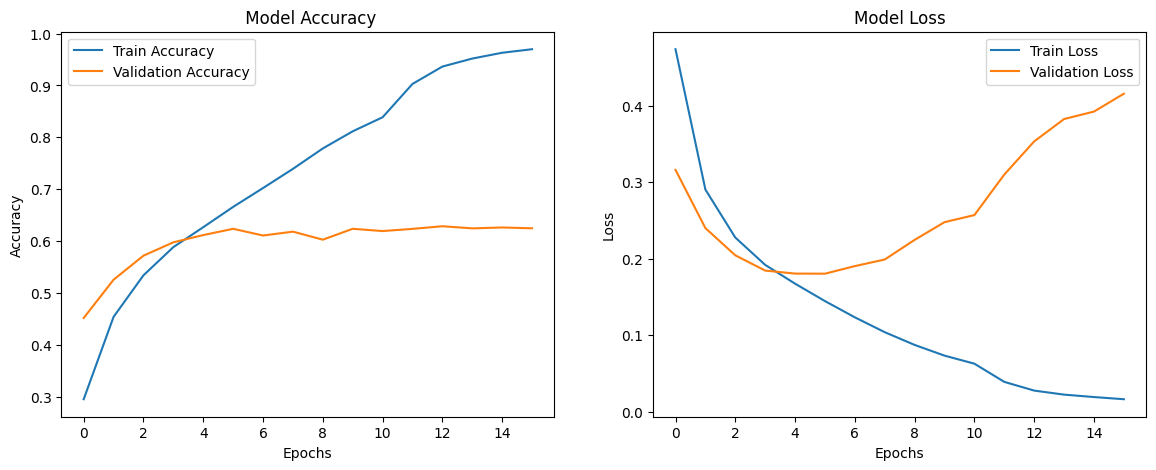

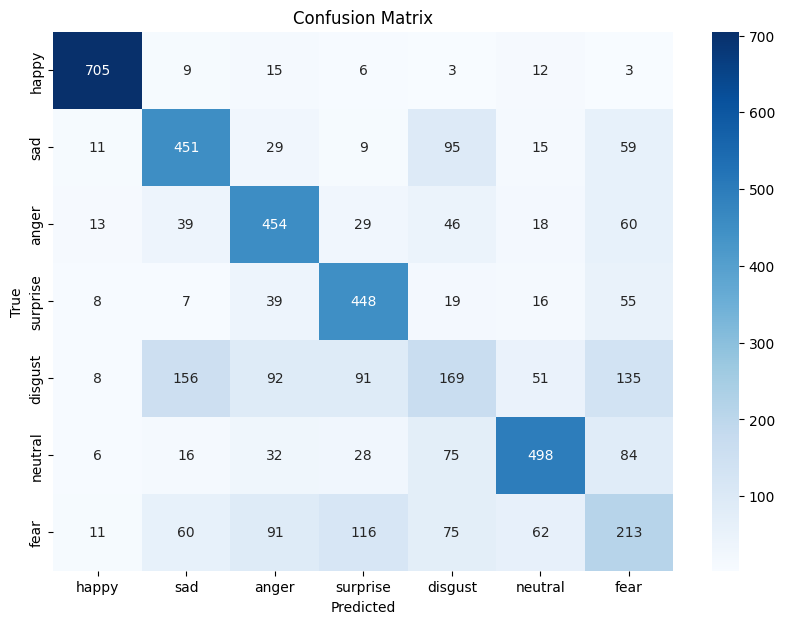

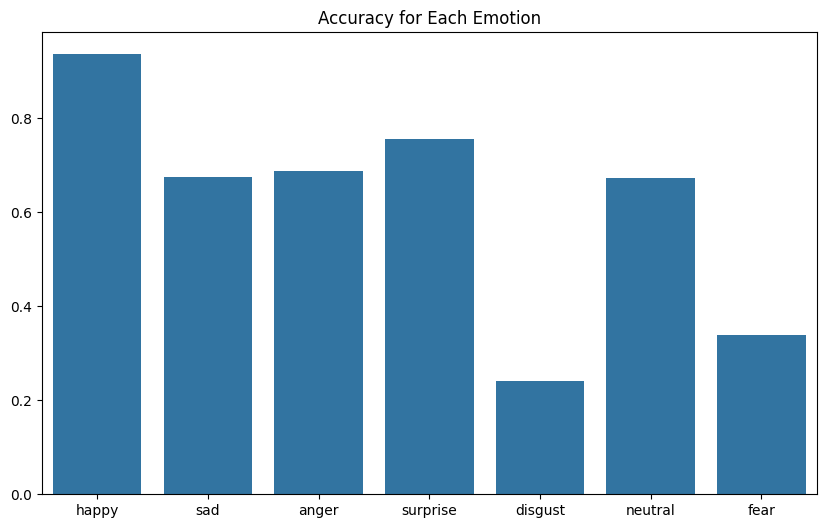

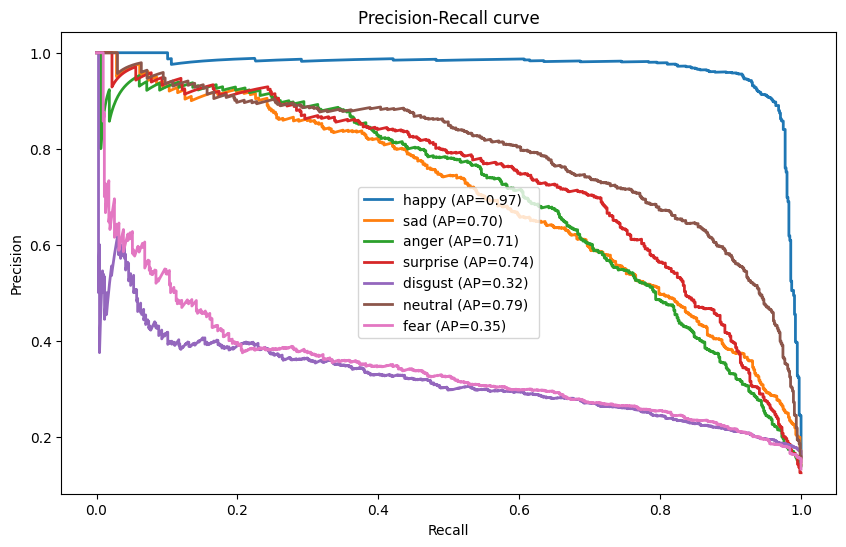

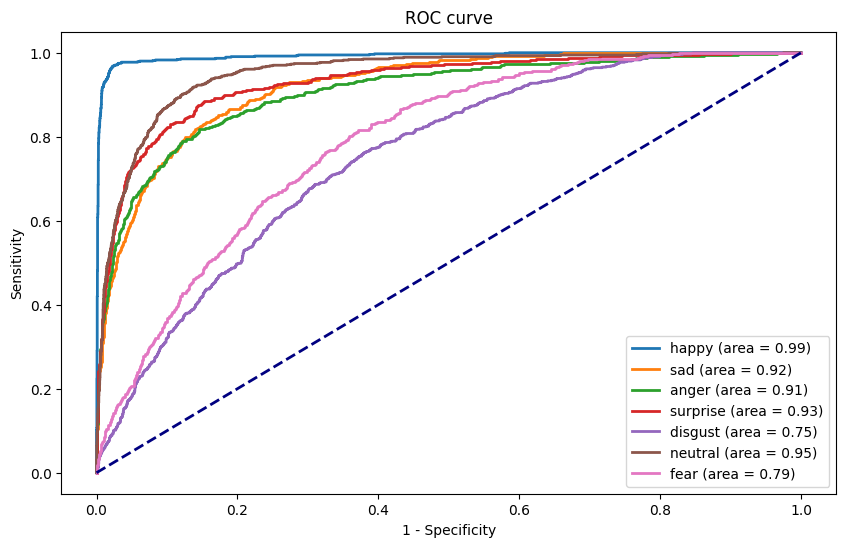

In [ ]:

# 필요한 라이브러리 임포트
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Activation, Concatenate
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import itertools
from keras import backend as K
from tensorflow.keras.regularizers import l2
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Flatten, Conv2D
from tensorflow.keras.regularizers import l2
# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3,
    "disgust": 4, "neutral": 5, "fear": 6,
}

model_name = 'monet'

# TFRecord 파싱 함수
def parse_and_prepare_tfrecord(tfrecord):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(tfrecord, features)

    image = tf.io.decode_jpeg(parsed_features["image"])
    image = tf.image.resize(image, [64, 64])
    image = tf.image.rgb_to_grayscale(image)
    image = tf.expand_dims(image, -1)
    image = tf.squeeze(image, axis=-1)


    label = tf.one_hot(parsed_features["label"], depth=len(emotion_labels))

    return image, label

# 데이터셋 로드 및 준비
def load_and_prepare_dataset(tfrecord_file, batch_size=None):
    dataset = tf.data.TFRecordDataset(tfrecord_file)
    dataset = dataset.map(parse_and_prepare_tfrecord)
    if batch_size is not None:
        dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord"
val_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord"
test_tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord"


train_dataset = load_and_prepare_dataset(train_tfrecord_file).batch(batch_size)
val_dataset = load_and_prepare_dataset(val_tfrecord_file).batch(batch_size)
test_dataset = load_and_prepare_dataset(test_tfrecord_file).batch(batch_size)


# 모델 정의
image_shape = (64, 64, 1)  # 이미지 데이터의 형태

model_image_input = Input(shape=image_shape)  # 이미지 입력


# 입력 레이어
# 랜드마크와 유클리드 거리 서브넷

# 이미지 서브넷
mobilenet_model = MobileNet(weights='imagenet', include_top=False, input_shape=(64, 64, 3))

model_image_input = Input(shape=(64, 64, 1))
x_image = Conv2D(3, (1, 1))(model_image_input)  # 1x1 convolution to change the number of channels
x_image = mobilenet_model(x_image)

x_image = Flatten()(x_image)
x_image = BatchNormalization()(x_image)  # 배치 정규화 레이어 추가
x_image = Dense(64, activation='relu')(x_image)
x_image = Dropout(0.5)(x_image)  # 드롭아웃 레이어 추가

model_output = Dense(len(emotion_labels), activation='softmax', kernel_regularizer=l2(0.01))(x_image)

model_combined = Model(inputs=model_image_input, outputs=model_output)


# 모델 컴파일
# 모델 컴파일
def focal_loss(gamma=2.0, alpha=0.25):
    def focal_loss_fixed(y_true, y_pred):
        # y_true: 실제 레이블, y_pred: 모델 예측
        pt = y_pred * y_true + (1 - y_pred) * (1 - y_true)
        pt = tf.keras.backend.clip(pt, tf.keras.backend.epsilon(), 1.0)  # epsilon 사용
        return -tf.keras.backend.sum(alpha * tf.keras.backend.pow(1 - pt, gamma) * tf.keras.backend.log(pt), axis=-1)

    return focal_loss_fixed
# 모델 컴파일
model_combined.compile(
    optimizer=Adam(learning_rate=learning_rate_combined),  # decreased learning rate
    loss=focal_loss(),
    metrics=['accuracy'])

# 모델 요약
model_combined.summary()

# Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=patience_es, restore_best_weights=True)
train_dataset = train_dataset.shuffle(buffer_size=10000)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=factor_lr, patience=patience_lr, min_lr=1e-6)

# 모델 훈련
history = model_combined.fit(
    x=train_dataset,  # 데이터 증강이 적용된 훈련 데이터셋
    epochs=epochs,
    validation_data=val_dataset,  # 데이터 증강이 적용되지 않은 검증 데이터셋
    callbacks=[early_stopping, reduce_lr]
)

import os

# Google Drive 경로 설정
drive_path = '/content/drive/MyDrive/FINAL'

# 디렉토리가 존재하지 않으면 생성
if not os.path.exists(drive_path):
    os.makedirs(drive_path)

# 파일 경로 설정
accuracy_loss_path = os.path.join(drive_path, f'{model_name}_accuracy_loss.png')
confusion_matrix_path = os.path.join(drive_path, f'{model_name}_confusion_matrix.png')
emotion_accuracy_path = os.path.join(drive_path, f'{model_name}_emotion_accuracy.png')
precision_recall_curve_path = os.path.join(drive_path, f'{model_name}_precision_recall_curve.png')
roc_curve_path = os.path.join(drive_path, f'{model_name}_roc_curve.png')
pr_curve_data_path = os.path.join(drive_path, f'{model_name}_pr_curve_data.csv')
roc_curve_data_path = os.path.join(drive_path, f'{model_name}_roc_curve_data.csv')
model_save_path_h5 = os.path.join(drive_path, f'{model_name}_model.h5')
model_save_path_keras = os.path.join(drive_path, f'{model_name}_model.keras')
summary_path = os.path.join(drive_path, f'{model_name}_data.txt')

plt.figure(figsize=(14, 5))

# 첫 번째 서브플롯 - 정확도
plt.subplot(1, 2, 1)  # 1행 2열의 첫 번째 서브플롯
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title(f' Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 두 번째 서브플롯 - 손실
plt.subplot(1, 2, 2)  # 1행 2열의 두 번째 서브플롯
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title(f'Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.savefig(accuracy_loss_path)

# Evaluate the model
test_loss, test_accuracy = model_combined.evaluate(test_dataset, verbose=1)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# 혼돈 행렬 생성 및 시각화
test_images = []


y_test = []

for image, label in test_dataset:
    test_images.append(image)
    y_test.extend(label.numpy())

y_test_pred = model_combined.predict([np.vstack(test_images)])

# 모든 이미지와 랜드마크에 대한 예측 수행
y_test = np.argmax(y_test, axis=1)
y_test_pred = np.argmax(y_test_pred, axis=1)

# 혼돈 행렬 생성 및 시각화
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 7))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=list(emotion_labels.keys()), yticklabels=list(emotion_labels.keys()))
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'Confusion Matrix')
plt.savefig(confusion_matrix_path)

# 각각의 감정에 대한 분류 정확도 계산 및 시각화
emotion_accuracy_dict = {}
for emotion in emotion_labels:
    emotion_index = emotion_labels[emotion]
    emotion_accuracy = accuracy_score(y_test[y_test == emotion_index], y_test_pred[y_test == emotion_index])
    emotion_accuracy_dict[emotion] = emotion_accuracy
    print(f"Accuracy for {emotion}: {emotion_accuracy:.2f}")

# 감정별 정확도를 바 차트로 시각화
plt.figure(figsize=(10, 6))
sns.barplot(x=list(emotion_accuracy_dict.keys()), y=list(emotion_accuracy_dict.values()))
plt.title(f'Accuracy for Each Emotion')
plt.savefig(emotion_accuracy_path)

# 정밀도, 재현율, F1 스코어 계산
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, auc, precision_recall_curve

# 정밀도, 재현율, F1 스코어 계산
precision = precision_score(y_test, y_test_pred, average='macro')
recall = recall_score(y_test, y_test_pred, average='macro')
f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# AUC 스코어 계산
# 감정 레이블이 다중 클래스이므로, AUC 계산을 위해 one-vs-rest 방식을 적용해야 합니다.
# 각 클래스에 대해 확률을 계산해야 하므로, 모델의 예측을 확률로 변경합니다.
# Model prediction
y_test_prob = model_combined.predict([np.vstack(test_images)])
roc_auc = roc_auc_score(y_test, y_test_prob, multi_class='ovr', average="macro")
print(f"{model_name} ROC AUC Score: {roc_auc:.2f}")

# Plot PR curve
precision_dict = {}
recall_dict = {}
average_precision_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    precision_dict[emotion], recall_dict[emotion], _ = precision_recall_curve(y_test == i, y_test_prob[:, i])
    average_precision_dict[emotion] = average_precision_score(y_test == i, y_test_prob[:, i])
    plt.plot(recall_dict[emotion], precision_dict[emotion], lw=2,
             label=f'{emotion} (AP={average_precision_dict[emotion]:.2f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall curve')
plt.legend(loc="best")
plt.savefig(precision_recall_curve_path)

# Plot ROC curve
fpr_dict = {}
tpr_dict = {}
plt.figure(figsize=(10, 6))

for i, emotion in enumerate(emotion_labels):
    fpr_dict[emotion], tpr_dict[emotion], _ = roc_curve(y_test == i, y_test_prob[:, i])
    plt.plot(fpr_dict[emotion], tpr_dict[emotion], lw=2, label=f'{emotion} (area = {auc(fpr_dict[emotion], tpr_dict[emotion]):.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('1 - Specificity')
plt.ylabel('Sensitivity')
plt.title(f'ROC curve')
plt.legend(loc="best")
plt.savefig(roc_curve_path)

# Create empty dataframes to store PR and ROC curve data
pr_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AP', 'Recall', 'Precision'])
roc_curve_data = pd.DataFrame(columns=['Model', 'Emotion', 'AUC', 'FPR', 'TPR'])

# Store PR curve data
temp_data = []

for i, emotion in enumerate(emotion_labels):
    for r, p in zip(recall_dict[emotion], precision_dict[emotion]):
        temp_data.append({'Model': model_name, 'Emotion': emotion, 'AP': average_precision_dict[emotion], 'Recall': r, 'Precision': p})

pr_curve_data = pd.DataFrame(temp_data)

# Store ROC curve data
temp_roc_data = []

for i, emotion in enumerate(emotion_labels):
    for f, t in zip(fpr_dict[emotion], tpr_dict[emotion]):
        temp_roc_data.append({
            'Model': model_name,
            'Emotion': emotion,
            'AUC': auc(fpr_dict[emotion], tpr_dict[emotion]),
            'FPR': f,
            'TPR': t
        })

roc_curve_data = pd.DataFrame(temp_roc_data)
pr_curve_data.to_csv(pr_curve_data_path, index=False)
roc_curve_data.to_csv(roc_curve_data_path, index=False)

with open(summary_path, 'w') as f:
    f.write(f"Test Loss: {test_loss}\n")
    f.write(f"Test Accuracy: {test_accuracy}\n")
    for emotion, accuracy in emotion_accuracy_dict.items():
        f.write(f"Accuracy for {emotion}: {accuracy:.3f}\n")
    f.write(f"Precision: {precision:.3f}\n")
    f.write(f"Recall: {recall:.3f}\n")
    f.write(f"F1 Score: {f1:.3f}\n")
    f.write(f"{model_name} ROC AUC Score: {roc_auc:.3f}\n")

model_combined.save(model_save_path_h5)
model_combined.save(model_save_path_keras)


## Precision–Recall curves

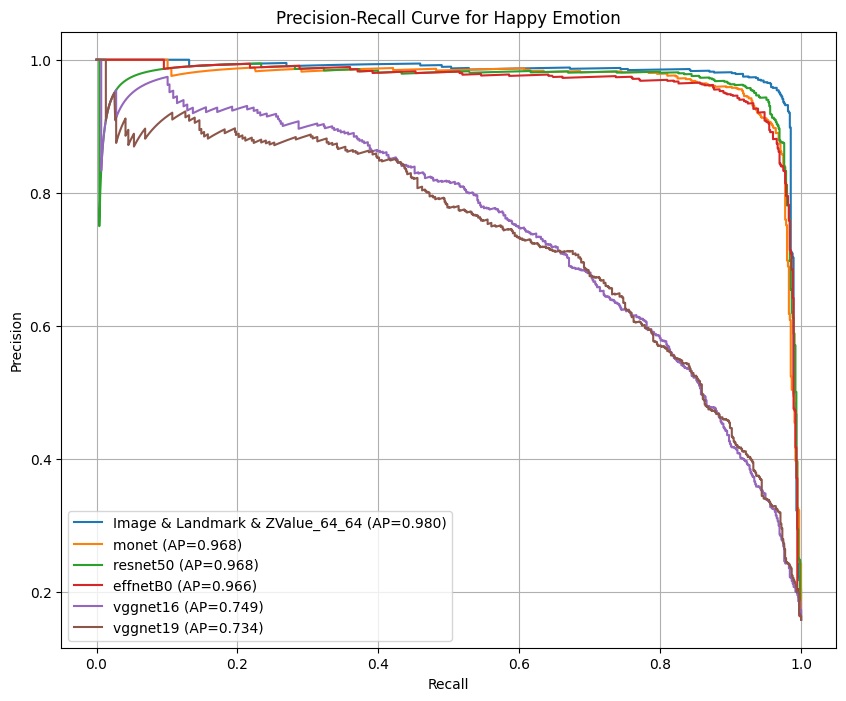

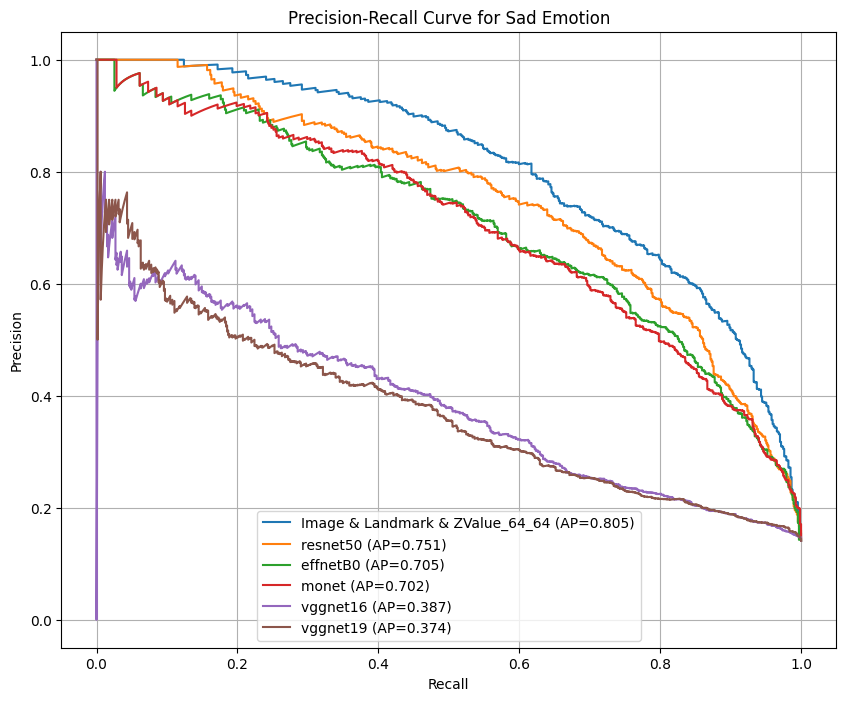

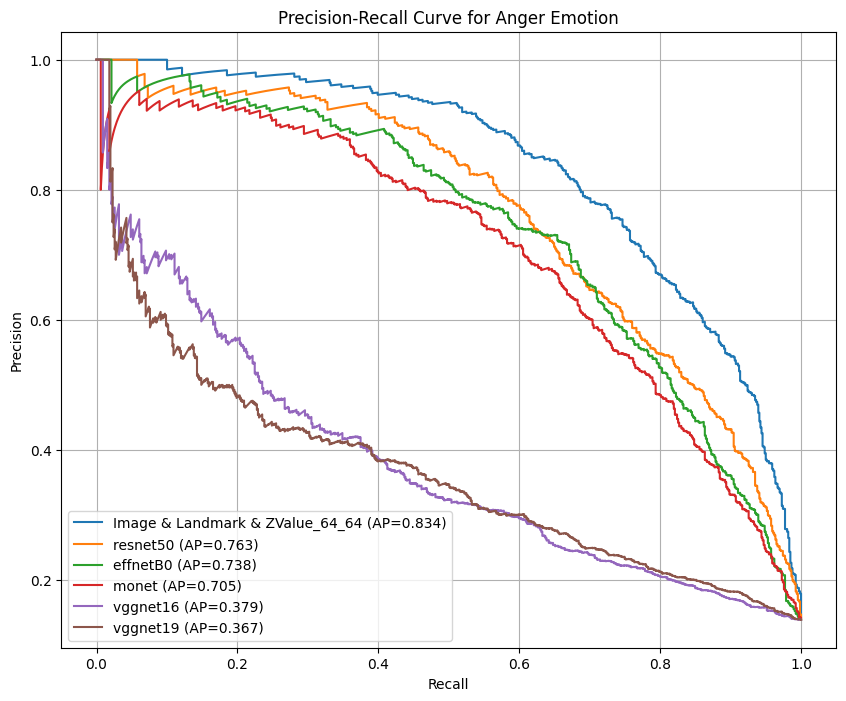

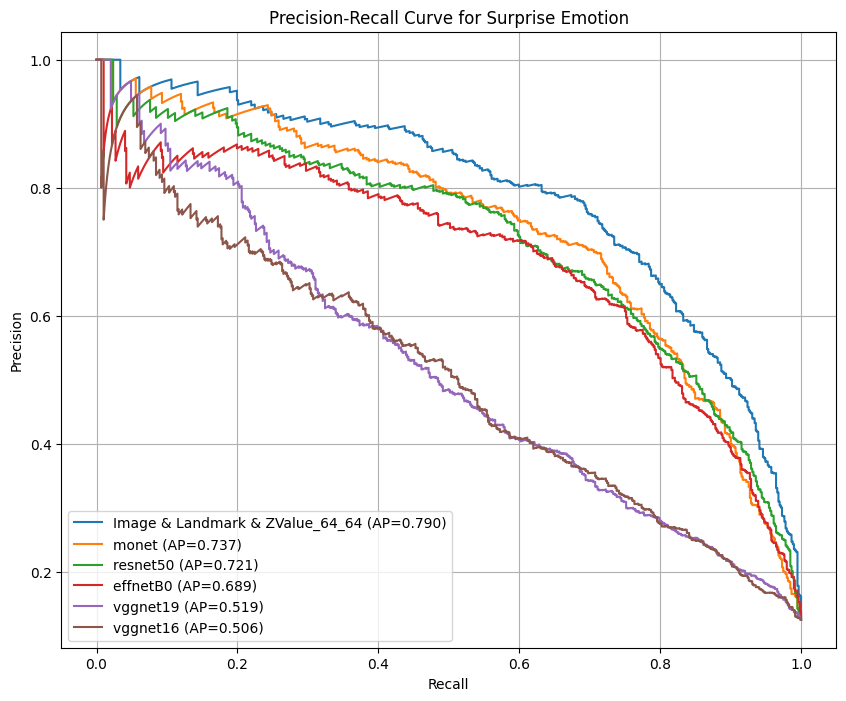

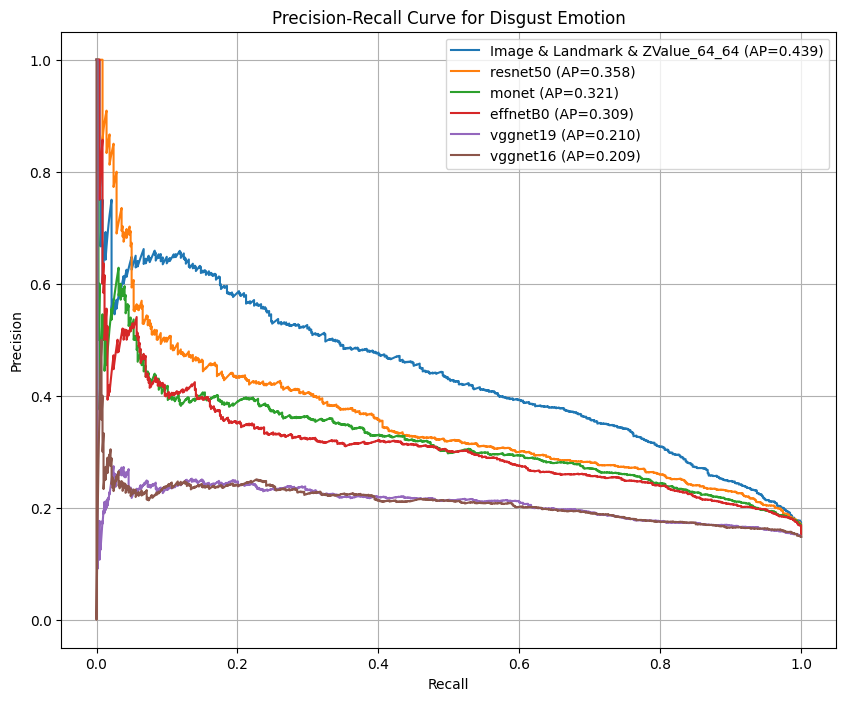

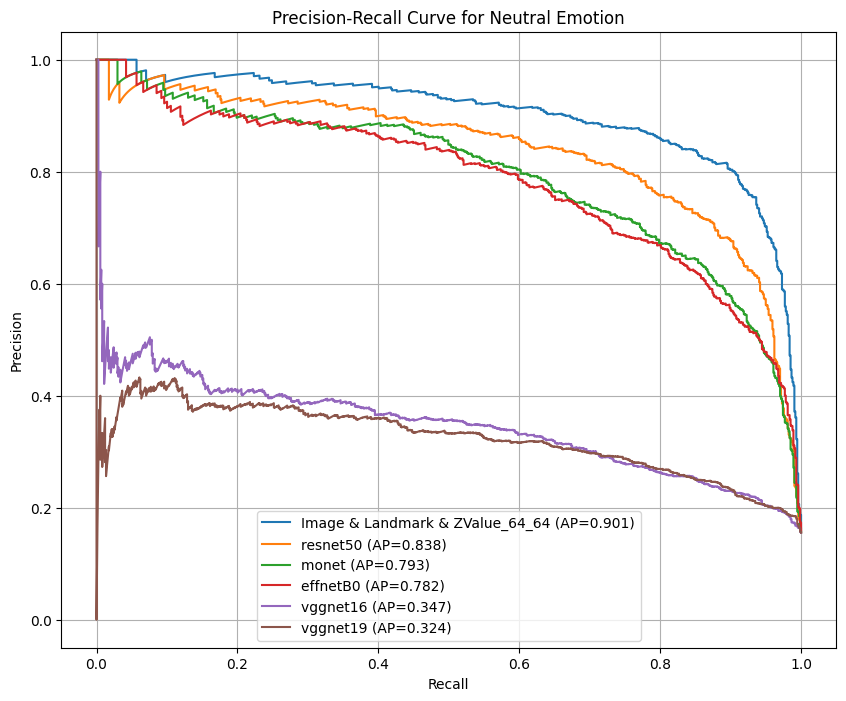

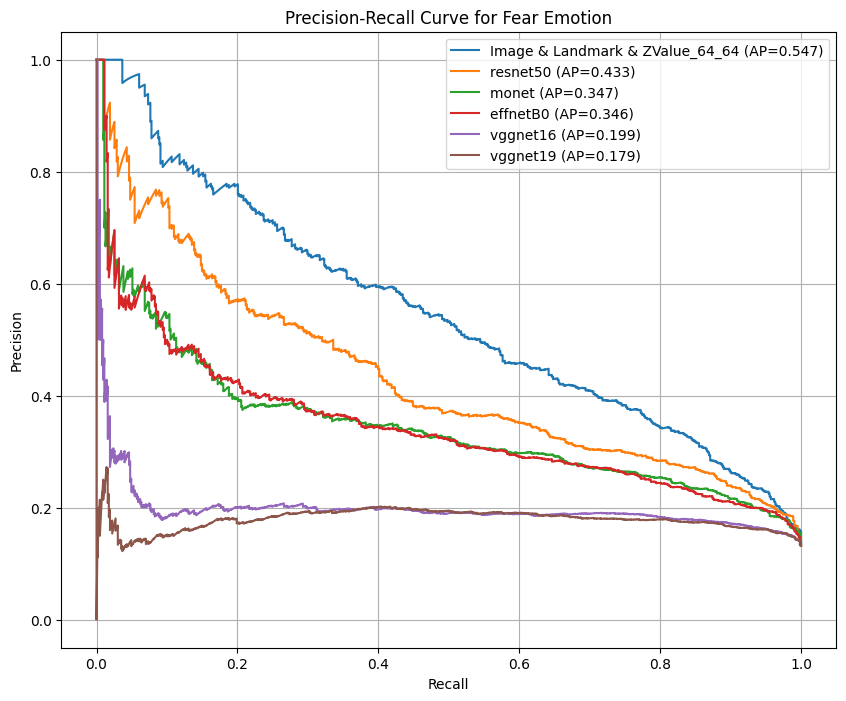

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 파일 목록
pr_files = [
    '/content/drive/MyDrive/02_04_new/Image & Landmark & ZValue_64_64_pr_curve_data.csv',
    '/content/drive/MyDrive/FINAL/monet_pr_curve_data.csv',
    '/content/drive/MyDrive/FINAL/resnet50_pr_curve_data.csv',
    '/content/drive/MyDrive/FINAL/vggnet16_pr_curve_data.csv',
    '/content/drive/MyDrive/FINAL/vggnet19_pr_curve_data.csv',
    '/content/drive/MyDrive/FINAL/effnetB0_pr_curve_data.csv'
]

# 감정 목록 (소문자)
emotions = ["happy", "sad", "anger", "surprise", "disgust", "neutral", "fear"]

# 각 감정별 평균 AP 저장
average_precision_dict = {}

# 각 감정별로 PR 곡선 그리기
for emotion in emotions:
    plt.figure(figsize=(10, 8))

    # 각 파일에 대해 평균 precision-recall 곡선을 계산
    model_data = []
    for file in pr_files:
        df = pd.read_csv(file)
        model_name = file.split('/')[-1].split('_pr_curve_data.csv')[0]  # 파일 이름에서 모델 이름 추출

        # 감정 컬럼을 소문자로 변환하여 필터링
        df['Emotion'] = df['Emotion'].str.lower()
        emotion_data = df[df['Emotion'] == emotion]

        if not emotion_data.empty:
            # Precision-Recall 곡선 데이터 추출
            precision = emotion_data['Precision']
            recall = emotion_data['Recall']
            average_precision = np.mean(emotion_data['AP'])
            average_precision_dict[emotion] = average_precision
            model_data.append((model_name, recall, precision, average_precision))

    # AP 높은 순서대로 정렬
    model_data.sort(key=lambda x: x[3], reverse=True)

    for model_name, recall, precision, average_precision in model_data:
        plt.plot(recall, precision, label=f'{model_name} (AP={average_precision:.3f})')

    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve for {emotion.capitalize()} Emotion')
    plt.legend()
    plt.grid(True)
    plt.show()


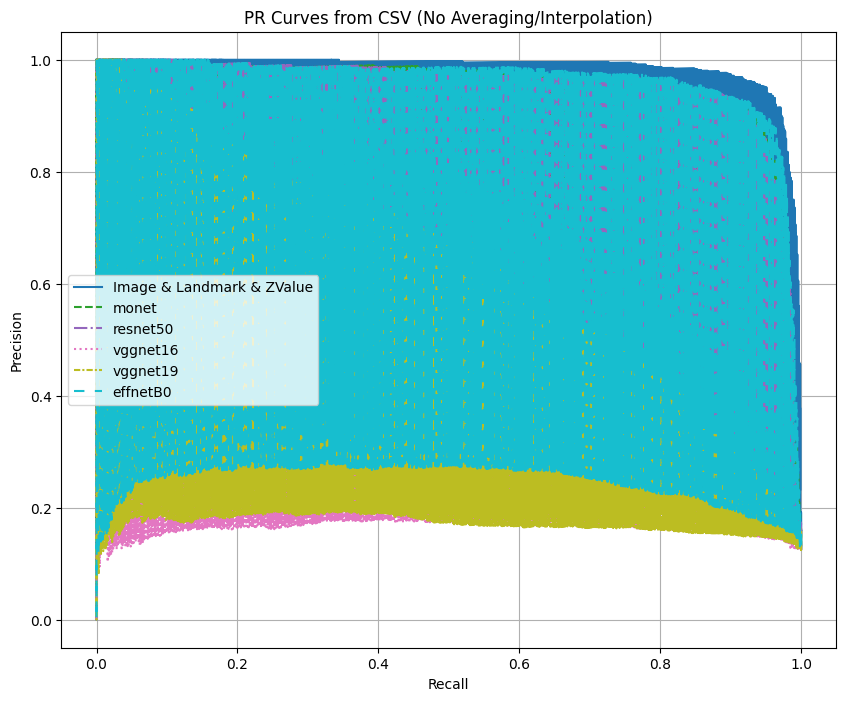

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1) CSV 파일들: 각 파일에 'Recall', 'Precision' 열이 있다고 가정
pr_files = [
    '/content/drive/MyDrive/FINAL/Image & Landmark & ZValue_pr_curve_data.csv',
    '/content/drive/MyDrive/FINAL/monet_pr_curve_data.csv',
    '/content/drive/MyDrive/FINAL/resnet50_pr_curve_data.csv',
    '/content/drive/MyDrive/FINAL/vggnet16_pr_curve_data.csv',
    '/content/drive/MyDrive/FINAL/vggnet19_pr_curve_data.csv',
    '/content/drive/MyDrive/FINAL/effnetB0_pr_curve_data.csv'
]

# 2) 한 Figure 안에 모델별 곡선 겹쳐 그리기
plt.figure(figsize=(10, 8))

colors = plt.cm.tab10(np.linspace(0, 1, len(pr_files)))  # 모델별 색상
linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 5))]  # 선 스타일들

for (file_path, color, ls) in zip(pr_files, colors, linestyles):
    # 파일에서 모델 이름 추출
    model_name = file_path.split('/')[-1].split('_pr_curve_data.csv')[0]
    df = pd.read_csv(file_path)

    # 단순히 Recall 오름차순 정렬 (사실 감정별로 섞여 있으면 의미가 애매할 수 있음)
    df_sorted = df.sort_values('Recall')

    # 그래프 그리기 (모든 행을 하나로 연결)
    plt.plot(
        df_sorted['Recall'],
        df_sorted['Precision'],
        label=model_name,
        color=color,
        linestyle=ls
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR Curves from CSV (No Averaging/Interpolation)')
plt.legend()
plt.grid(True)
plt.show()


## ROC curves

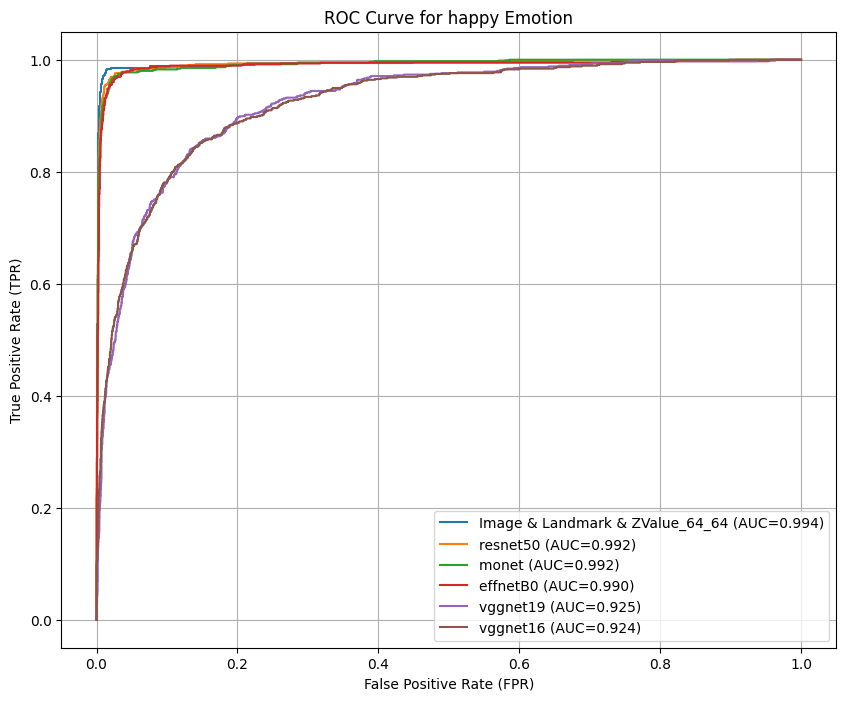

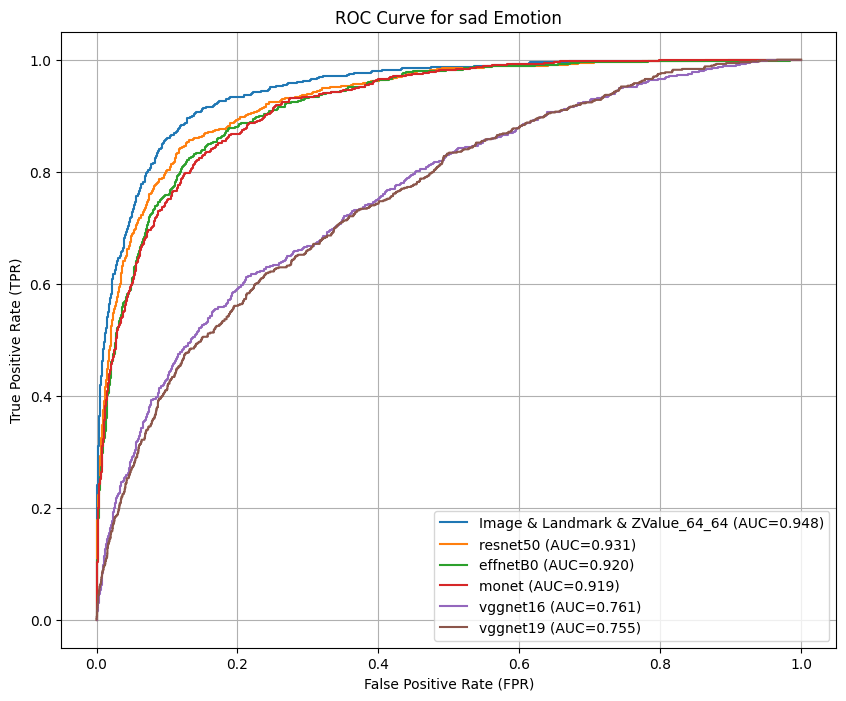

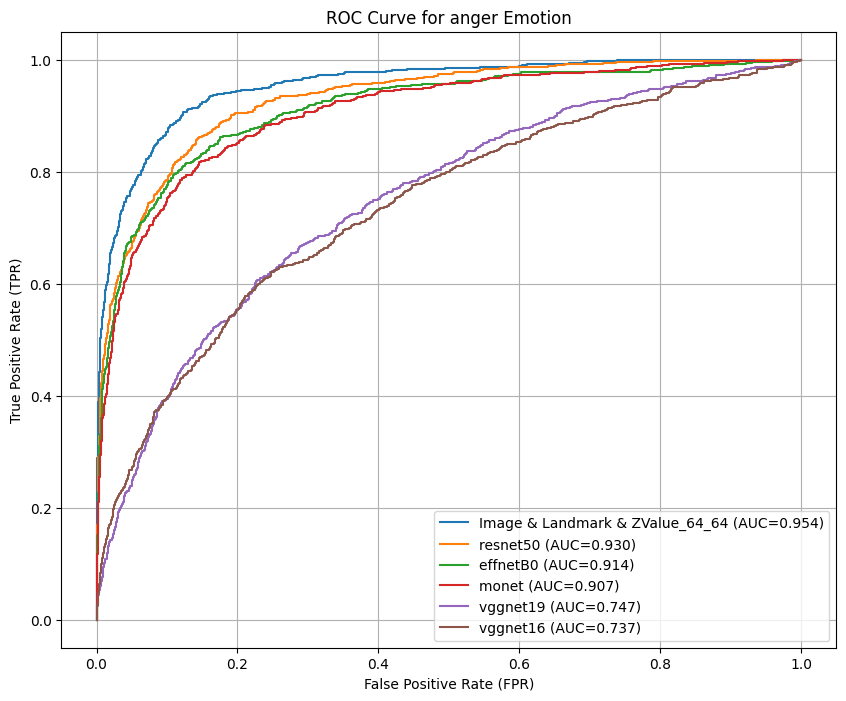

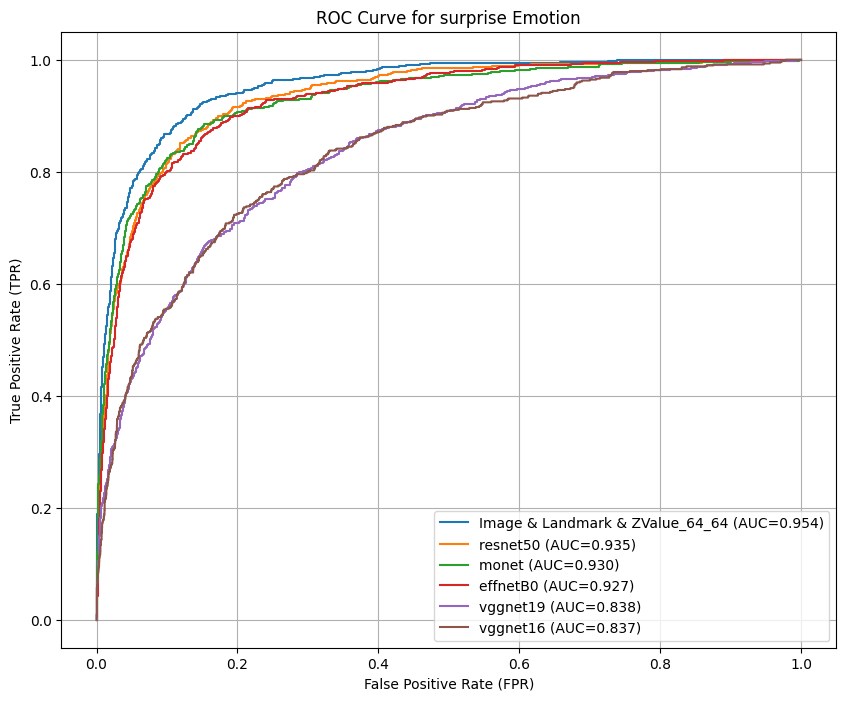

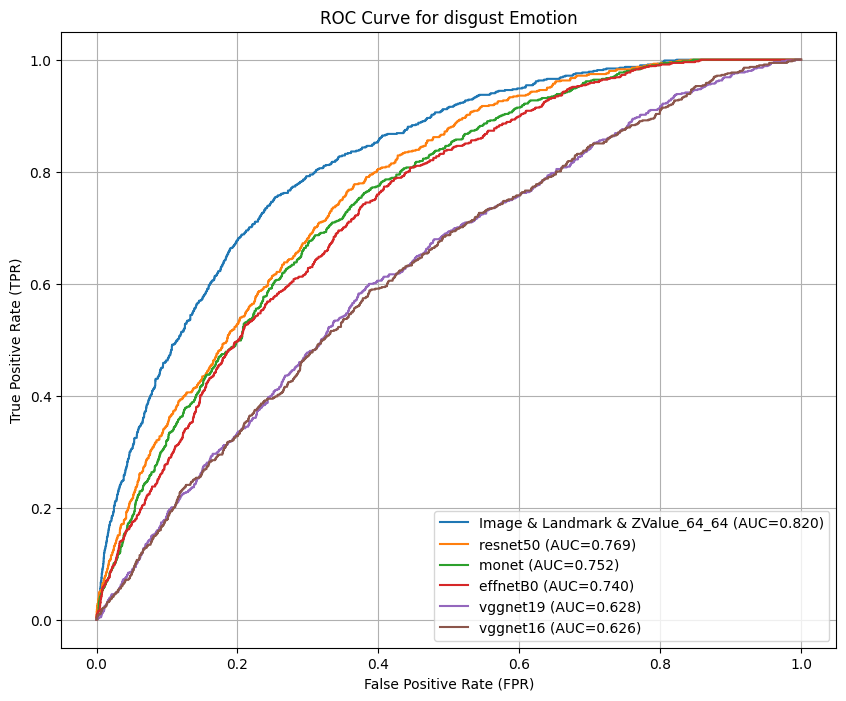

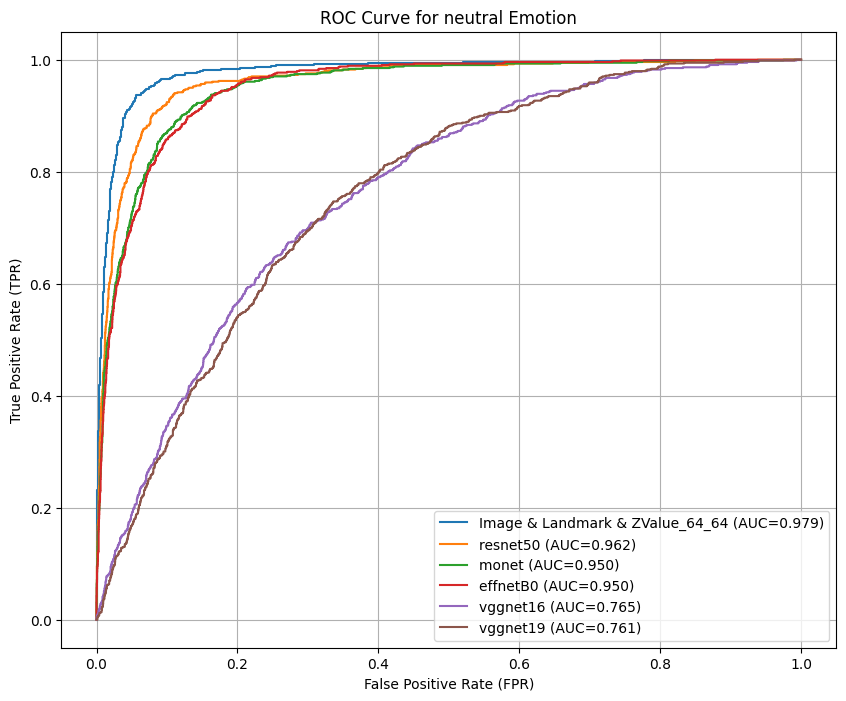

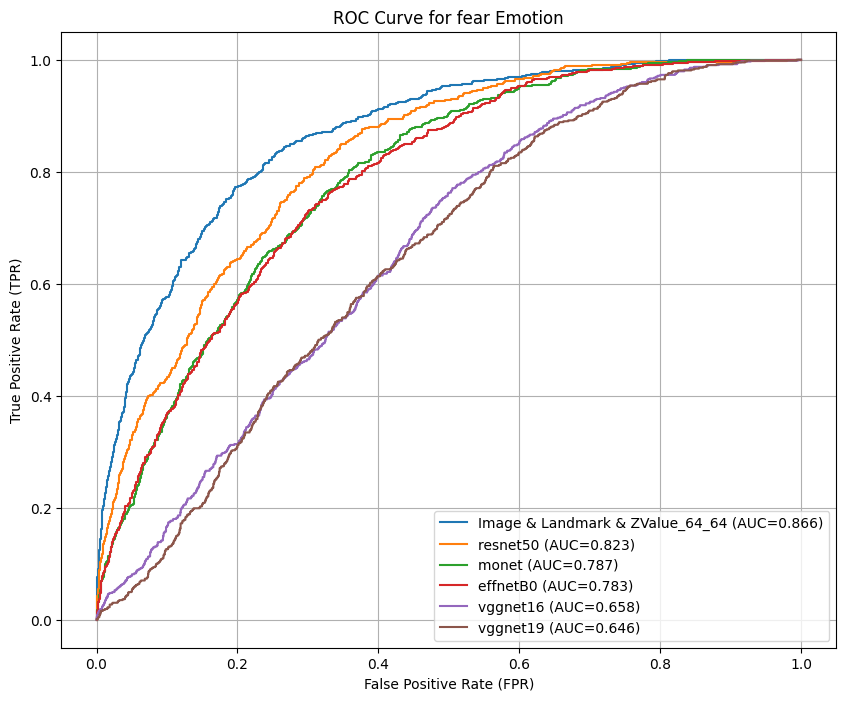

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 파일 목록
roc_files = [
    '/content/drive/MyDrive/02_04_new/Image & Landmark & ZValue_64_64_roc_curve_data.csv',
    '/content/drive/MyDrive/FINAL/monet_roc_curve_data.csv', '/content/drive/MyDrive/FINAL/resnet50_roc_curve_data.csv',
    '/content/drive/MyDrive/FINAL/vggnet16_roc_curve_data.csv', '/content/drive/MyDrive/FINAL/vggnet19_roc_curve_data.csv', '/content/drive/MyDrive/FINAL/effnetB0_roc_curve_data.csv'
]

# 감정 목록
emotions = ["happy", "sad", "anger", "surprise", "disgust", "neutral", "fear"]

# ROC 커브 데이터 저장
roc_data = {}

for emotion in emotions:
    plt.figure(figsize=(10, 8))

    model_data = []
    for file in roc_files:
        df = pd.read_csv(file)
        model_name = file.split('/')[-1].split('_roc_curve_data.csv')[0]  # Extract model name from file path
        df['Emotion'] = df['Emotion'].str.lower()
        emotion_data = df[df['Emotion'] == emotion]


        # Check if 'FPR' exists in emotion_data
        if 'FPR' in emotion_data.columns:
            fpr = emotion_data['FPR']
            tpr = emotion_data['TPR']
            auc = np.mean(emotion_data['AUC'])
            model_data.append((model_name, fpr, tpr, auc))
        else:
            print(f"Column 'FPR' not found in {file}")

    model_data.sort(key=lambda x: x[3], reverse=True)

    for model_name, fpr, tpr, auc in model_data:
        plt.plot(fpr, tpr, label=f'{model_name} (AUC={auc:.3f})')

    plt.xlabel('False Positive Rate (FPR)')
    plt.ylabel('True Positive Rate (TPR)')
    plt.title(f'ROC Curve for {emotion} Emotion')
    plt.legend()
    plt.grid(True)
    plt.show()



## Model architecture

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-6ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 18 not upgraded.


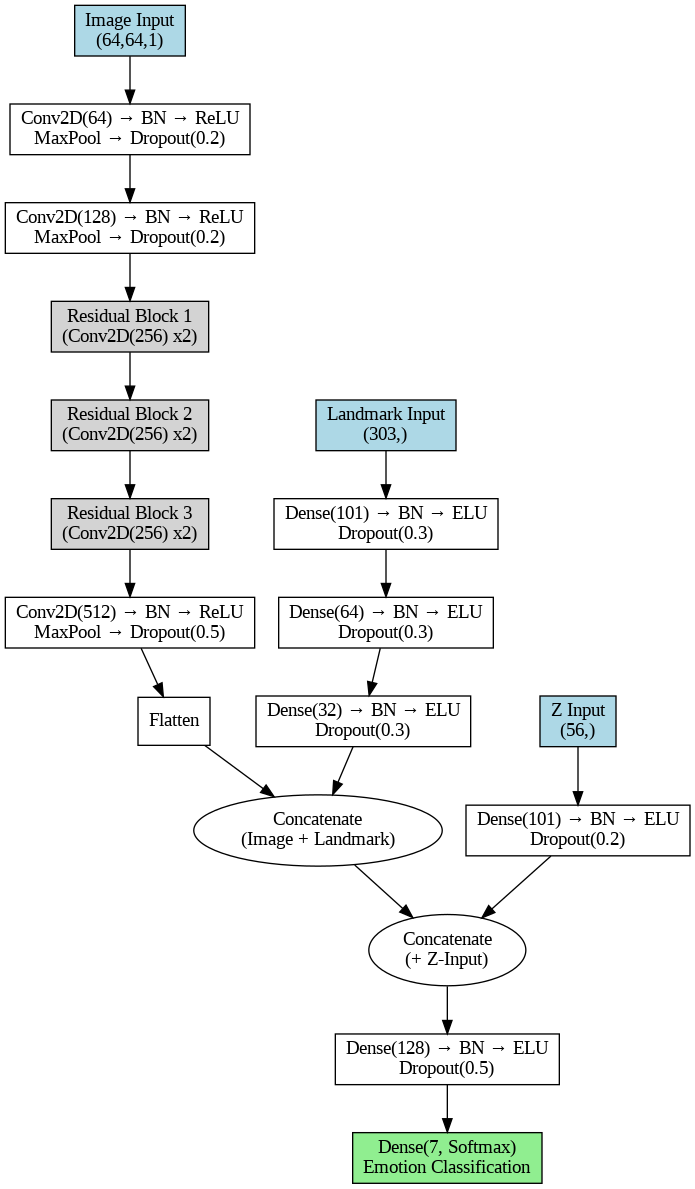

In [ ]:
# Graphviz 설치 (Colab 환경)
!apt-get install graphviz
!pip install graphviz

import graphviz

# 모델 구조 다이어그램 정의
dot = graphviz.Digraph(format='png', engine='dot')

# 입력 레이어
dot.node('Image Input', 'Image Input\n(64,64,1)', shape='box', style='filled', fillcolor='lightblue')
dot.node('Landmark Input', 'Landmark Input\n(303,)', shape='box', style='filled', fillcolor='lightblue')
dot.node('Z Input', 'Z Input\n(56,)', shape='box', style='filled', fillcolor='lightblue')

# 이미지 서브넷
dot.node('Conv1', 'Conv2D(64) → BN → ReLU\nMaxPool → Dropout(0.2)', shape='box')
dot.node('Conv2', 'Conv2D(128) → BN → ReLU\nMaxPool → Dropout(0.2)', shape='box')

# Residual 블록
for i in range(3):
    dot.node(f'ResBlock{i+1}', f'Residual Block {i+1}\n(Conv2D(256) x2)', shape='box', style='filled', fillcolor='lightgray')

dot.node('Conv3', 'Conv2D(512) → BN → ReLU\nMaxPool → Dropout(0.5)', shape='box')
dot.node('Flatten', 'Flatten', shape='box')

# 랜드마크 서브넷
dot.node('Dense1', 'Dense(101) → BN → ELU\nDropout(0.3)', shape='box')
dot.node('Dense2', 'Dense(64) → BN → ELU\nDropout(0.3)', shape='box')
dot.node('Dense3', 'Dense(32) → BN → ELU\nDropout(0.3)', shape='box')

# Z-값 서브넷
dot.node('Dense_Z', 'Dense(101) → BN → ELU\nDropout(0.2)', shape='box')

# 합치기 & 출력
dot.node('Concat1', 'Concatenate\n(Image + Landmark)', shape='ellipse')
dot.node('Concat2', 'Concatenate\n(+ Z-Input)', shape='ellipse')
dot.node('Dense_Final', 'Dense(128) → BN → ELU\nDropout(0.5)', shape='box')
dot.node('Output', 'Dense(7, Softmax)\nEmotion Classification', shape='box', style='filled', fillcolor='lightgreen')

# 연결
dot.edge('Image Input', 'Conv1')
dot.edge('Conv1', 'Conv2')
dot.edge('Conv2', 'ResBlock1')
dot.edge('ResBlock1', 'ResBlock2')
dot.edge('ResBlock2', 'ResBlock3')
dot.edge('ResBlock3', 'Conv3')
dot.edge('Conv3', 'Flatten')
dot.edge('Flatten', 'Concat1')

dot.edge('Landmark Input', 'Dense1')
dot.edge('Dense1', 'Dense2')
dot.edge('Dense2', 'Dense3')
dot.edge('Dense3', 'Concat1')

dot.edge('Concat1', 'Concat2')
dot.edge('Z Input', 'Dense_Z')
dot.edge('Dense_Z', 'Concat2')

dot.edge('Concat2', 'Dense_Final')
dot.edge('Dense_Final', 'Output')

# 다이어그램 출력
dot.render('model_architecture', format='png', cleanup=False)
from IPython.display import Image
Image('model_architecture.png')


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/loc

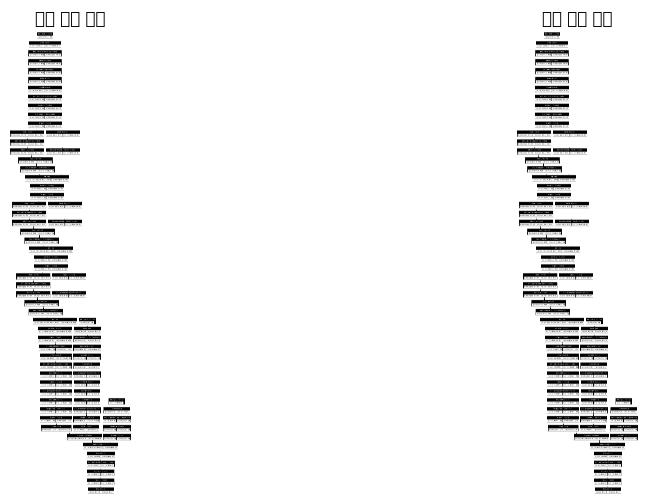

In [ ]:
import tensorflow as tf
from tensorflow.keras.utils import plot_model
import matplotlib.pyplot as plt

# 🔹 모델 로드 (경로에 맞게 수정)
model_path = "/content/drive/MyDrive/02_04_new/Image & Landmark & ZValue_64_64_model.keras"  # 또는 .h5 파일
model = tf.keras.models.load_model(model_path, compile=False)

# 🔹 모델 구조도 저장 경로
model_structure_path = "/content/model_structure.png"
model_structure_large_path = "/content/model_structure_large.png"

# 🔹 모델 구조도 저장 (기본)
plot_model(model, to_file=model_structure_path, show_shapes=True, show_layer_names=True)

# 🔹 모델 구조도 저장 (세부 구조 포함)
plot_model(model, to_file=model_structure_large_path, show_shapes=True, show_layer_names=True, expand_nested=True)

# 🔹 시각화
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# 🔹 기본 모델 구조도 출력
img_basic = plt.imread(model_structure_path)
ax[0].imshow(img_basic)
ax[0].axis("off")
ax[0].set_title("기본 모델 구조")

# 🔹 상세 모델 구조도 출력
img_large = plt.imread(model_structure_large_path)
ax[1].imshow(img_large)
ax[1].axis("off")
ax[1].set_title("세부 모델 구조")

plt.show()
